<a href="https://colab.research.google.com/github/QbdulloK/NLP-message-user-predictor/blob/main/NLP_New_best.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **NLP User message predictor:**
**The aim of this project is to predict which of my 3 friends sent a message.**

**The model (RuBERT) will only receive the message as input, with no context.**

**To collect the dataset, I collected about 2,500 messages in total from Telegram (an online messaging app).**

**The main challenge was that sometimes there is really no way to tell which person wrote a specific message, either because of a lack of words or because of similar or universal styles.**

**Despite this, my model managed to achieve high accuracy, which shows that it can differentiate between people significantly better than random guessing.**

In [1]:
# Importing all useful libraries:
import os
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
import copy
from sklearn.metrics import f1_score, classification_report
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup, get_cosine_schedule_with_warmup)
import gdown
os.makedirs('nlp_texts_friends', exist_ok=True)

# Data:
gdown.download('https://drive.google.com/uc?id=1Q74rXmxftepihoXcAlYFSvcINje1AOH1', 'nlp_texts_friends/NLP_Data.txt', quiet=False)

with open('nlp_texts_friends/NLP_Data.txt', 'r', encoding='utf-8') as f:
    all_data = f.read()

Downloading...
From: https://drive.google.com/uc?id=1Q74rXmxftepihoXcAlYFSvcINje1AOH1
To: /content/nlp_texts_friends/NLP_Data.txt
100%|██████████| 152k/152k [00:00<00:00, 12.3MB/s]


# **Generating more data using a "sliding window":**

**Currently, many messages in the dataset are short. If I used them directly as training data, it would be difficult for the model to learn the "style" of each user from a message that may not contain much information.**

**That is why using a sliding window is the best option. It generates additional windows by grouping messages. Instead of using only one message, it takes several messages in a row and combines them into one (with limits on how many messages can be in a row and on the maximum length of a window). This produces longer messages that are more informative for the model.**

In [2]:
# This function is useful for generating more data using a "sliding window":
def group_consecutive_messages_sliding(messages_list, max_chars, max_messages, stride):
    grouped_messages = []
    n = len(messages_list)
    i = 0
    while i < n:
        current_block = []
        current_len = 0
        j = i
        while j < n and current_len + len(messages_list[j]) <= max_chars and len(current_block) < max_messages:
            current_block.append(messages_list[j])
            current_len += len(messages_list[j]) + 1
            j += 1
        if current_block:
            grouped_messages.append(" ".join(current_block))
        i += max(1, stride)
        if j == n and i >= n:
            break
    return grouped_messages

In [3]:
# The function is_laughter is supposed to (with high precision) determine if a message was someone laughing or not:
# Usually a laughter consists of "ах" or "ха" but I included some letters which are closeby in the keyboard (typos)
laughter_symbols = ['хах', 'аха', 'пхп', 'пзп', 'аза', 'пха', 'хха']
add_laughter = ['ах', 'ха', 'хах', 'аха', 'хаха', 'ахах']
def is_laughter(w):
    wl = w.lower().strip('.,!?')
    if len(wl) < 2:
        return False
    sentences = w.split()
    for i, word in enumerate(sentences):
        word_low = word.lower()
        if (word_low.count('а') + word_low.count('х') + word_low.count('п') + word_low.count('з')) / len(word) >= 0.6:
            for elem in laughter_symbols:
                if elem in word_low:
                    sentences[i] = word + add_laughter[random.randint(0, len(add_laughter) - 1)]
                    return True, ' '.join(sentences)
    return False, ''

# **Creating Augmented Messages:**

**This function receives some text and tries to create a new "similar" message (augmentation).**

**The main challenge at first was to avoid augmentation methods that could damage the dataset.**

**The safest augmentation methods I used (which don't really lose valuable information or give fake signals to the model) were:**

**- adding typos**

**- making the whole message lowercase**

**- adding extra letters when someone was laughing (for example, хах --> хахах)**

**- removing punctuation**

**- swapping two words that are next to each other**

**Some *unsafe* options were *adding "filler" words*, *adding* a period (.) at the end of the message, *capitalizing* words, *repeating* a letter multiple times in a message (for instance, "привет" --> "привеееет"), ...**

**The *problem* with such augmentation methods was that they could potentially confuse the model. For example, let's say *USER 1* really liked to add a period at the end of the message, but *USER 2* never did that. Then adding such augmented messages would cause the model to lose valuable information and would confuse it.**

In [4]:
def augment_telegram_style(text):
    if len(text) < 12:
        return '-1'

    words = text.split()
    aug_type = random.choice(['typo', 'lowercase', 'laughter', 'punct_drop', 'swap_words'])

    if aug_type == 'typo' and len(words) > 0:
        ru_keyboard = {'а': 'кевпсм', 'б': 'лдью', 'в': 'укыачс', 'г': 'ншро',
            'д': 'щзлжбю', 'е': 'кнпр', 'ё': '1йф', 'ж': 'зхдэю',
            'з': 'щхдж', 'и': 'прмт', 'й': 'цф', 'к': 'уеап',
            'л': 'шщодбь', 'м': 'апси', 'н': 'егпр', 'о': 'гшрлть',
            'п': 'енарми', 'р': 'нгпоит', 'с': 'вачм', 'т': 'роить',
            'у': 'цкыв', 'ф': 'йцыя', 'х': 'зъжэ', 'ц': 'йуфы',
            'ч': 'ывяс', 'ш': 'гщол', 'щ': 'шзлд', 'ъ': 'хэ',
            'ы': 'цуфвяч', 'ь': 'олтб', 'э': 'хъжю', 'ю': 'джб', 'я': 'фыч'}
        word_idx = random.randint(0, len(words) - 1)
        w = list(words[word_idx])
        if len(w) > 3:
            char_idx = random.randint(1, len(w) - 2)
            ch = w[char_idx].lower()
            if ch in ru_keyboard:
                w[char_idx] = random.choice(ru_keyboard[ch])
                words[word_idx] = "".join(w)
                return " ".join(words)

    elif aug_type == 'lowercase':
        return text.lower()

    elif aug_type == 'laughter':
        flag, new_sentence = is_laughter(text)
        if not flag:
            return '-1'
        return new_sentence

    elif aug_type == 'punct_drop':
        stripped = text.rstrip('.!?,')
        if stripped == text:
            return '-1'
        return stripped

    elif aug_type == 'swap_words' and len(words) >= 3:
        i = random.randint(0, len(words) - 2)
        words[i], words[i + 1] = words[i + 1], words[i]
        return " ".join(words)

    return '-1'

In [5]:
# Useful helper functions to plot graphs with matplotlib:

def plot_length_histogram(df, title):
    length_numbers = ['100', '125', '150', '175', '200', '225', '250', '275', '300', '325', '350', '375', '400']
    values = []
    for val in length_numbers:
        values.append(len(df[df['text'].str.len() >= int(val)]))

    bars = plt.bar(length_numbers, values, color='skyblue')
    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width() / 2, yval, str(yval), ha='center', va='bottom', fontsize=9)

    plt.title(title, fontsize=14)
    plt.xlabel("Length")
    plt.ylabel("Amount of Messages")
    plt.ylim(0, max(values) * 1.05 if max(values) > 0 else 1)
    plt.show()


def plot_confidence_thresholds(probabilities, predictions, test_labels):
    thresholds = [0, 50, 60, 70, 75, 80, 90, 95, 99, 99.5, 99.75, 99.99]
    confidence_accs = []
    confidence_counts = []
    threshold_have = []

    for t in thresholds:
        win = 0
        total = 0
        for i in range(len(test_labels)):
            trust = probabilities[i].max()
            if trust * 100 >= t:
                if predictions[i] == test_labels[i]:
                    win += 1
                total += 1
        if total == 0:
            break
        threshold_have.append(t)
        confidence_accs.append(round(win / total * 100, 1))
        confidence_counts.append((win, total))

    x_pos = np.arange(len(threshold_have))
    plt.figure(figsize=(14, 7))
    bars = plt.bar(x_pos, confidence_accs, width=0.65, color='skyblue', edgecolor='black')

    for i, bar in enumerate(bars):
        height = bar.get_height()
        win, total = confidence_counts[i]
        text_label = str(win) + "/" + str(total) + "\n" + str(height) + "%"
        plt.text(bar.get_x() + bar.get_width() / 2, height + 1, text_label, ha='center', va='bottom', fontsize=11)

    plt.title('Confidence-Based Accuracy (Correct / Total Predictions)', fontsize=16)
    plt.xlabel('Confidence Threshold (%)', fontsize=12)
    plt.ylabel('Accuracy (%)', fontsize=12)
    plt.xticks(x_pos, threshold_have)
    plt.grid(axis='y', linestyle='--')
    plt.ylim(0, 115)
    plt.tight_layout()
    plt.show()

def plot_confusion_matrix(encoded, pred, le):
    # Confusion Matrix
    cm_s1 = confusion_matrix(encoded, pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm_s1, annot=True, fmt='d', cmap='Blues',
                xticklabels=le.classes_,
                yticklabels=le.classes_,
                annot_kws={"size": 14})
    plt.title('Confusion Matrix (Before Fine-Tuning)', fontsize=16)
    plt.xlabel('Predicted Label', fontsize=13, labelpad=10)
    plt.ylabel('True Label', fontsize=13, labelpad=10)
    plt.xticks(fontsize=11)
    plt.yticks(fontsize=11)
    plt.tight_layout()
    plt.show()

def plot_train_loss_val_acc_stage1(history_loss_s1, history_accuracy_s1):
    epochs_range_s1 = range(1, len(history_loss_s1) + 1)
    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs_range_s1, history_loss_s1, label='Train Loss', color='red', linewidth=2, marker='o')
    plt.title('Stage 1 (Frozen BERT): Training Loss per Epoch', fontsize=14)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.grid(True)
    plt.legend(fontsize=11)

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range_s1, history_accuracy_s1, label='Validation Accuracy', color='green', linewidth=2, marker='o')
    plt.title('Stage 1 (Frozen BERT): Validation Accuracy per Epoch', fontsize=14)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Accuracy', fontsize=12)
    plt.ylim(0, 1.05)
    plt.grid(True)
    plt.legend(fontsize=11)

    plt.tight_layout()
    plt.show()

def plot_train_loss_val_acc_stage2(history_loss, history_accuracy, test_acc_s1):
    epochs_range = range(1, len(history_loss) + 1)
    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, history_loss, label='Train Loss', color='red', linewidth=2, marker='o')
    plt.title('Stage 2: Training Loss per Epoch', fontsize=14)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.grid(True)
    plt.legend(fontsize=11)

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, history_accuracy, label='Validation Accuracy', color='green', linewidth=2, marker='o')
    plt.axhline(y=test_acc_s1, color='blue', linestyle='--', label=f'Stage 1 Test Acc ({round(test_acc_s1*100,1)}%)')
    plt.title('Stage 2: Validation Accuracy per Epoch', fontsize=14)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Accuracy', fontsize=12)
    plt.ylim(0, 1.05)
    plt.grid(True)
    plt.legend(fontsize=11)

    plt.tight_layout()
    plt.show()

def plot_confidence_before_after_finetuning(conf_before, conf_after, test_labels):
    x = np.arange(1, min(50, len(test_labels)) + 1)
    plt.figure(figsize=(14, 6))
    plt.bar(x - 0.2, conf_before[0:min(50, len(test_labels))], width=0.4, label='Before Fine-Tuning', color='skyblue')
    plt.bar(x + 0.2, conf_after[0:min(50, len(test_labels))], width=0.4, label='After Fine-Tuning', color='lightgreen')
    plt.title('Comparison of Model Confidence per Message (Before vs After Fine-Tuning)', fontsize=16, fontweight='bold', pad=15)
    plt.xticks(x)
    plt.ylabel('Confidence (%)')
    plt.xlabel('Message #')
    plt.legend()
    plt.show()

# **Reading the messages:**

**The dataset looks something like this:**

**USER 1:**

**...**

**...**

**USER 2:**

**...**

**...**

**USER 3:**

**...**

**...**

**The dataset is easier to interpret like this. Each user will have their own array where all of their messages are stored.**

*note: There won't be any data leakage because each user's messages will be split randomly into 70%/15%/15% train/val/test sets (the model won't see the data with "USER _:" in it).*

In [6]:
def read_messages(all_data, users_activated):
    lines = all_data.split('\n')
    min_length_messages = 10 # Minimum length per message

    all_users = ['USER 1:', 'USER 2:', 'USER 3:'] # 3 Users (the code can be changed to allow any amount of users)
    all_user_names = ['USER 1', 'USER 2', 'USER 3']

    people = [all_users[i] for i in range(len(all_users)) if users_activated[i]]
    people_name = [all_user_names[i] for i in range(len(all_user_names)) if users_activated[i]]
    # user activated could be True/False if the person is included or not in the dataset
    amount_people = len(people_name)
    person_numb = -1
    raw_messages = [[] for _ in range(amount_people)]

    for line in lines:
        line_str = line.strip()
        if line_str in all_users:
            if line_str in people:
                person_numb = people.index(line_str)
            else:
                person_numb = -1
        elif person_numb != -1 and len(line_str) >= min_length_messages:
            raw_messages[person_numb].append(line_str)
    return raw_messages, people_name

**This function takes the data returned by read_messages(...) and splits it into train/val/test sets for each person individually.**

In [7]:
def create_train_val_test_split(raw_messages, people_name, seed_number, train_val_test_split, maximum_char, max_amount_msg, strides):
    amount_people = len(people_name)
    counts = [len(raw_messages[i]) for i in range(amount_people)]

    train_messages, val_messages, test_messages = [], [], []
    train_labels, val_labels, test_labels = [], [], []

    size_test = train_val_test_split[2] / 100
    size_val_after = (train_val_test_split[1] / 100) / (1 - train_val_test_split[2] / 100)

    for i in range(amount_people):
        # For every user:
        user_raw = raw_messages[i]
        user_name = people_name[i]

        # Splitting the data into train/val/test:
        u_train_raw, u_test_raw = train_test_split(user_raw, test_size=size_test, random_state=seed_number)
        u_train_raw, u_val_raw = train_test_split(u_train_raw, test_size=size_val_after, random_state=seed_number)

        # Using sliding windows to generate more messages:
        u_train_blocks = group_consecutive_messages_sliding(u_train_raw, max_chars=maximum_char, max_messages=max_amount_msg, stride=strides[0])
        u_val_blocks = group_consecutive_messages_sliding(u_val_raw, max_chars=maximum_char, max_messages=max_amount_msg, stride=strides[1])
        u_test_blocks = group_consecutive_messages_sliding(u_test_raw, max_chars=maximum_char, max_messages=max_amount_msg, stride=strides[2])

        print(user_name + ':', len(u_train_blocks), 'train,', len(u_val_blocks), 'val,', len(u_test_blocks), 'test blocks (out of', len(user_raw), 'original messages)')

        train_messages.extend(u_train_blocks)
        train_labels.extend([user_name] * len(u_train_blocks))

        val_messages.extend(u_val_blocks)
        val_labels.extend([user_name] * len(u_val_blocks))

        test_messages.extend(u_test_blocks)
        test_labels.extend([user_name] * len(u_test_blocks))

    return train_messages, train_labels, val_messages, val_labels, test_messages, test_labels

**The function below receives each message from the training dataset and uses the function *augment_telegram_style(text)* to augment the messages.**

**The function uses a *while loop* to keep creating new augmented messages until it roughly reaches the "percentage_augmentation" target (for example, 30%).**

In [10]:
def create_augmented_text(train_messages, train_labels, percentage_augmentation, use_augment, people_name):
    # Augmentation
    if use_augment:
        augmented_messages, augmented_labels = [], []
        for user_name in people_name:
            user_train_msgs = [msg for msg, lbl in zip(train_messages, train_labels) if lbl == user_name]

            target_count = int(len(user_train_msgs) * percentage_augmentation / 100)
            added, attempts = 0, 0
            while added < target_count and attempts < target_count * 10:
                attempts += 1
                base_msg = random.choice(user_train_msgs)
                aug_msg = augment_telegram_style(base_msg)
                if aug_msg != '-1':  # if the augmentation worked
                    augmented_messages.append(aug_msg)
                    augmented_labels.append(user_name)
                    added += 1
        train_messages += augmented_messages
        train_labels += augmented_labels
        print('Added', len(augmented_messages), 'Telegram-like samples')
    else:
        print('Added 0 Telegram-like samples')

    return train_messages, train_labels

# **Running the model:**

**This is the main function that runs the entire code with tunable starting conditions.**

**The function consists of:**

# **1) Reading the data**

# **2) Splitting the data into Train/Val/Test sets and generating more messages using the sliding window trick.**

**(The code uses a 70%/15%/15% split, and for the window, it uses parameters *Max_Message_Length = 400*, *Max_Amount_Messages = 12*, *Stride train/val/test = 1, 2, 2*).**

# **3) Adding an additional 30% of the messages from the training data using augmentation**

# **4) Downloading the pretrained RuBERT model from Hugging Face and tokenizing the messages with a limit of 140 tokens (the longest message only had 138 tokens).**

# **5) Freezing the RuBERT model and training only the head of the model (Stage 1 learning)**

*epochs=12, lr=4e-4, uses a linear scheduler, CrossEntropyLoss function, gradient clipping (1.0; to prevent exploding gradients), calculates train loss and validation accuracy, and saves the best model using validation accuracy.*

# **6) Unfreezing the ENTIRE RuBERT model and training every layer (Stage 2 fine-tuning)**

*epochs=10, lr=3e-6, weight_decay=0.1, cosine scheduler, patience (early stopping), CrossEntropyLoss, gradient clipping, calculates validation accuracy to determine the best model.*

# **7) Showing the results (final accuracy and F1 scores) of the entire project.**

**In addition, this function uses the helper functions above to plot useful graphs.**

In [11]:
def run_model_simulation(use_augment, seed_number, users_activated, verbose_, dropout_rate):
    #
    random.seed(seed_number)
    np.random.seed(seed_number)
    torch.manual_seed(seed_number)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed_number)
    #
    with open('nlp_texts_friends/NLP_Data.txt', 'r', encoding='utf-8') as f:
        all_data = f.read()
    #
    raw_messages, people_name = read_messages(all_data, users_activated)
    #
    amount_people = len(people_name)
    counts = [len(raw_messages[i]) for i in range(amount_people)]

    # Train/Val/Test split = 70%/15%/15%
    # Max_Message_Length = 400
    # Max_Amount_Messages = 12
    # Stride_train = 1; Stride_val, Stride_Test = 2
    train_messages, train_labels, val_messages, val_labels, test_messages, test_labels = create_train_val_test_split(
        raw_messages, people_name, seed_number, [70, 15, 15], 400, 12, [1, 2, 2])
    #
    print("-------------------------------------------------")
    print('Train samples:', len(train_messages), 'Avg len:', round(sum(len(m) for m in train_messages)/len(train_messages), 1), 'chars')
    print('Val samples:', len(val_messages), 'Avg len:', round(sum(len(m) for m in val_messages)/len(val_messages), 1), 'chars')
    print('Test samples:', len(test_messages), 'Avg len:', round(sum(len(m) for m in test_messages)/len(test_messages), 1), 'chars')
    print("-------------------------------------------------")

    if verbose_:
        plt.bar(people_name, counts, color=['skyblue', 'red', 'lightgreen'])
        plt.title("The number of messages per user")
        plt.xlabel("Users")
        plt.ylabel("Amount of Messages")
        plt.show()

    # 30% Augmentation
    train_messages, train_labels = create_augmented_text(train_messages, train_labels, 30, use_augment, people_name)
    #

    train_df = pd.DataFrame({'text': train_messages, 'label': train_labels}).drop_duplicates(subset=['text']).reset_index(drop=True)
    val_df = pd.DataFrame({'text': val_messages, 'label': val_labels})
    test_df = pd.DataFrame({'text': test_messages, 'label': test_labels})

    if verbose_:
        plot_length_histogram(train_df, "The number of messages over a certain length (Training Data)")
        plot_length_histogram(test_df, "The number of messages over a certain length (Test Data)")

    le = LabelEncoder()
    train_df['label'] = le.fit_transform(train_df['label'])
    val_labels_encoded = le.transform(val_df['label'])
    test_labels_encoded = le.transform(test_df['label'])

    tokenizer = AutoTokenizer.from_pretrained('DeepPavlov/rubert-base-cased')

    # 140 was just above the largest message in tokens. It's the perfect amount
    train_enc = tokenizer(train_df['text'].tolist(), padding=True, truncation=True, max_length=140, return_tensors='pt')
    val_enc = tokenizer(val_df['text'].tolist(), padding=True, truncation=True, max_length=140, return_tensors='pt')
    test_enc = tokenizer(test_df['text'].tolist(), padding=True, truncation=True, max_length=140, return_tensors='pt')

    train_dataset = TensorDataset(train_enc['input_ids'], train_enc['attention_mask'], torch.LongTensor(train_df['label'].values))
    val_dataset = TensorDataset(val_enc['input_ids'], val_enc['attention_mask'], torch.LongTensor(val_labels_encoded))

    # Batch size of 16:
    train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    num_classes = len(people_name)
    model = AutoModelForSequenceClassification.from_pretrained('DeepPavlov/rubert-base-cased',
        num_labels=num_classes,
        hidden_dropout_prob=dropout_rate,
        attention_probs_dropout_prob=dropout_rate).to(device)

    # Stage 1: Frozen Bert; train only the classifier head
    for param in model.bert.parameters():
        param.requires_grad = False

    optimizer_s1 = torch.optim.AdamW(model.classifier.parameters(), lr=4e-4)
    epochs_stage1 = 12
    total_steps_s1 = len(train_loader) * epochs_stage1
    scheduler_s1 = get_linear_schedule_with_warmup(optimizer_s1, num_warmup_steps=int(total_steps_s1 * 0.1), num_training_steps=total_steps_s1)

    best_score = -1
    best_state_s1 = None
    history_loss_s1, history_accuracy_s1 = [], []
    print("Training Frozen Bert:")
    loss_fct = torch.nn.CrossEntropyLoss()

    for epoch in range(epochs_stage1):
        model.train()
        total_loss = 0
        for batch in tqdm(train_loader):
            optimizer_s1.zero_grad()
            outputs = model(input_ids=batch[0].to(device), attention_mask=batch[1].to(device))
            loss = loss_fct(outputs.logits, batch[2].to(device))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer_s1.step()
            scheduler_s1.step()
            total_loss += loss.item()

        model.eval()
        val_preds, val_targets = [], []
        with torch.no_grad():
            for batch in val_loader:
                out = model(input_ids=batch[0].to(device), attention_mask=batch[1].to(device), labels=batch[2].to(device))
                preds_b = torch.argmax(out.logits, dim=1).cpu().numpy()
                val_preds.extend(preds_b)
                val_targets.extend(batch[2].numpy())

        acc = accuracy_score(val_targets, val_preds)
        history_loss_s1.append(total_loss / len(train_loader))
        history_accuracy_s1.append(acc)
        print(epoch + 1, 'Train loss =', round(total_loss / len(train_loader), 4), 'Val accuracy =', str(round(acc * 100, 2)) + '%')

        if acc > best_score:
            best_score = acc
            best_state_s1 = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state_s1)

    model.eval()
    with torch.no_grad():
        test_out_s1 = model(input_ids=test_enc['input_ids'].to(device), attention_mask=test_enc['attention_mask'].to(device))
        test_probs_s1 = torch.softmax(test_out_s1.logits, dim=1).cpu().numpy()
        test_preds_s1 = np.argmax(test_probs_s1, axis=1)
        test_acc_s1 = accuracy_score(test_labels_encoded, test_preds_s1)

    print("-------------------------------------------------")
    print("Stage 1 test Accuracy (FC Only):", str(round(test_acc_s1 * 100, 2)) + '%')
    print(classification_report(test_labels_encoded, test_preds_s1, target_names=le.classes_))
    print("-------------------------------------------------")
    conf_before = []

    if verbose_:
        predictions_s1 = le.inverse_transform(test_preds_s1)

        # Guesses after Stage 1
        print("Guesses:")
        for i in range(len(predictions_s1)):
            if i <= 10 or i >= len(predictions_s1) - 10:
                print('Message #' + str(i + 1))
                print('  Guess:', predictions_s1[i])
                print("  Confidence by users:")
            for j, cls in enumerate(le.classes_):
                if cls == predictions_s1[i]:
                    conf_before.append(round(100 * test_probs_s1[i][j], 2))
                if i <= 10 or i >= len(predictions_s1) - 10:
                    print('    ' + cls + ':', str(round(100 * test_probs_s1[i][j], 2)) + '%')
        print('-----------------------------------------')
        print('Accuracy:', str(round(100 * accuracy_score(predictions_s1, test_labels), 2)) + '%')


        # Confusion Matrix (Stage 1, before fine-tuning)
        plot_confusion_matrix(test_labels_encoded, test_preds_s1, le)

        # Stage 1: loss и val accuracy
        plot_train_loss_val_acc_stage1(history_loss_s1, history_accuracy_s1)

    # STAGE 2: full fine-tuning
    for param in model.parameters():
        param.requires_grad = True

    optimizer_s2 = torch.optim.AdamW(model.parameters(), lr=3e-6, weight_decay=0.1)
    epochs_stage2 = 10
    total_steps_s2 = len(train_loader) * epochs_stage2
    scheduler_s2 = get_cosine_schedule_with_warmup(optimizer_s2, num_warmup_steps=int(total_steps_s2 * 0.1), num_training_steps=total_steps_s2)

    history_loss, history_accuracy = [], []
    patience = 4
    wait = 0
    best_score = -1
    best_state_s2 = None  # in-memory checkpoint instead of torch.save
    loss_fct = torch.nn.CrossEntropyLoss()
    print("Full Fine-Tuning:")

    for epoch in range(epochs_stage2):
        model.train()
        total_loss = 0
        for batch in tqdm(train_loader):
            optimizer_s2.zero_grad()
            outputs = model(input_ids=batch[0].to(device), attention_mask=batch[1].to(device))
            loss = loss_fct(outputs.logits, batch[2].to(device))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer_s2.step()
            scheduler_s2.step()
            total_loss += loss.item()

        model.eval()
        val_preds, val_targets = [], []
        with torch.no_grad():
            for batch in val_loader:
                out = model(input_ids=batch[0].to(device), attention_mask=batch[1].to(device), labels=batch[2].to(device))
                preds_b = torch.argmax(out.logits, dim=1).cpu().numpy()
                val_preds.extend(preds_b)
                val_targets.extend(batch[2].numpy())

        acc = accuracy_score(val_targets, val_preds)

        history_loss.append(total_loss / len(train_loader))
        history_accuracy.append(acc)
        print(epoch + 1, 'Train loss =', round(total_loss / len(train_loader), 4), 'Val accuracy =', str(round(acc * 100, 2)) + '%')
        if acc > best_score:
            best_score = acc
            best_state_s2 = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print('Early Stopping', epoch)
                break

    model.load_state_dict(best_state_s2)

    model.eval()
    with torch.no_grad():
        test_out = model(input_ids=test_enc['input_ids'].to(device), attention_mask=test_enc['attention_mask'].to(device))
        probabilities = torch.softmax(test_out.logits, dim=1).cpu().numpy()
        preds = np.argmax(probabilities, axis=1)

    final_test_acc = accuracy_score(test_labels_encoded, preds)
    final_f1_macro = f1_score(test_labels_encoded, preds, average='macro')

    if verbose_:
        # Stage 2: loss и val accuracy
        plot_train_loss_val_acc_stage2(history_loss, history_accuracy, test_acc_s1)

    print("=========================================")
    print("STAGE 1 Test Accuracy:", str(round(test_acc_s1 * 100, 2)) + "%")
    print("FINAL Test Accuracy (After FT):", str(round(final_test_acc * 100, 2)) + "%")
    print("FINAL F1-macro:", str(round(final_f1_macro * 100, 2)) + "%")
    print("Improvement: +" + str(round((final_test_acc - test_acc_s1) * 100, 2)) + "%")
    print(classification_report(test_labels_encoded, preds, target_names=le.classes_))
    print("=========================================")

    conf_after = []

    if verbose_:
        predictions = le.inverse_transform(preds)

        # Guesses after Stage 2
        print("Guesses:")
        for i in range(len(predictions)):
            if i <= 10 or i >= len(predictions) - 10:
                print('Message #' + str(i + 1))
                print('  Guess:', predictions[i])
                print("  Confidence by users:")
            for j, cls in enumerate(le.classes_):
                if cls == predictions[i]:
                    conf_after.append(round(100 * probabilities[i][j], 2))
                if i <= 10 or i >= len(predictions) - 10:
                    print('    ' + cls + ':', str(round(100 * probabilities[i][j], 2)) + '%')
        print('-----------------------------------------')
        print('Accuracy:', str(round(100 * accuracy_score(predictions, test_labels), 2)) + '%')

        # Confidence threshold
        plot_confidence_thresholds(probabilities, predictions, test_labels)

        # Confusion Matrix (After Fine-Tuning)
        plot_confusion_matrix(test_labels_encoded, preds, le)

        # Bar chart: model confidence before and after fine-tuning
        plot_confidence_before_after_finetuning(conf_before, conf_after, test_labels)

    return model, tokenizer, le, final_test_acc


# **Running one experiment(verbose=True, dropout=0.1, seed=42):**

------------------------------------
Seed: 42
------------------------------------
USER 1: 664 train, 72 val, 72 test blocks (out of 951 original messages)
USER 2: 541 train, 58 val, 58 test blocks (out of 773 original messages)
USER 3: 512 train, 56 val, 56 test blocks (out of 736 original messages)
-------------------------------------------------
Train samples: 1717 Avg len: 342.2 chars
Val samples: 186 Avg len: 332.0 chars
Test samples: 186 Avg len: 336.3 chars
-------------------------------------------------


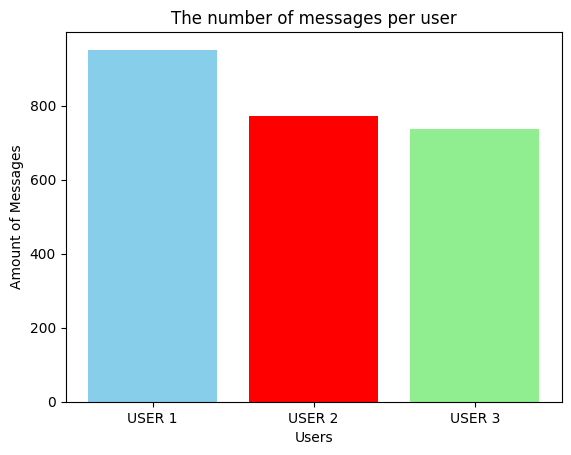

Added 514 Telegram-like samples


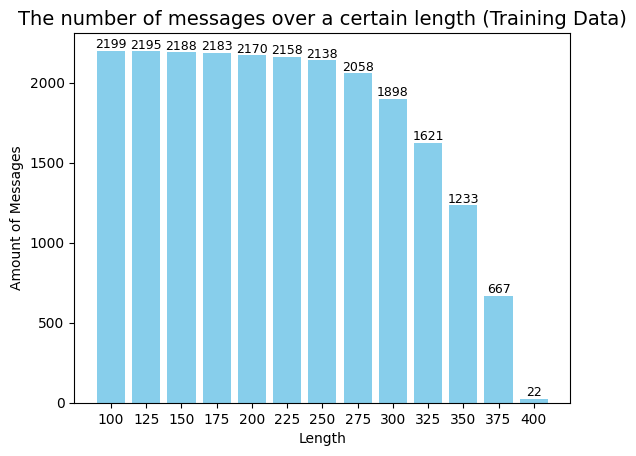

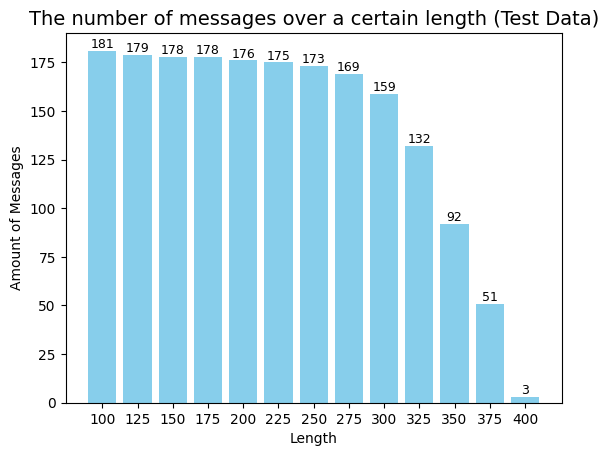

config.json:   0%|          | 0.00/642 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/24.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.65M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  714MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

... (25 outputs left out)

  0%|          | 0/139 [00:00<?, ?it/s]

11 Train loss = 0.82 Val accuracy = 80.11%


  0%|          | 0/139 [00:00<?, ?it/s]

12 Train loss = 0.8131 Val accuracy = 80.11%
-------------------------------------------------
Stage 1 test Accuracy (FC Only): 67.74%
              precision    recall  f1-score   support

      USER 1       0.80      0.60      0.68        72
      USER 2       0.63      0.71      0.67        58
      USER 3       0.63      0.75      0.68        56

    accuracy                           0.68       186
   macro avg       0.68      0.68      0.68       186
weighted avg       0.69      0.68      0.68       186

-------------------------------------------------
Guesses:
Message #1
  Guess: USER 1
  Confidence by users:
    USER 1: 53.85%
    USER 2: 32.96%
    USER 3: 13.18%
Message #2
  Guess: USER 1
  Confidence by users:
    USER 1: 43.21%
    USER 2: 40.89%
    USER 3: 15.89%
Message #3
  Guess: USER 2
  Confidence by users:
    USER 1: 37.78%
    USER 2: 38.34%
    USER 3: 23.88%
Message #4
  Guess: USER 2
  Confidence by users:
    USER 1: 31.31%
    USER 2: 35.85%
    USER 3: 32.8

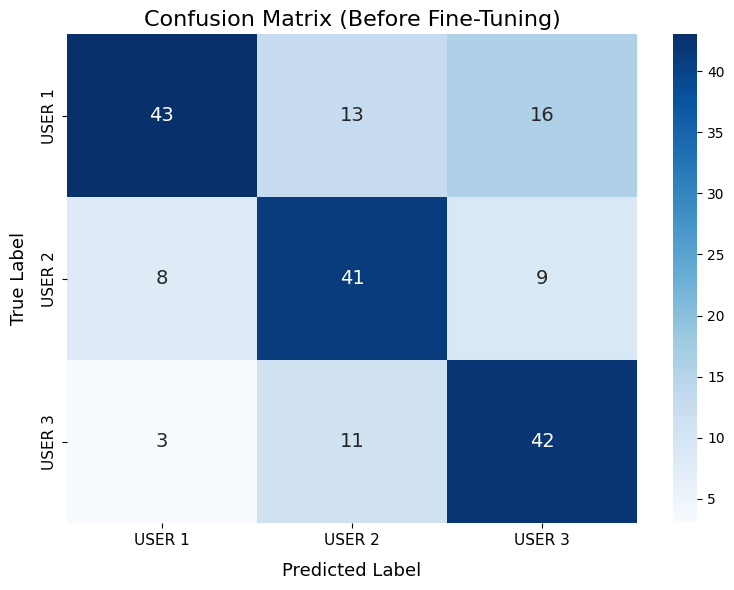

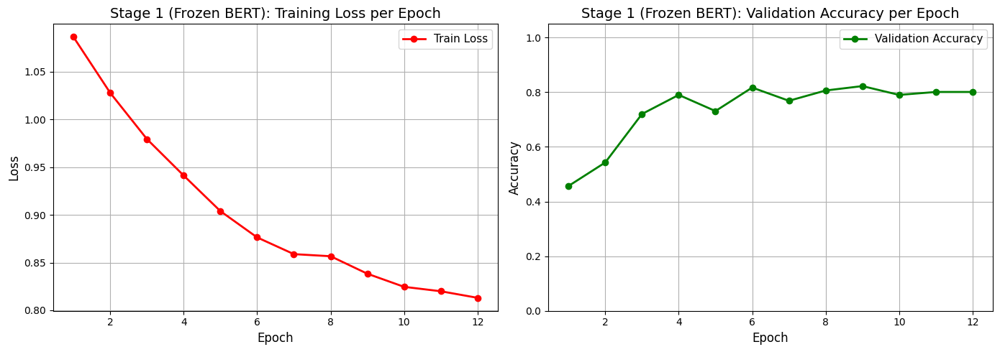

Full Fine-Tuning:


  0%|          | 0/139 [00:00<?, ?it/s]

1 Train loss = 0.5668 Val accuracy = 94.62%


  0%|          | 0/139 [00:00<?, ?it/s]

2 Train loss = 0.0765 Val accuracy = 95.7%


  0%|          | 0/139 [00:00<?, ?it/s]

... (11 outputs left out)

  0%|          | 0/139 [00:00<?, ?it/s]

9 Train loss = 0.0001 Val accuracy = 96.77%


  0%|          | 0/139 [00:00<?, ?it/s]

10 Train loss = 0.0007 Val accuracy = 96.77%


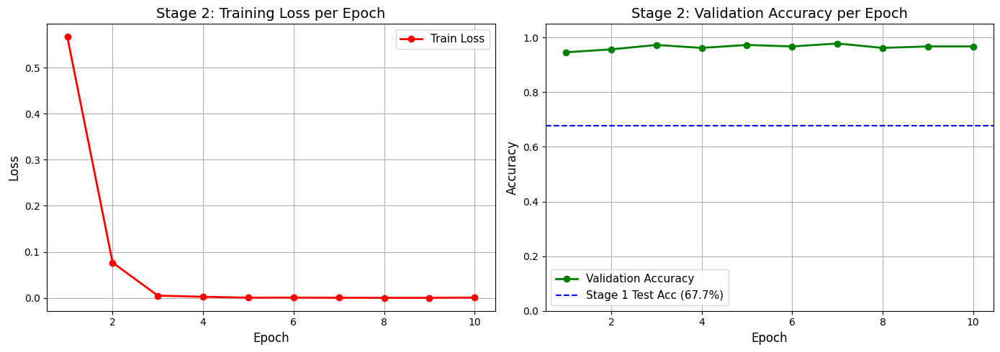

STAGE 1 Test Accuracy: 67.74%
FINAL Test Accuracy (After FT): 94.09%
FINAL F1-macro: 94.0%
Improvement: +26.34%
              precision    recall  f1-score   support

      USER 1       0.97      0.93      0.95        72
      USER 2       0.96      0.90      0.93        58
      USER 3       0.89      1.00      0.94        56

    accuracy                           0.94       186
   macro avg       0.94      0.94      0.94       186
weighted avg       0.94      0.94      0.94       186

Guesses:
Message #1
  Guess: USER 1
  Confidence by users:
    USER 1: 99.99%
    USER 2: 0.01%
    USER 3: 0.0%
Message #2
  Guess: USER 1
  Confidence by users:
    USER 1: 100.0%
    USER 2: 0.0%
    USER 3: 0.0%
Message #3
  Guess: USER 1
  Confidence by users:
    USER 1: 100.0%
    USER 2: 0.0%
    USER 3: 0.0%
Message #4
  Guess: USER 1
  Confidence by users:
    USER 1: 100.0%
    USER 2: 0.0%
    USER 3: 0.0%
Message #5
  Guess: USER 1
  Confidence by users:
    USER 1: 100.0%
    USER 2: 0.0%

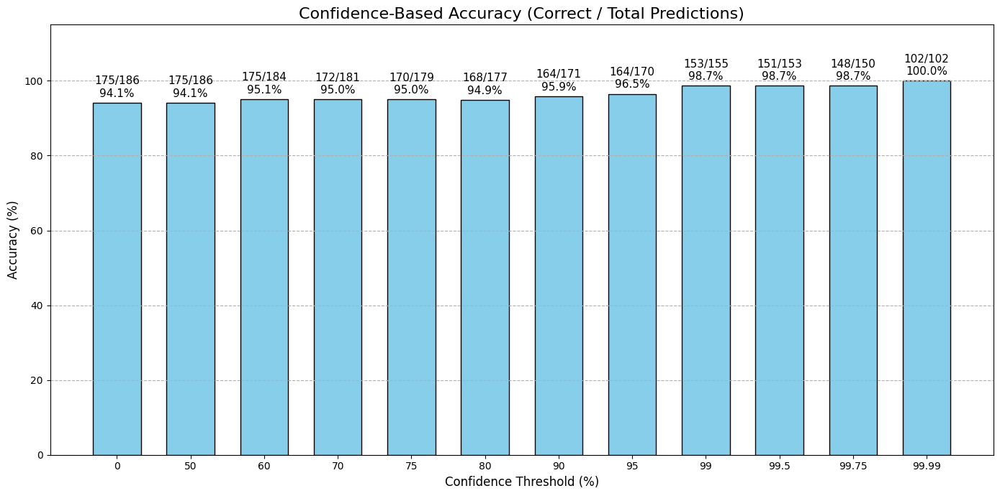

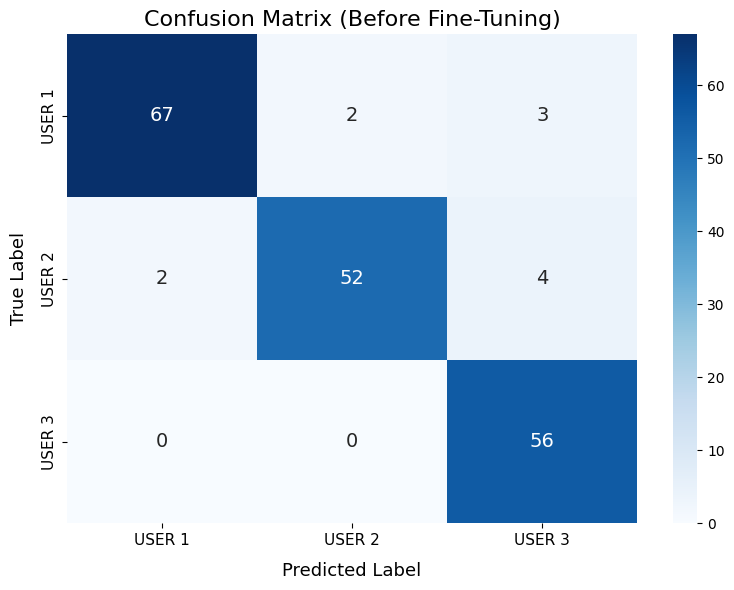

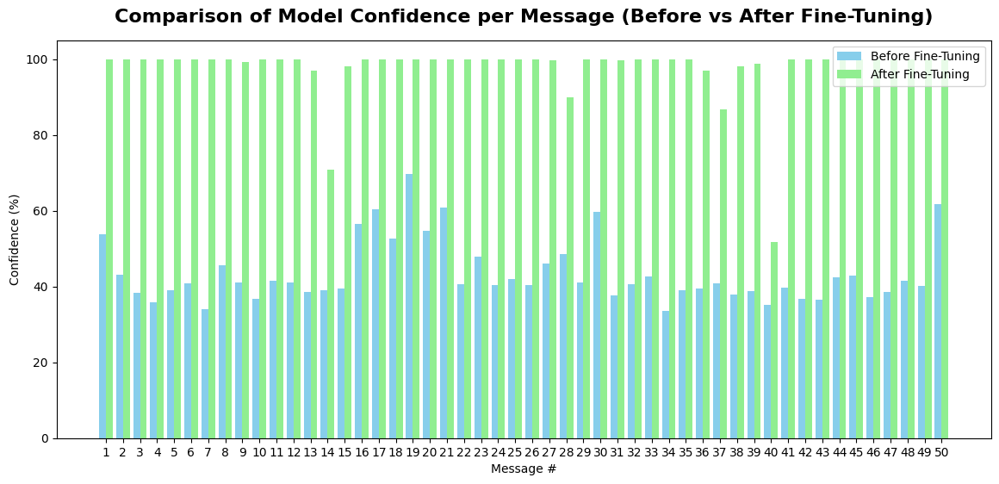

In [ ]:
# 1 test for explanation purposes for Github
print('------------------------------------')
print('Seed:', 42)
print('------------------------------------')
model, tokenizer, le, accuracy = run_model_simulation(True, 42, [True, True, True], True, 0.1) # dropout=0.1

# **Analyzing the results above:**

**Initially, after loading the data and using sliding windows, we had**

**Train samples: 1717 Avg len: 342.2 chars**

**Val samples: 186 Avg len: 332.0 chars**

**Test samples: 186 Avg len: 336.3 chars**

**Augmentation added 514 extra messages to the training dataset.**

# **Stage 1 Results:**

**We can observe that the validation accuracy rose from 45.7% to 82.26% at its peak; however, the Stage 1 test accuracy was only 67.74%, which indicates some overfitting.**

# **Stage 2 Results:**

**The validation accuracy rose from 94.62% to a peak of 97.85%. But unlike Stage 1, the Stage 2 test accuracy was 94.09% (basically no overfitting)!**

# **In addition, the classification report shows:**

**precision    recall  f1-score   support**

**USER 1       0.97      0.93      0.95        72**

**USER 2       0.96      0.90      0.93        58**

**USER 3       0.89      1.00      0.94        56**

**accuracy                           0.94       186**

**macro avg       0.94      0.94      0.94       186**

**weighted avg       0.94      0.94      0.94       186**


**This shows that, despite USER 1 having slightly more messages (951 compared to 773 and 776 from USER 2 and USER 3), the F1 score for each USER is around 0.94, with USER 1 having the highest precision (0.97) and USER 3 having the highest recall (1.00).**

**Lastly, from the graphs, we can observe that the model has become much more confident (with 102/186 test messages having a confidence score >= 99.99%) and that there is a positive correlation between the model's confidence and test accuracy.**

# **Trying 5 seeds with dropout = 0.15(verbose=True):**

------------------------------------
Seed: 1
------------------------------------
USER 1: 665 train, 72 val, 72 test blocks (out of 951 original messages)
USER 2: 541 train, 58 val, 58 test blocks (out of 773 original messages)
USER 3: 512 train, 56 val, 56 test blocks (out of 736 original messages)
-------------------------------------------------
Train samples: 1718 Avg len: 346.2 chars
Val samples: 186 Avg len: 325.5 chars
Test samples: 186 Avg len: 328.1 chars
-------------------------------------------------


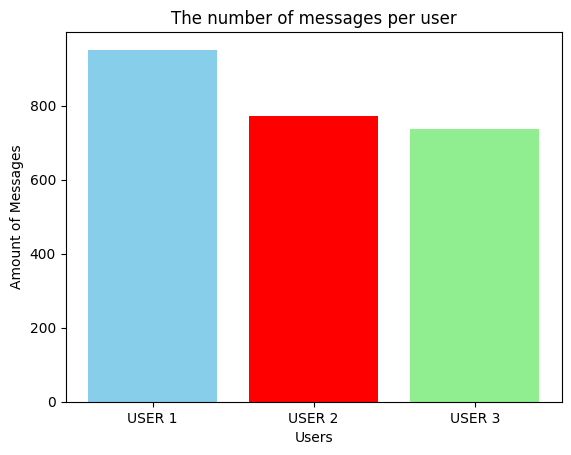

Added 514 Telegram-like samples


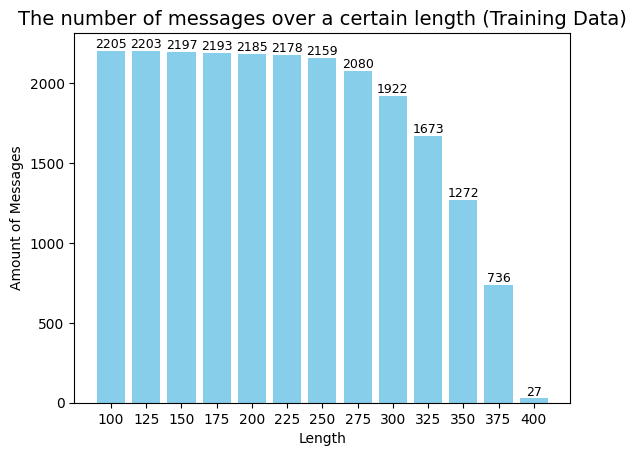

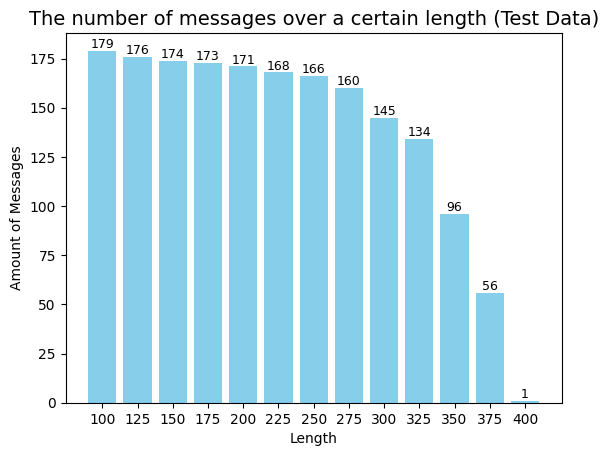

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: DeepPavlov/rubert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those par

Training Frozen Bert:


  0%|          | 0/139 [00:00<?, ?it/s]

1 Train loss = 1.0963 Val accuracy = 38.71%


  0%|          | 0/139 [00:00<?, ?it/s]

... (17 outputs left out)

  0%|          | 0/139 [00:00<?, ?it/s]

11 Train loss = 0.8585 Val accuracy = 77.96%


  0%|          | 0/139 [00:00<?, ?it/s]

12 Train loss = 0.8562 Val accuracy = 78.49%
-------------------------------------------------
Stage 1 test Accuracy (FC Only): 78.49%
              precision    recall  f1-score   support

      USER 1       0.88      0.78      0.82        72
      USER 2       0.72      0.90      0.80        58
      USER 3       0.76      0.68      0.72        56

    accuracy                           0.78       186
   macro avg       0.79      0.78      0.78       186
weighted avg       0.79      0.78      0.78       186

-------------------------------------------------
Guesses:
Message #1
  Guess: USER 1
  Confidence by users:
    USER 1: 47.59%
    USER 2: 20.88%
    USER 3: 31.53%
Message #2
  Guess: USER 1
  Confidence by users:
    USER 1: 56.73%
    USER 2: 22.44%
    USER 3: 20.83%
Message #3
  Guess: USER 1
  Confidence by users:
    USER 1: 52.03%
    USER 2: 26.23%
    USER 3: 21.74%
Message #4
  Guess: USER 1
  Confidence by users:
    USER 1: 57.86%
    USER 2: 24.85%
    USER 3: 17.2

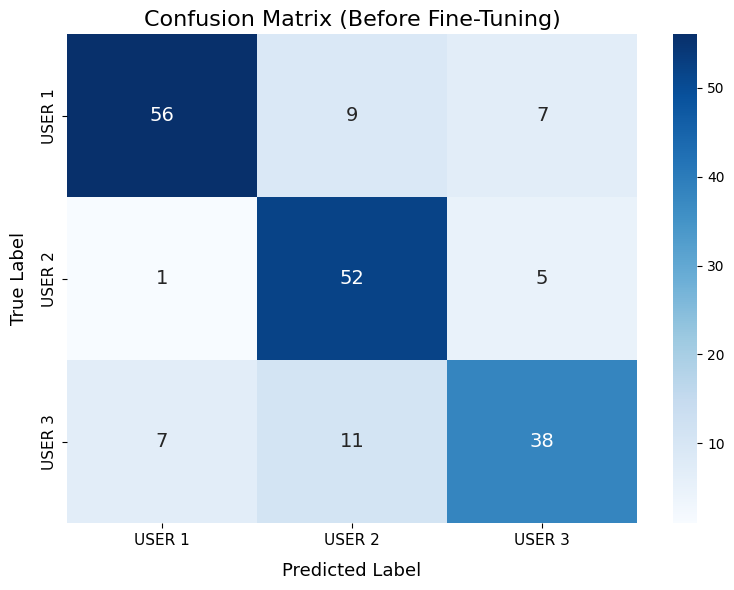

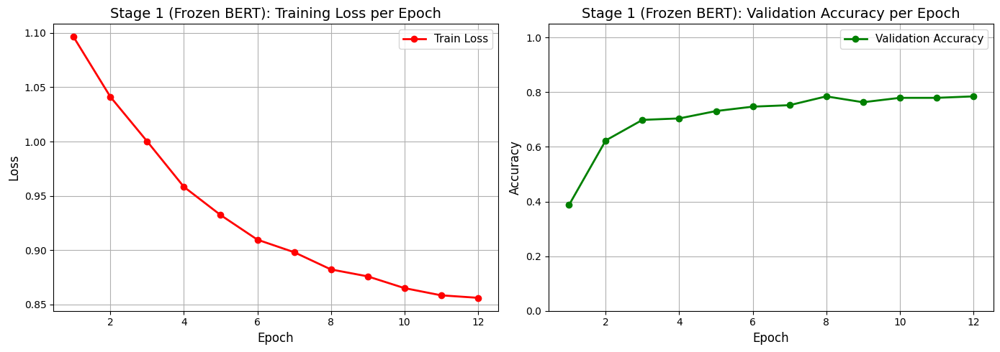

Full Fine-Tuning:


  0%|          | 0/139 [00:00<?, ?it/s]

1 Train loss = 0.6457 Val accuracy = 94.09%


  0%|          | 0/139 [00:00<?, ?it/s]

2 Train loss = 0.1187 Val accuracy = 96.77%


  0%|          | 0/139 [00:00<?, ?it/s]

... (11 outputs left out)

  0%|          | 0/139 [00:00<?, ?it/s]

9 Train loss = 0.002 Val accuracy = 97.31%


  0%|          | 0/139 [00:00<?, ?it/s]

10 Train loss = 0.0029 Val accuracy = 96.77%


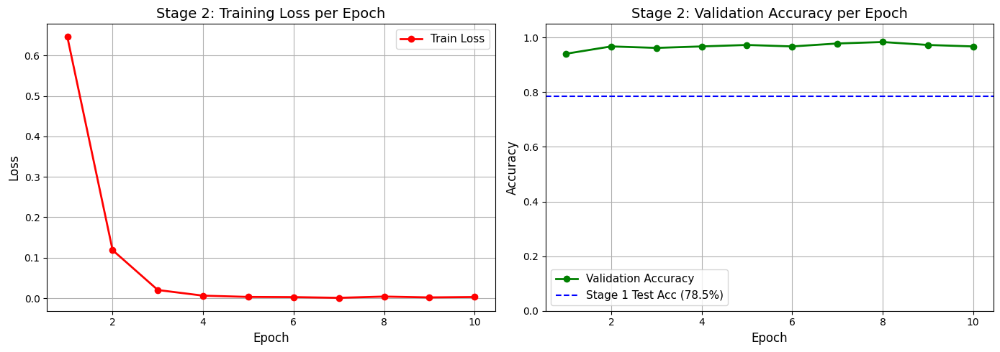

STAGE 1 Test Accuracy: 78.49%
FINAL Test Accuracy (After FT): 89.25%
FINAL F1-macro: 89.16%
Improvement: +10.75%
              precision    recall  f1-score   support

      USER 1       0.95      0.88      0.91        72
      USER 2       0.80      0.97      0.88        58
      USER 3       0.94      0.84      0.89        56

    accuracy                           0.89       186
   macro avg       0.90      0.89      0.89       186
weighted avg       0.90      0.89      0.89       186

Guesses:
Message #1
  Guess: USER 1
  Confidence by users:
    USER 1: 100.0%
    USER 2: 0.0%
    USER 3: 0.0%
Message #2
  Guess: USER 1
  Confidence by users:
    USER 1: 100.0%
    USER 2: 0.0%
    USER 3: 0.0%
Message #3
  Guess: USER 1
  Confidence by users:
    USER 1: 100.0%
    USER 2: 0.0%
    USER 3: 0.0%
Message #4
  Guess: USER 1
  Confidence by users:
    USER 1: 100.0%
    USER 2: 0.0%
    USER 3: 0.0%
Message #5
  Guess: USER 1
  Confidence by users:
    USER 1: 100.0%
    USER 2: 0.0%

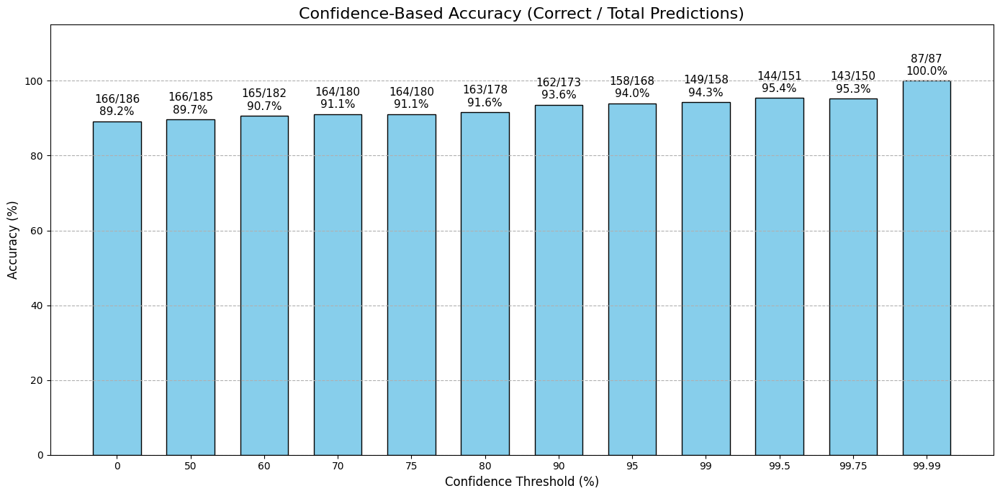

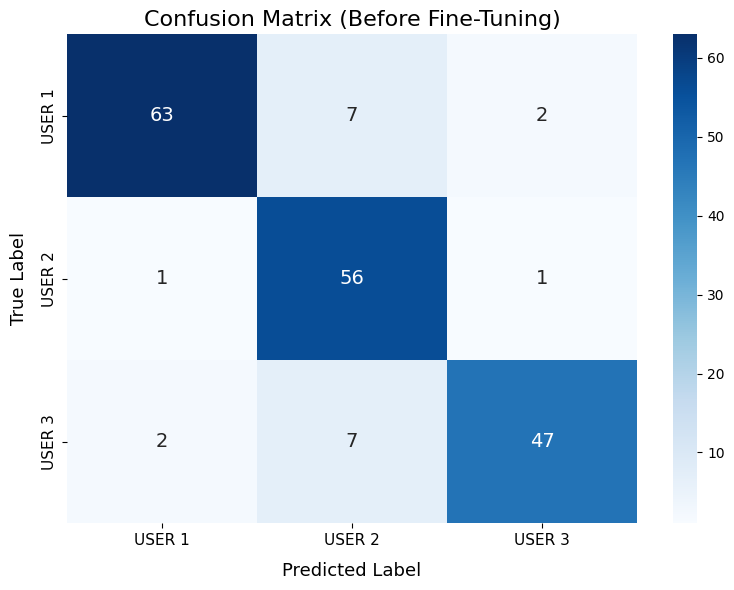

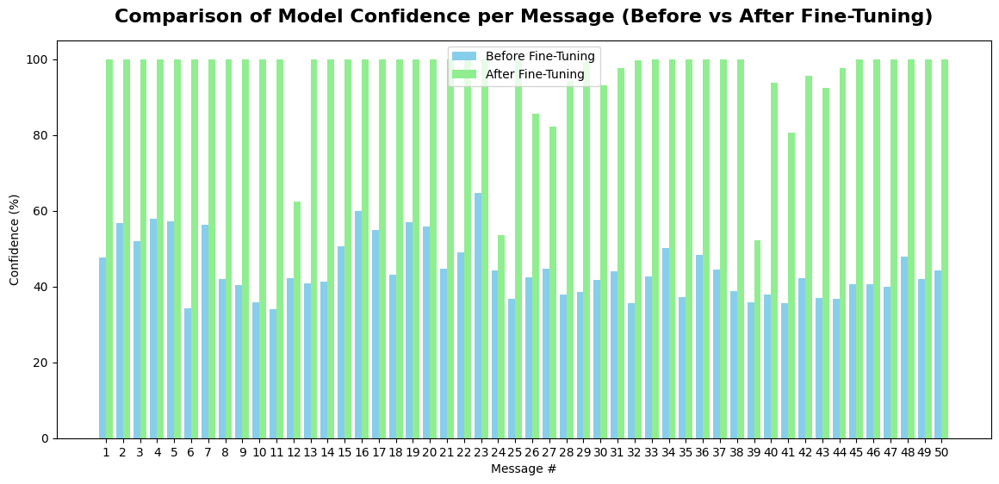

------------------------------------
Seed: 42
------------------------------------
USER 1: 664 train, 72 val, 72 test blocks (out of 951 original messages)
USER 2: 541 train, 58 val, 58 test blocks (out of 773 original messages)
USER 3: 512 train, 56 val, 56 test blocks (out of 736 original messages)
-------------------------------------------------
Train samples: 1717 Avg len: 342.2 chars
Val samples: 186 Avg len: 332.0 chars
Test samples: 186 Avg len: 336.3 chars
-------------------------------------------------


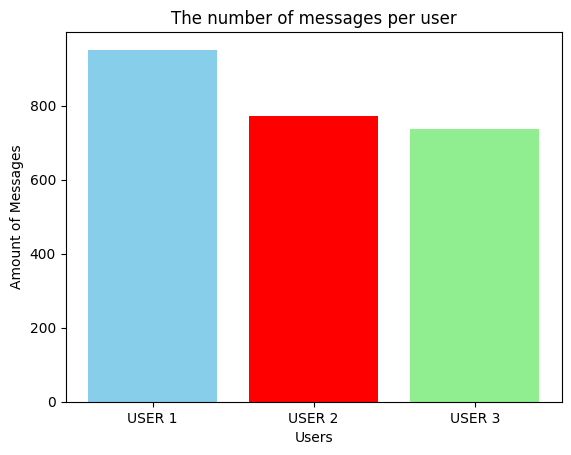

Added 514 Telegram-like samples


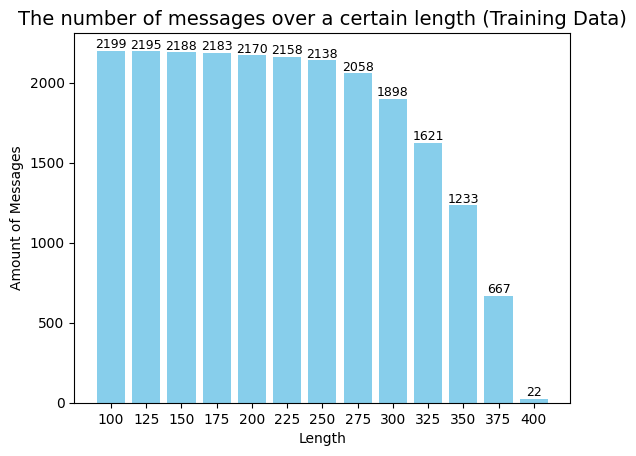

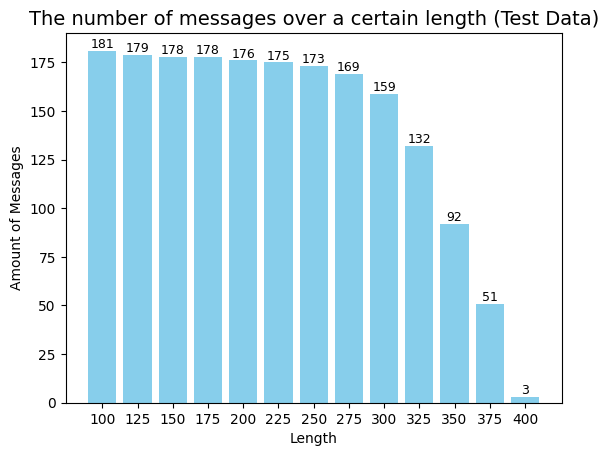

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: DeepPavlov/rubert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those par

Training Frozen Bert:


  0%|          | 0/139 [00:00<?, ?it/s]

1 Train loss = 1.0883 Val accuracy = 45.16%


  0%|          | 0/139 [00:00<?, ?it/s]

... (17 outputs left out)

  0%|          | 0/139 [00:00<?, ?it/s]

11 Train loss = 0.8572 Val accuracy = 80.65%


  0%|          | 0/139 [00:00<?, ?it/s]

12 Train loss = 0.8514 Val accuracy = 80.65%
-------------------------------------------------
Stage 1 test Accuracy (FC Only): 66.13%
              precision    recall  f1-score   support

      USER 1       0.79      0.53      0.63        72
      USER 2       0.61      0.76      0.68        58
      USER 3       0.62      0.73      0.67        56

    accuracy                           0.66       186
   macro avg       0.67      0.67      0.66       186
weighted avg       0.68      0.66      0.66       186

-------------------------------------------------
Guesses:
Message #1
  Guess: USER 1
  Confidence by users:
    USER 1: 49.17%
    USER 2: 33.79%
    USER 3: 17.03%
Message #2
  Guess: USER 2
  Confidence by users:
    USER 1: 39.2%
    USER 2: 40.07%
    USER 3: 20.73%
Message #3
  Guess: USER 2
  Confidence by users:
    USER 1: 34.57%
    USER 2: 39.69%
    USER 3: 25.74%
Message #4
  Guess: USER 2
  Confidence by users:
    USER 1: 29.5%
    USER 2: 37.3%
    USER 3: 33.2%
M

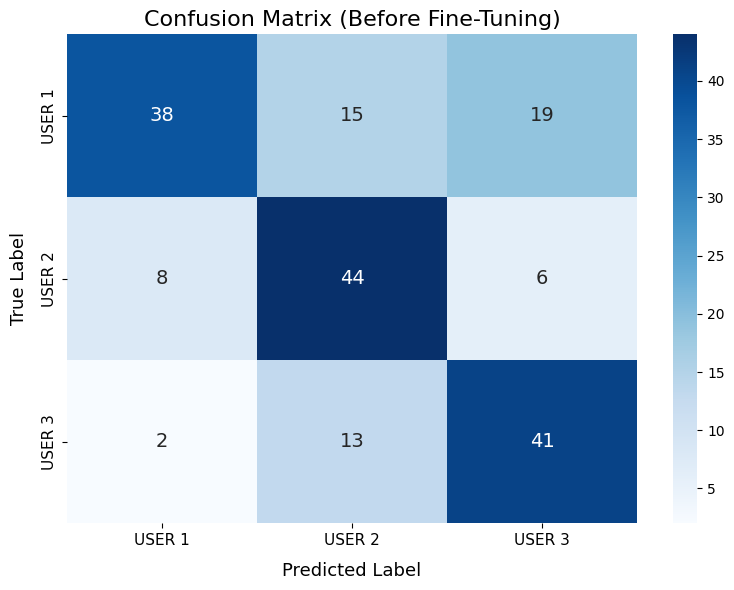

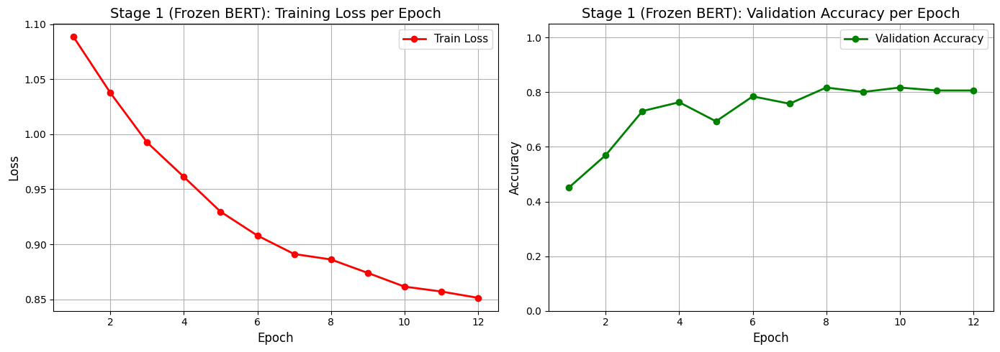

Full Fine-Tuning:


  0%|          | 0/139 [00:00<?, ?it/s]

1 Train loss = 0.647 Val accuracy = 92.47%


  0%|          | 0/139 [00:00<?, ?it/s]

2 Train loss = 0.1217 Val accuracy = 94.62%


  0%|          | 0/139 [00:00<?, ?it/s]

... (5 outputs left out)

  0%|          | 0/139 [00:00<?, ?it/s]

6 Train loss = 0.0006 Val accuracy = 97.31%


  0%|          | 0/139 [00:00<?, ?it/s]

7 Train loss = 0.0006 Val accuracy = 96.24%
Early Stopping 6


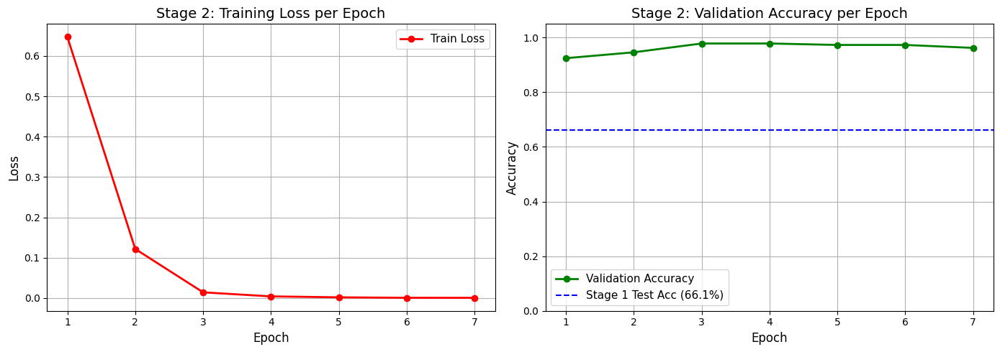

STAGE 1 Test Accuracy: 66.13%
FINAL Test Accuracy (After FT): 93.55%
FINAL F1-macro: 93.45%
Improvement: +27.42%
              precision    recall  f1-score   support

      USER 1       0.94      0.94      0.94        72
      USER 2       0.96      0.88      0.92        58
      USER 3       0.90      0.98      0.94        56

    accuracy                           0.94       186
   macro avg       0.94      0.94      0.93       186
weighted avg       0.94      0.94      0.94       186

Guesses:
Message #1
  Guess: USER 1
  Confidence by users:
    USER 1: 99.91%
    USER 2: 0.09%
    USER 3: 0.0%
Message #2
  Guess: USER 1
  Confidence by users:
    USER 1: 99.97%
    USER 2: 0.03%
    USER 3: 0.0%
Message #3
  Guess: USER 1
  Confidence by users:
    USER 1: 99.98%
    USER 2: 0.01%
    USER 3: 0.0%
Message #4
  Guess: USER 1
  Confidence by users:
    USER 1: 99.97%
    USER 2: 0.03%
    USER 3: 0.0%
Message #5
  Guess: USER 1
  Confidence by users:
    USER 1: 99.99%
    USER 2: 

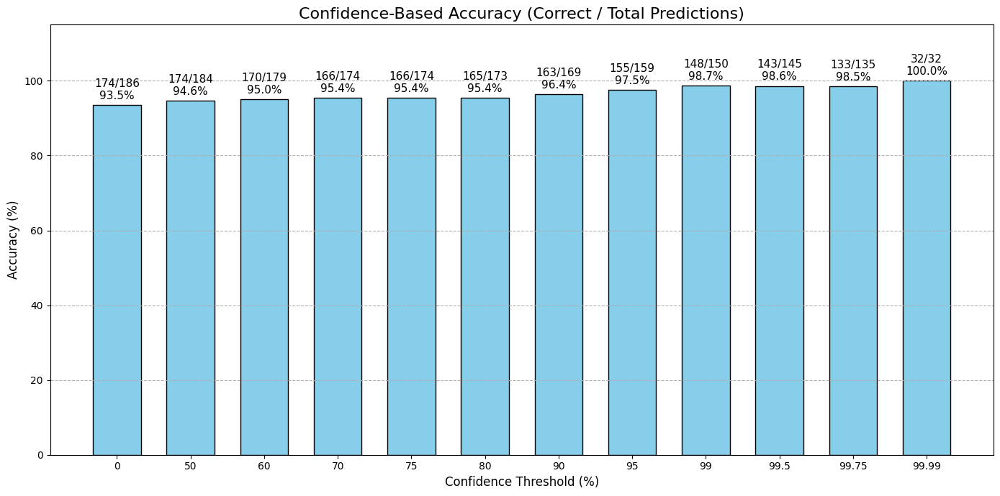

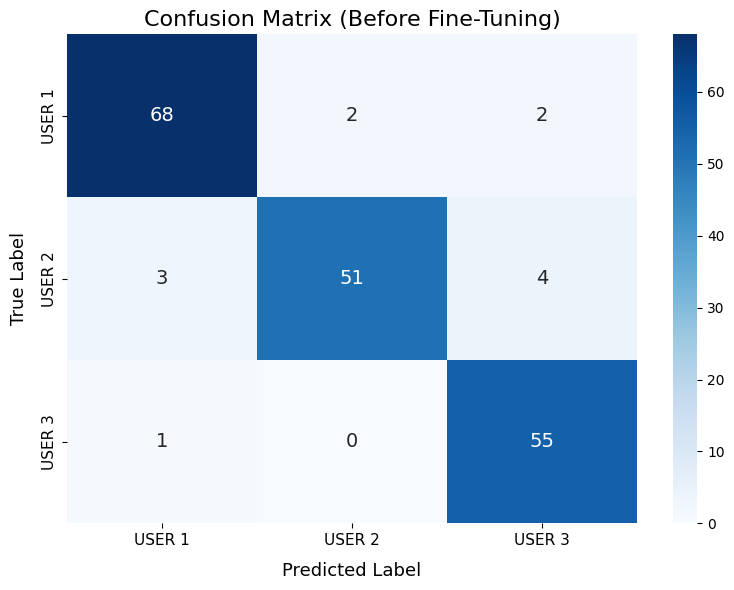

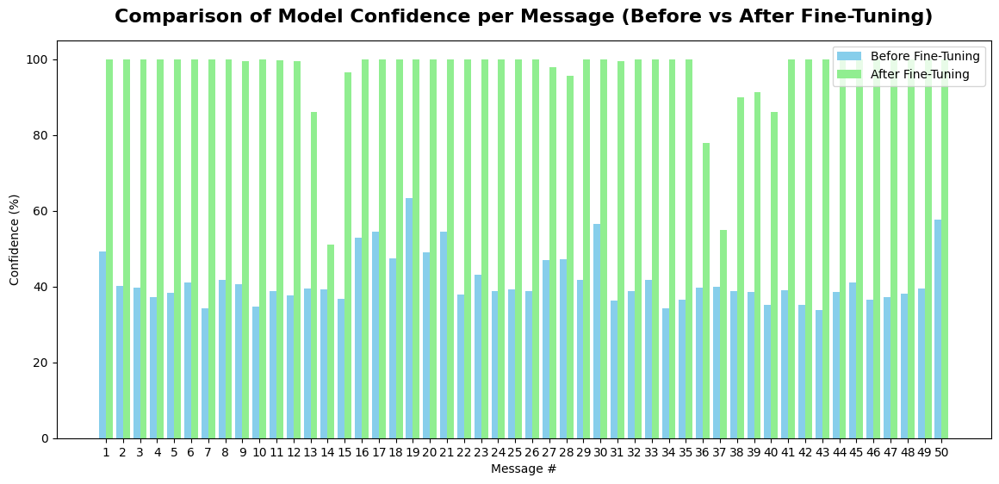

------------------------------------
Seed: 777
------------------------------------
USER 1: 664 train, 72 val, 72 test blocks (out of 951 original messages)
USER 2: 541 train, 58 val, 58 test blocks (out of 773 original messages)
USER 3: 513 train, 56 val, 55 test blocks (out of 736 original messages)
-------------------------------------------------
Train samples: 1718 Avg len: 341.5 chars
Val samples: 186 Avg len: 346.0 chars
Test samples: 185 Avg len: 324.3 chars
-------------------------------------------------


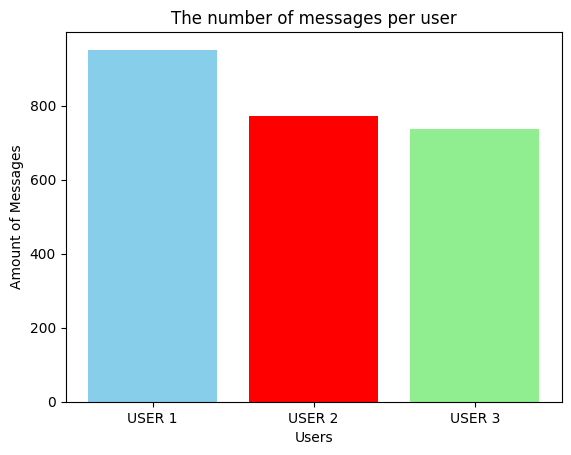

Added 514 Telegram-like samples


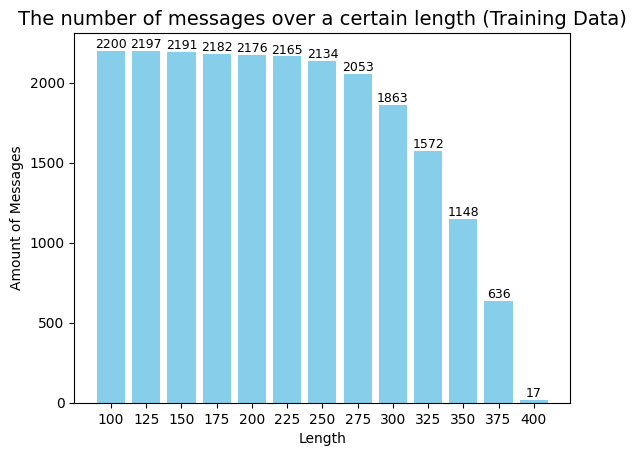

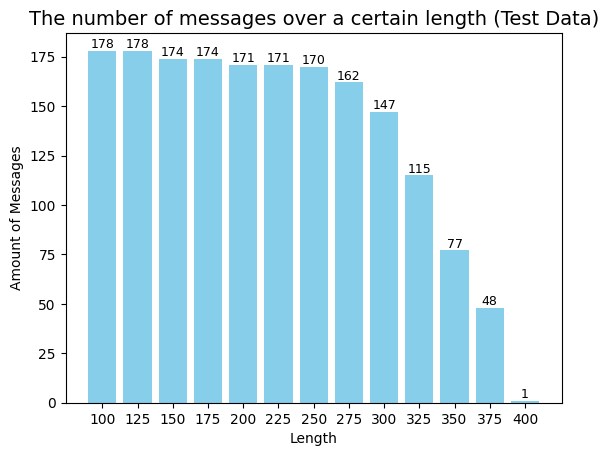

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: DeepPavlov/rubert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those par

Training Frozen Bert:


  0%|          | 0/139 [00:00<?, ?it/s]

1 Train loss = 1.0907 Val accuracy = 48.39%


  0%|          | 0/139 [00:00<?, ?it/s]

... (17 outputs left out)

  0%|          | 0/139 [00:00<?, ?it/s]

11 Train loss = 0.8643 Val accuracy = 77.42%


  0%|          | 0/139 [00:00<?, ?it/s]

12 Train loss = 0.8657 Val accuracy = 76.34%
-------------------------------------------------
Stage 1 test Accuracy (FC Only): 64.86%
              precision    recall  f1-score   support

      USER 1       0.78      0.68      0.73        72
      USER 2       0.63      0.64      0.63        58
      USER 3       0.54      0.62      0.58        55

    accuracy                           0.65       185
   macro avg       0.65      0.65      0.64       185
weighted avg       0.66      0.65      0.65       185

-------------------------------------------------
Guesses:
Message #1
  Guess: USER 3
  Confidence by users:
    USER 1: 26.04%
    USER 2: 33.59%
    USER 3: 40.37%
Message #2
  Guess: USER 3
  Confidence by users:
    USER 1: 32.8%
    USER 2: 30.38%
    USER 3: 36.82%
Message #3
  Guess: USER 3
  Confidence by users:
    USER 1: 31.85%
    USER 2: 31.12%
    USER 3: 37.02%
Message #4
  Guess: USER 3
  Confidence by users:
    USER 1: 30.36%
    USER 2: 31.23%
    USER 3: 38.4%

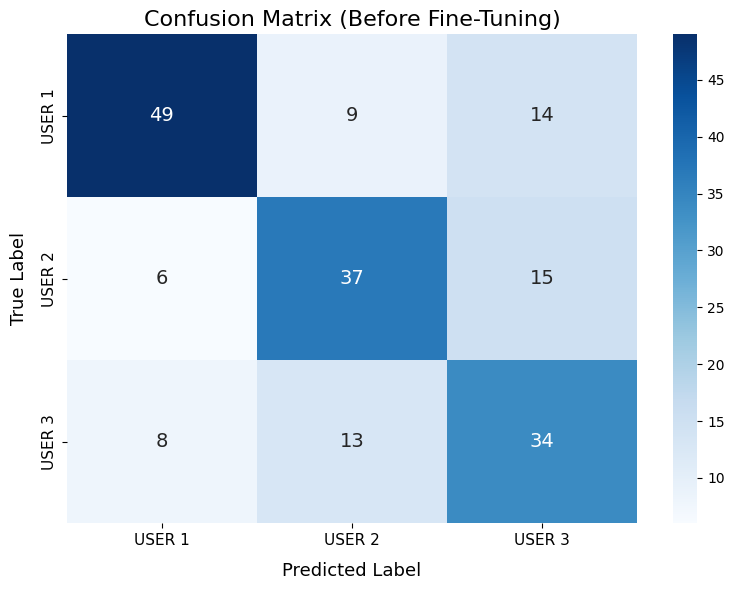

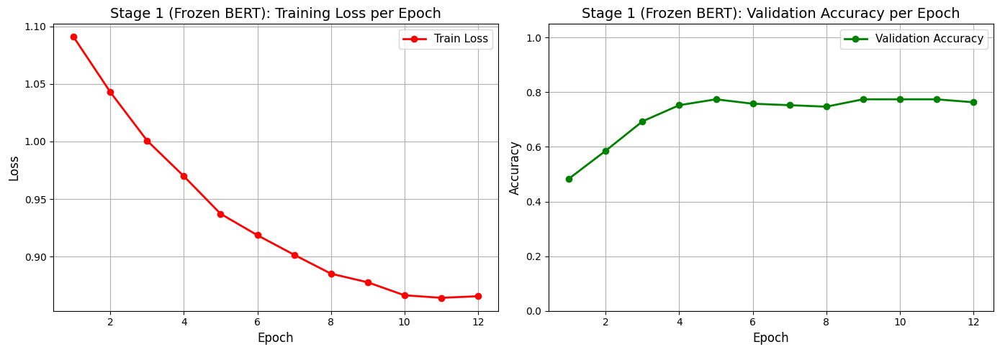

Full Fine-Tuning:


  0%|          | 0/139 [00:00<?, ?it/s]

1 Train loss = 0.7326 Val accuracy = 90.32%


  0%|          | 0/139 [00:00<?, ?it/s]

2 Train loss = 0.1576 Val accuracy = 96.77%


  0%|          | 0/139 [00:00<?, ?it/s]

... (5 outputs left out)

  0%|          | 0/139 [00:00<?, ?it/s]

6 Train loss = 0.0008 Val accuracy = 96.77%


  0%|          | 0/139 [00:00<?, ?it/s]

7 Train loss = 0.0006 Val accuracy = 97.31%
Early Stopping 6


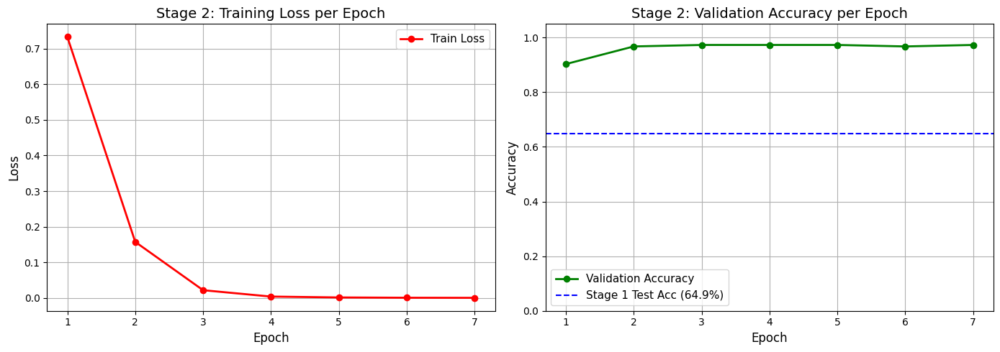

STAGE 1 Test Accuracy: 64.86%
FINAL Test Accuracy (After FT): 85.41%
FINAL F1-macro: 85.5%
Improvement: +20.54%
              precision    recall  f1-score   support

      USER 1       0.95      0.75      0.84        72
      USER 2       0.77      0.95      0.85        58
      USER 3       0.86      0.89      0.88        55

    accuracy                           0.85       185
   macro avg       0.86      0.86      0.85       185
weighted avg       0.87      0.85      0.85       185

Guesses:
Message #1
  Guess: USER 1
  Confidence by users:
    USER 1: 74.32%
    USER 2: 0.41%
    USER 3: 25.27%
Message #2
  Guess: USER 1
  Confidence by users:
    USER 1: 91.12%
    USER 2: 0.17%
    USER 3: 8.71%
Message #3
  Guess: USER 1
  Confidence by users:
    USER 1: 88.89%
    USER 2: 0.25%
    USER 3: 10.86%
Message #4
  Guess: USER 3
  Confidence by users:
    USER 1: 0.13%
    USER 2: 0.2%
    USER 3: 99.66%
Message #5
  Guess: USER 3
  Confidence by users:
    USER 1: 2.35%
    USER 

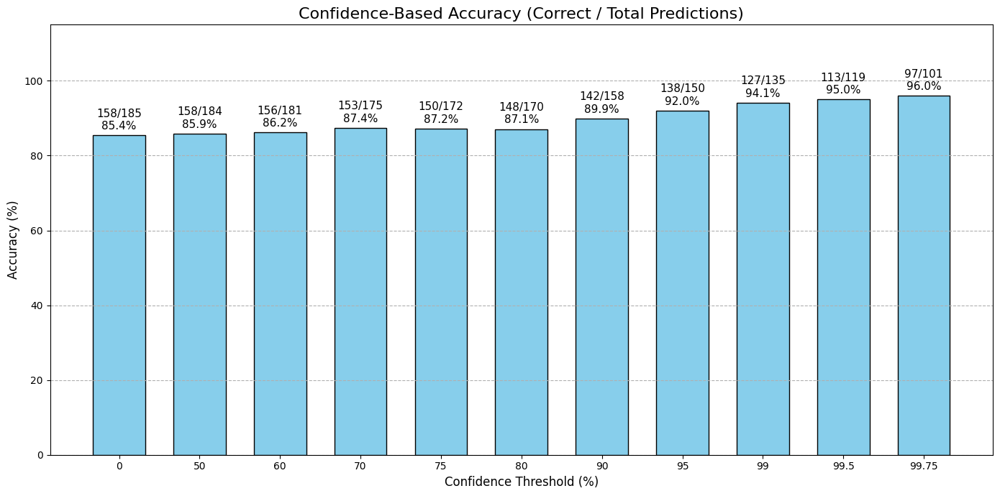

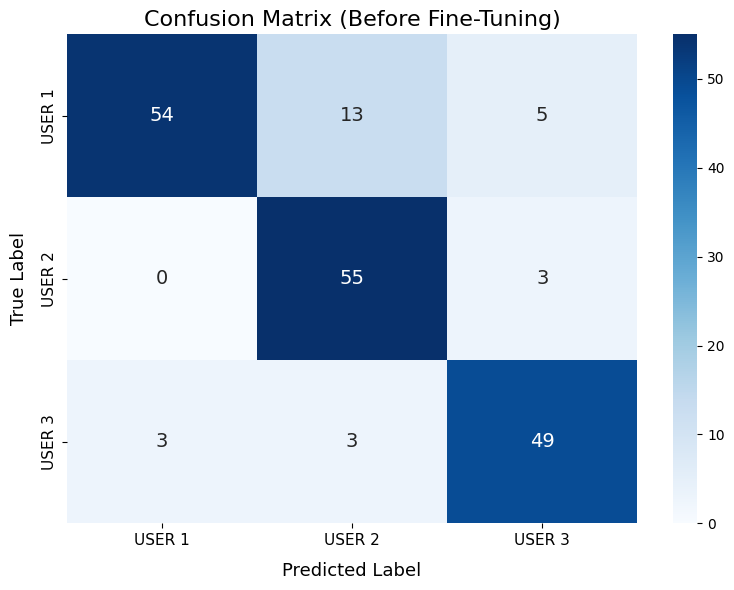

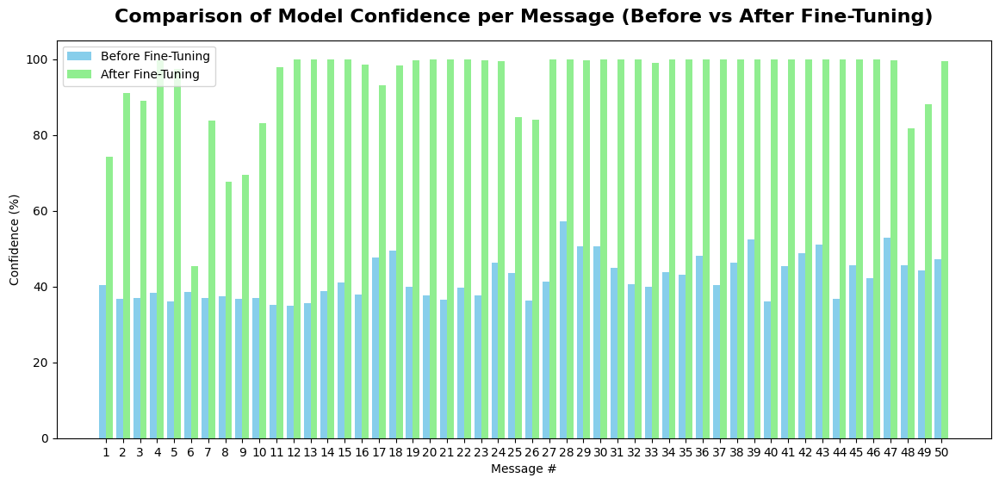

------------------------------------
Seed: 2026
------------------------------------
USER 1: 664 train, 72 val, 72 test blocks (out of 951 original messages)
USER 2: 541 train, 58 val, 58 test blocks (out of 773 original messages)
USER 3: 513 train, 56 val, 56 test blocks (out of 736 original messages)
-------------------------------------------------
Train samples: 1718 Avg len: 344.6 chars
Val samples: 186 Avg len: 325.2 chars
Test samples: 186 Avg len: 337.0 chars
-------------------------------------------------


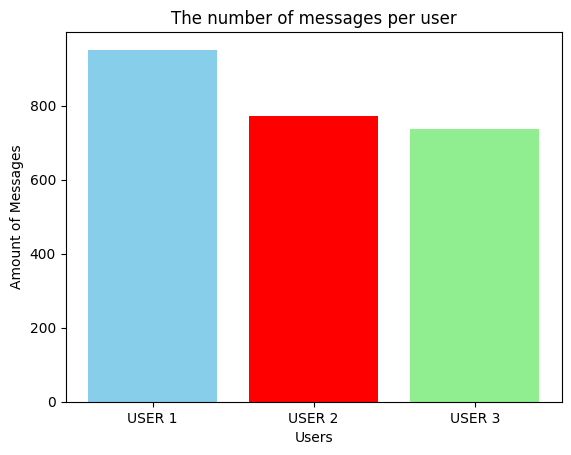

Added 514 Telegram-like samples


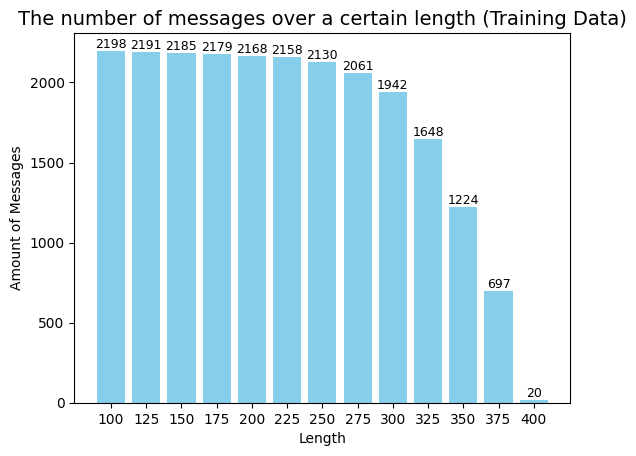

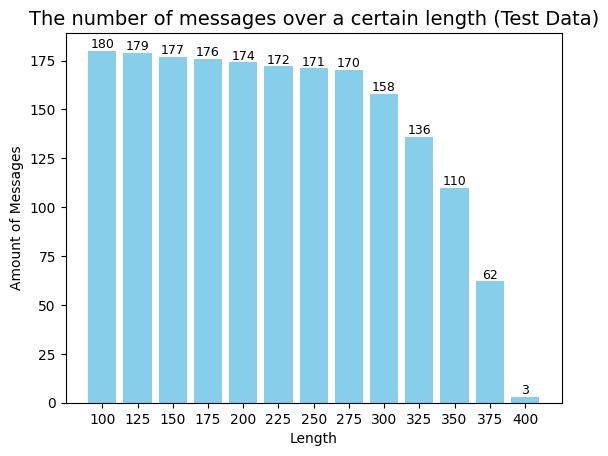

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: DeepPavlov/rubert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those par

Training Frozen Bert:


  0%|          | 0/139 [00:00<?, ?it/s]

1 Train loss = 1.0917 Val accuracy = 46.77%


  0%|          | 0/139 [00:00<?, ?it/s]

... (17 outputs left out)

  0%|          | 0/139 [00:00<?, ?it/s]

11 Train loss = 0.8474 Val accuracy = 77.42%


  0%|          | 0/139 [00:00<?, ?it/s]

12 Train loss = 0.8379 Val accuracy = 77.42%
-------------------------------------------------
Stage 1 test Accuracy (FC Only): 61.83%
              precision    recall  f1-score   support

      USER 1       0.75      0.64      0.69        72
      USER 2       0.53      0.43      0.48        58
      USER 3       0.56      0.79      0.66        56

    accuracy                           0.62       186
   macro avg       0.62      0.62      0.61       186
weighted avg       0.63      0.62      0.61       186

-------------------------------------------------
Guesses:
Message #1
  Guess: USER 1
  Confidence by users:
    USER 1: 47.03%
    USER 2: 29.79%
    USER 3: 23.18%
Message #2
  Guess: USER 1
  Confidence by users:
    USER 1: 39.07%
    USER 2: 32.49%
    USER 3: 28.44%
Message #3
  Guess: USER 2
  Confidence by users:
    USER 1: 25.64%
    USER 2: 42.37%
    USER 3: 31.99%
Message #4
  Guess: USER 1
  Confidence by users:
    USER 1: 48.95%
    USER 2: 32.86%
    USER 3: 18.2

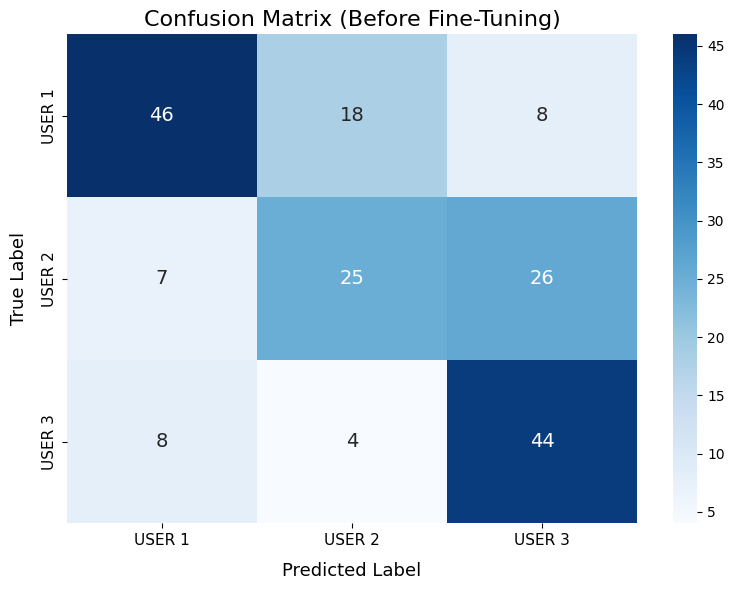

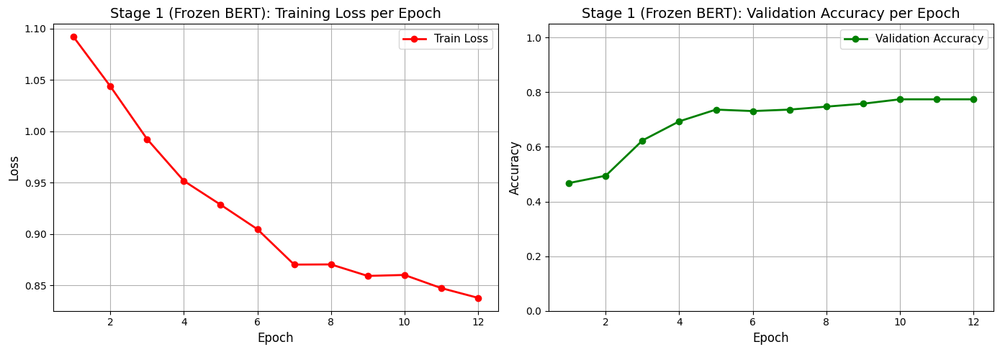

Full Fine-Tuning:


  0%|          | 0/139 [00:00<?, ?it/s]

1 Train loss = 0.6026 Val accuracy = 89.25%


  0%|          | 0/139 [00:00<?, ?it/s]

2 Train loss = 0.087 Val accuracy = 89.25%


  0%|          | 0/139 [00:00<?, ?it/s]

... (7 outputs left out)

  0%|          | 0/139 [00:00<?, ?it/s]

7 Train loss = 0.0006 Val accuracy = 90.32%


  0%|          | 0/139 [00:00<?, ?it/s]

8 Train loss = 0.0003 Val accuracy = 91.4%
Early Stopping 7


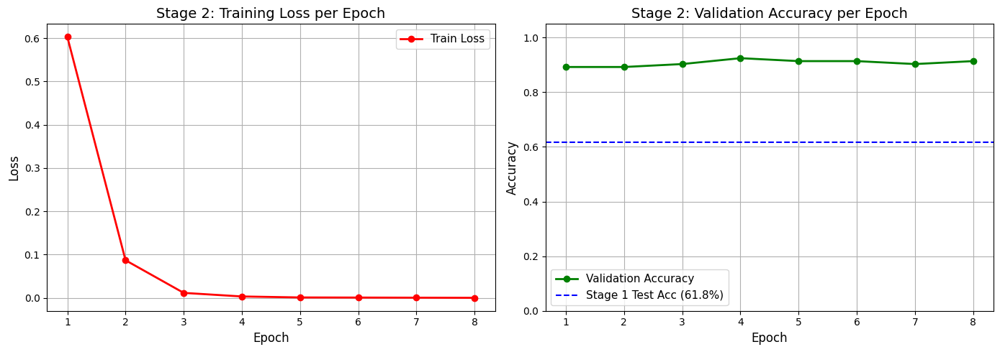

STAGE 1 Test Accuracy: 61.83%
FINAL Test Accuracy (After FT): 90.86%
FINAL F1-macro: 90.74%
Improvement: +29.03%
              precision    recall  f1-score   support

      USER 1       1.00      0.88      0.93        72
      USER 2       0.85      0.88      0.86        58
      USER 3       0.87      0.98      0.92        56

    accuracy                           0.91       186
   macro avg       0.91      0.91      0.91       186
weighted avg       0.91      0.91      0.91       186

Guesses:
Message #1
  Guess: USER 1
  Confidence by users:
    USER 1: 100.0%
    USER 2: 0.0%
    USER 3: 0.0%
Message #2
  Guess: USER 1
  Confidence by users:
    USER 1: 100.0%
    USER 2: 0.0%
    USER 3: 0.0%
Message #3
  Guess: USER 1
  Confidence by users:
    USER 1: 100.0%
    USER 2: 0.0%
    USER 3: 0.0%
Message #4
  Guess: USER 1
  Confidence by users:
    USER 1: 100.0%
    USER 2: 0.0%
    USER 3: 0.0%
Message #5
  Guess: USER 1
  Confidence by users:
    USER 1: 99.77%
    USER 2: 0.23

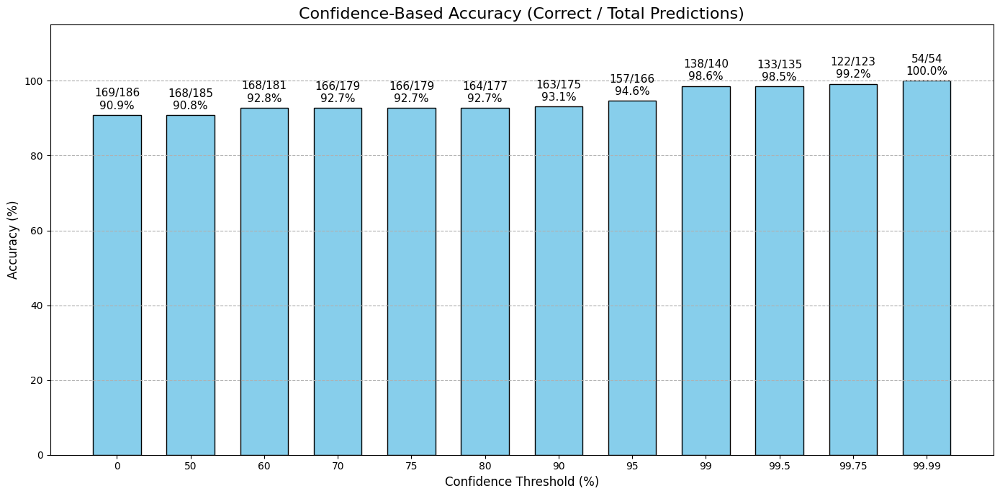

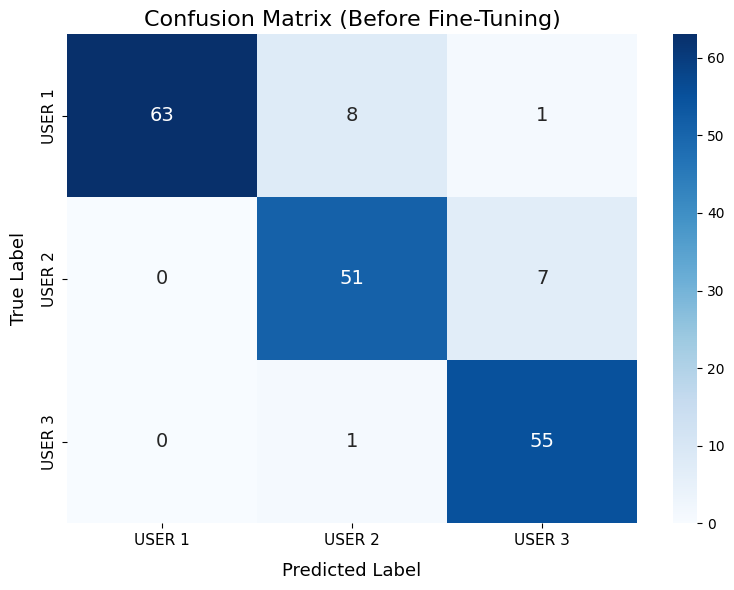

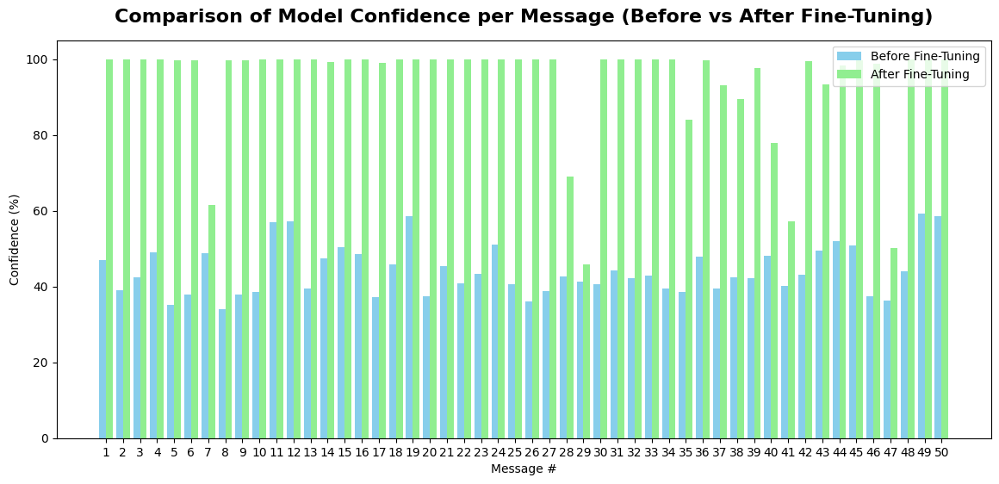

------------------------------------
Seed: 2027
------------------------------------
USER 1: 664 train, 72 val, 72 test blocks (out of 951 original messages)
USER 2: 541 train, 58 val, 58 test blocks (out of 773 original messages)
USER 3: 512 train, 56 val, 56 test blocks (out of 736 original messages)
-------------------------------------------------
Train samples: 1717 Avg len: 342.3 chars
Val samples: 186 Avg len: 333.5 chars
Test samples: 186 Avg len: 341.4 chars
-------------------------------------------------


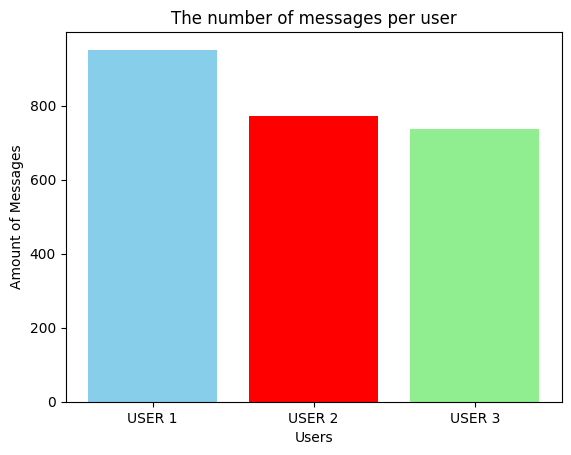

Added 514 Telegram-like samples


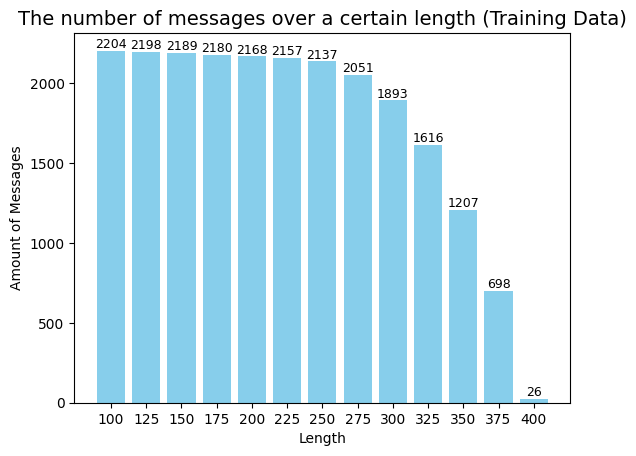

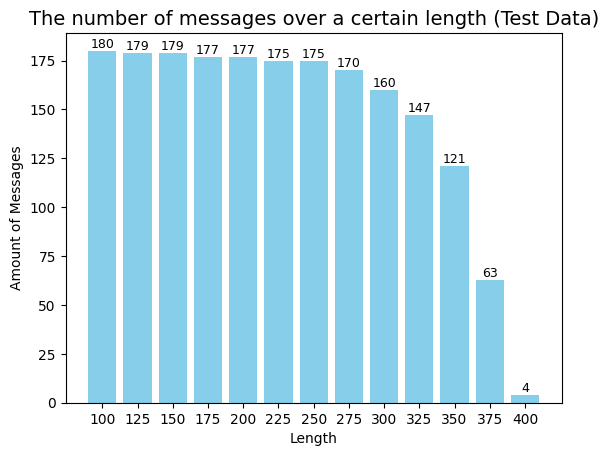

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: DeepPavlov/rubert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those par

Training Frozen Bert:


  0%|          | 0/140 [00:00<?, ?it/s]

1 Train loss = 1.0834 Val accuracy = 38.71%


  0%|          | 0/140 [00:00<?, ?it/s]

... (17 outputs left out)

  0%|          | 0/140 [00:00<?, ?it/s]

11 Train loss = 0.8419 Val accuracy = 76.34%


  0%|          | 0/140 [00:00<?, ?it/s]

12 Train loss = 0.8407 Val accuracy = 76.88%
-------------------------------------------------
Stage 1 test Accuracy (FC Only): 72.58%
              precision    recall  f1-score   support

      USER 1       0.79      0.86      0.83        72
      USER 2       0.63      0.64      0.63        58
      USER 3       0.73      0.64      0.69        56

    accuracy                           0.73       186
   macro avg       0.72      0.71      0.71       186
weighted avg       0.72      0.73      0.72       186

-------------------------------------------------
Guesses:
Message #1
  Guess: USER 3
  Confidence by users:
    USER 1: 33.49%
    USER 2: 23.83%
    USER 3: 42.69%
Message #2
  Guess: USER 1
  Confidence by users:
    USER 1: 52.42%
    USER 2: 19.64%
    USER 3: 27.93%
Message #3
  Guess: USER 1
  Confidence by users:
    USER 1: 44.26%
    USER 2: 25.29%
    USER 3: 30.45%
Message #4
  Guess: USER 1
  Confidence by users:
    USER 1: 44.8%
    USER 2: 26.43%
    USER 3: 28.78

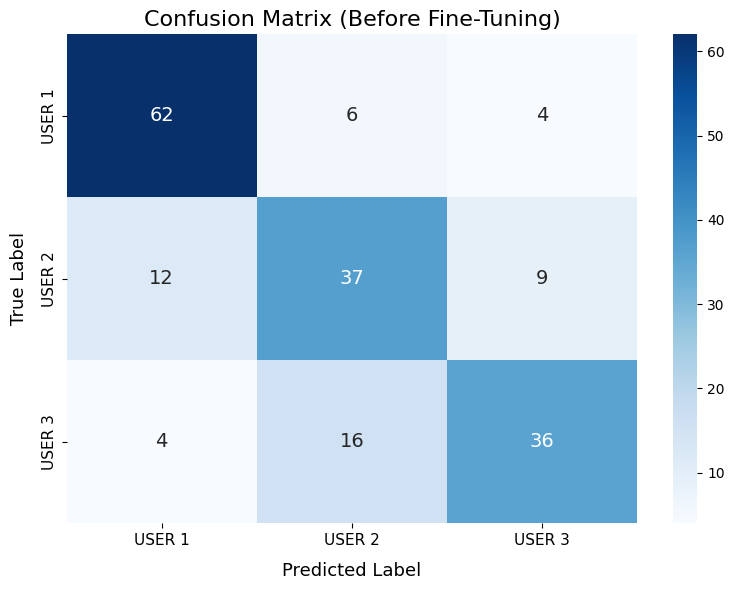

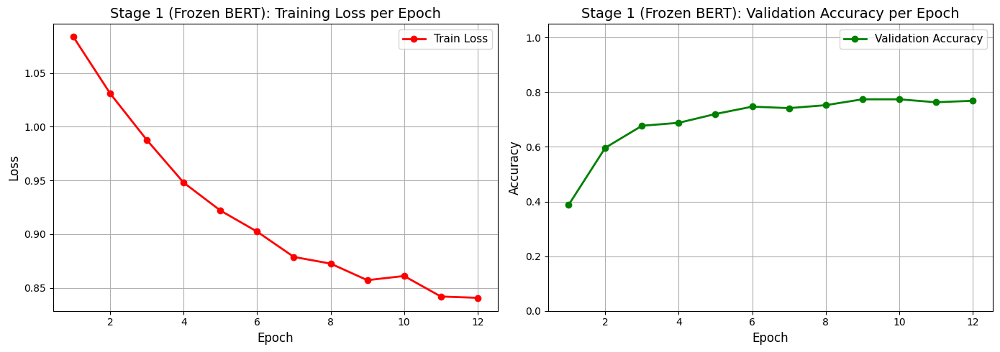

Full Fine-Tuning:


  0%|          | 0/140 [00:00<?, ?it/s]

1 Train loss = 0.6255 Val accuracy = 90.32%


  0%|          | 0/140 [00:00<?, ?it/s]

2 Train loss = 0.0985 Val accuracy = 93.55%


  0%|          | 0/140 [00:00<?, ?it/s]

... (9 outputs left out)

  0%|          | 0/140 [00:00<?, ?it/s]

8 Train loss = 0.0003 Val accuracy = 95.16%


  0%|          | 0/140 [00:00<?, ?it/s]

9 Train loss = 0.0003 Val accuracy = 95.7%
Early Stopping 8


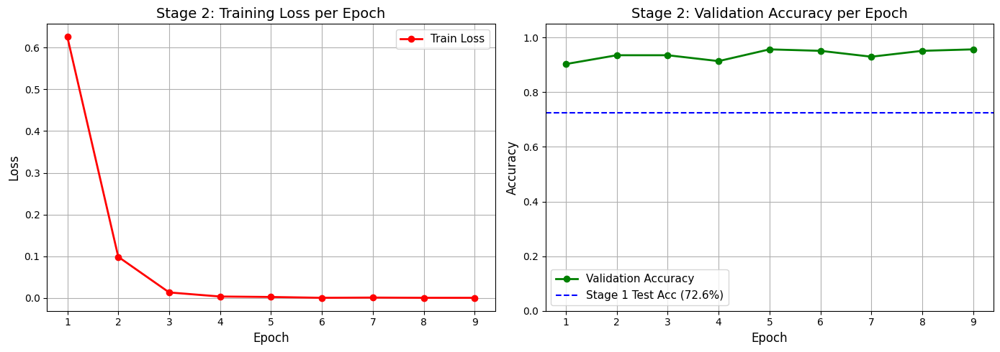

STAGE 1 Test Accuracy: 72.58%
FINAL Test Accuracy (After FT): 88.71%
FINAL F1-macro: 88.25%
Improvement: +16.13%
              precision    recall  f1-score   support

      USER 1       0.97      0.93      0.95        72
      USER 2       0.83      0.84      0.84        58
      USER 3       0.84      0.88      0.86        56

    accuracy                           0.89       186
   macro avg       0.88      0.88      0.88       186
weighted avg       0.89      0.89      0.89       186

Guesses:
Message #1
  Guess: USER 1
  Confidence by users:
    USER 1: 99.99%
    USER 2: 0.0%
    USER 3: 0.01%
Message #2
  Guess: USER 1
  Confidence by users:
    USER 1: 100.0%
    USER 2: 0.0%
    USER 3: 0.0%
Message #3
  Guess: USER 1
  Confidence by users:
    USER 1: 100.0%
    USER 2: 0.0%
    USER 3: 0.0%
Message #4
  Guess: USER 1
  Confidence by users:
    USER 1: 100.0%
    USER 2: 0.0%
    USER 3: 0.0%
Message #5
  Guess: USER 1
  Confidence by users:
    USER 1: 100.0%
    USER 2: 0.0

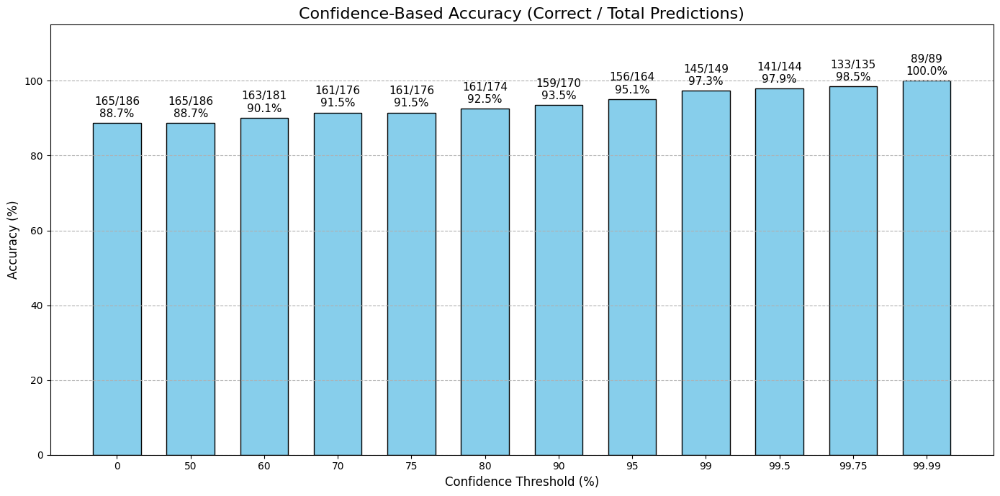

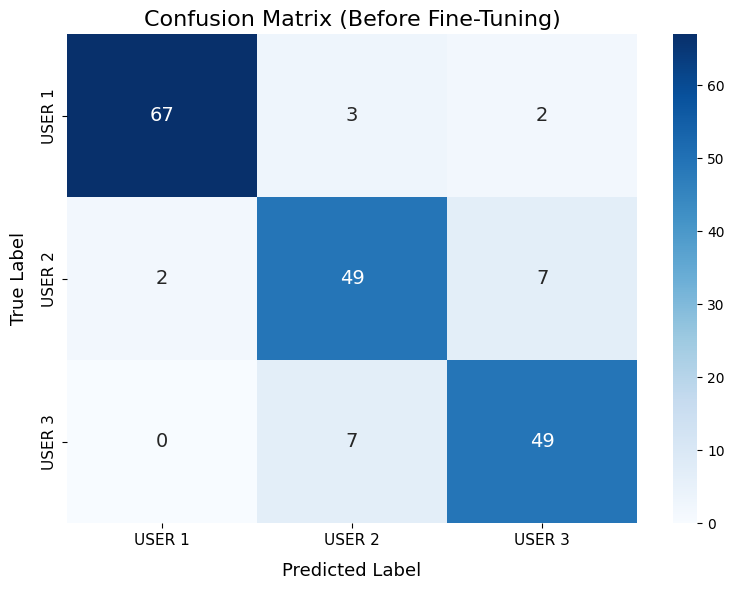

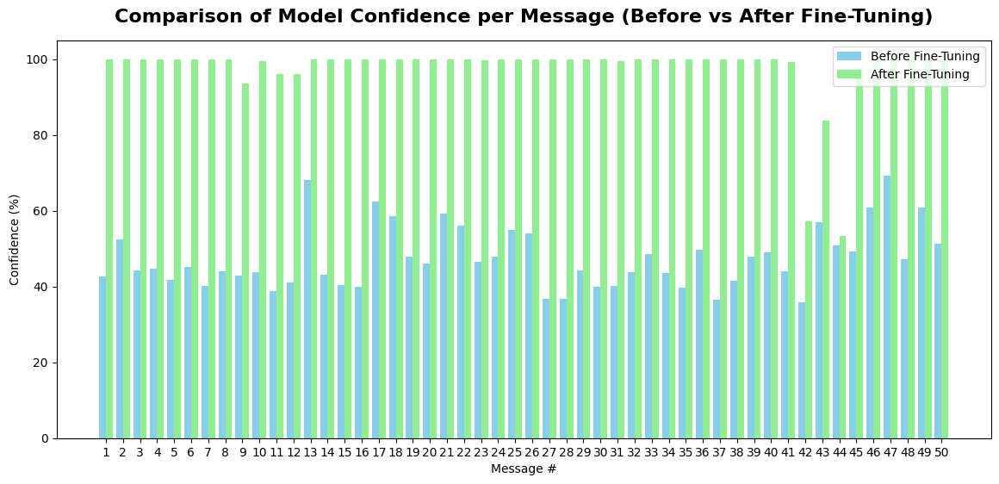

------------------------------------
Overall Accuracy: 89.55% ± 2.67%


In [ ]:
# 5 tests with dropout = 0.15
seed_test = [1, 42, 777, 2026, 2027]
accuracy_seeds = []
for seed in seed_test:
    print('------------------------------------')
    print('Seed:', seed)
    print('------------------------------------')
    model, tokenizer, le, accuracy = run_model_simulation(True, seed, [True, True, True], True, 0.15)
    accuracy_seeds.append(accuracy)

acc_avg = np.sum(accuracy_seeds) / len(seed_test)
acc_std = np.std(accuracy_seeds)
print('------------------------------------')
print('Overall Accuracy:', str(round(acc_avg * 100, 2)) + '% ±', str(round(acc_std * 100, 2)) + '%')

# **Results:**

**The highest validation accuracy and the test accuracy for each seed are shown below:**

**val acc | test acc | delta (diff)**

**Seed 1: 98.39% | 89.25% | -9.14%**

**Seed 42: 97.85% | 93.55% | -4.30%**

**Seed 777: 97.31% | 85.41% | -11.90%**

**Seed 2026: 92.47% | 90.86% | -1.61%**

**Seed 2027: 95.70% | 88.71% | -6.99%**

**-----------------------------------**

**Overall Test Accuracy: 89.55% ± 2.67%**

**Average delta (diff): -6.79%**

**The results show an average accuracy of about 90%; however, there seems to be a noticeable overfitting problem, despite a dropout rate of 0.15.**

**Let's also try the *same experiment* with a *dropout rate of 0.05* to see *whether* this is an *overfitting problem* or a problem with *losing some information* due to dropout.**

# **Trying the same 5 seeds with dropout = 0.05(verbose=True):**

------------------------------------
Seed: 1
------------------------------------
USER 1: 665 train, 72 val, 72 test blocks (out of 951 original messages)
USER 2: 541 train, 58 val, 58 test blocks (out of 773 original messages)
USER 3: 512 train, 56 val, 56 test blocks (out of 736 original messages)
-------------------------------------------------
Train samples: 1718 Avg len: 346.2 chars
Val samples: 186 Avg len: 325.5 chars
Test samples: 186 Avg len: 328.1 chars
-------------------------------------------------


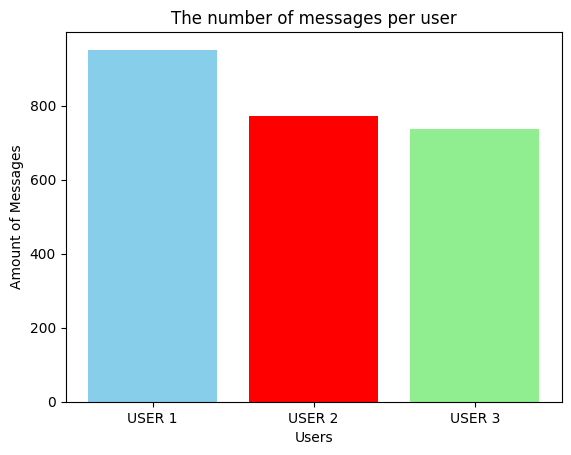

Added 514 Telegram-like samples


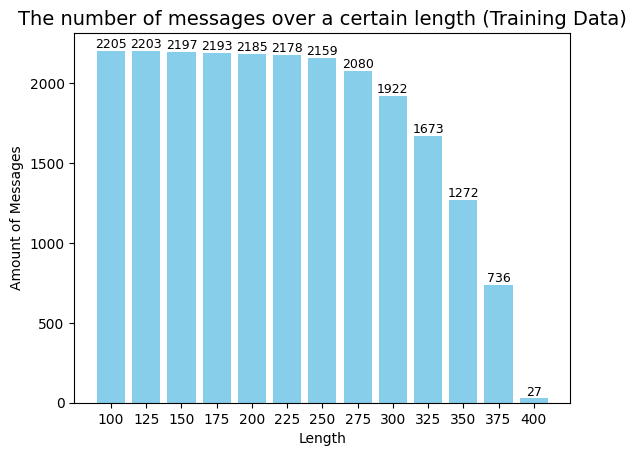

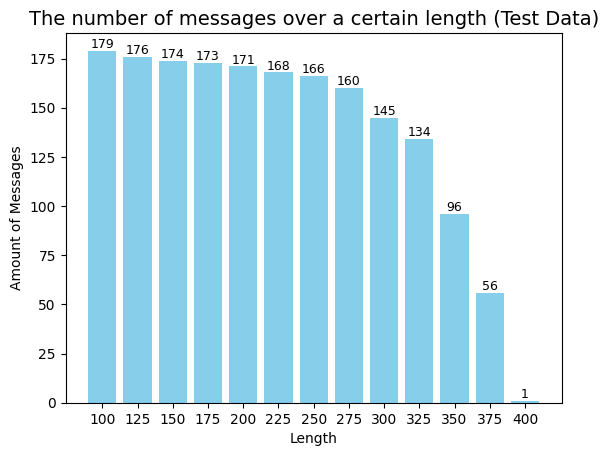

config.json:   0%|          | 0.00/642 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/24.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.65M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  714MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

... (25 outputs left out)

  0%|          | 0/139 [00:00<?, ?it/s]

11 Train loss = 0.7861 Val accuracy = 76.34%


  0%|          | 0/139 [00:00<?, ?it/s]

12 Train loss = 0.7861 Val accuracy = 75.81%
-------------------------------------------------
Stage 1 test Accuracy (FC Only): 76.34%
              precision    recall  f1-score   support

      USER 1       0.81      0.83      0.82        72
      USER 2       0.73      0.83      0.77        58
      USER 3       0.74      0.61      0.67        56

    accuracy                           0.76       186
   macro avg       0.76      0.76      0.75       186
weighted avg       0.76      0.76      0.76       186

-------------------------------------------------
Guesses:
Message #1
  Guess: USER 1
  Confidence by users:
    USER 1: 55.17%
    USER 2: 16.8%
    USER 3: 28.03%
Message #2
  Guess: USER 1
  Confidence by users:
    USER 1: 65.32%
    USER 2: 19.51%
    USER 3: 15.17%
Message #3
  Guess: USER 1
  Confidence by users:
    USER 1: 58.49%
    USER 2: 23.92%
    USER 3: 17.59%
Message #4
  Guess: USER 1
  Confidence by users:
    USER 1: 66.53%
    USER 2: 21.07%
    USER 3: 12.4%

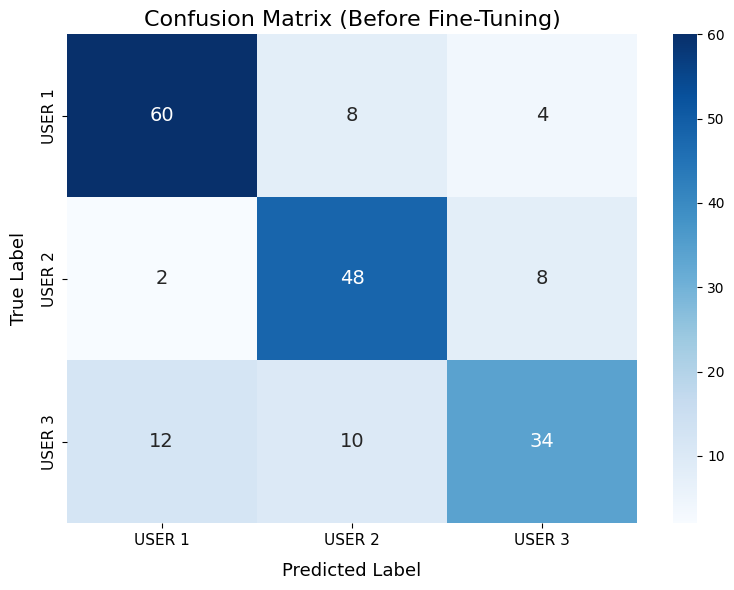

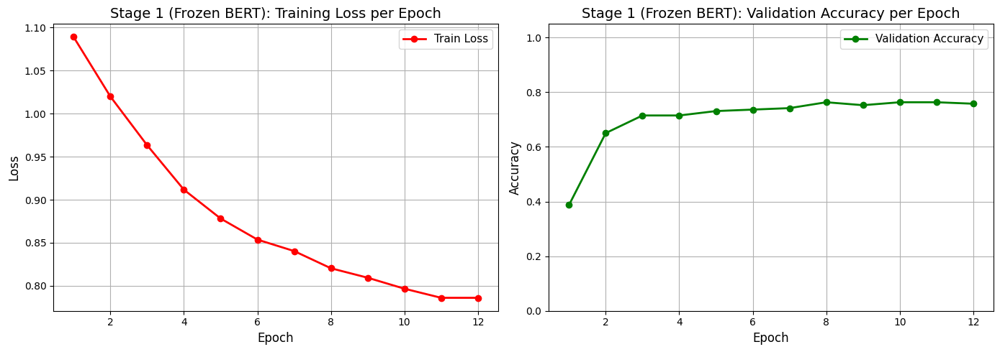

Full Fine-Tuning:


  0%|          | 0/139 [00:00<?, ?it/s]

1 Train loss = 0.5069 Val accuracy = 92.47%


  0%|          | 0/139 [00:00<?, ?it/s]

2 Train loss = 0.0476 Val accuracy = 93.55%


  0%|          | 0/139 [00:00<?, ?it/s]

... (7 outputs left out)

  0%|          | 0/139 [00:00<?, ?it/s]

7 Train loss = 0.0001 Val accuracy = 96.24%


  0%|          | 0/139 [00:00<?, ?it/s]

8 Train loss = 0.0001 Val accuracy = 95.16%
Early Stopping 7


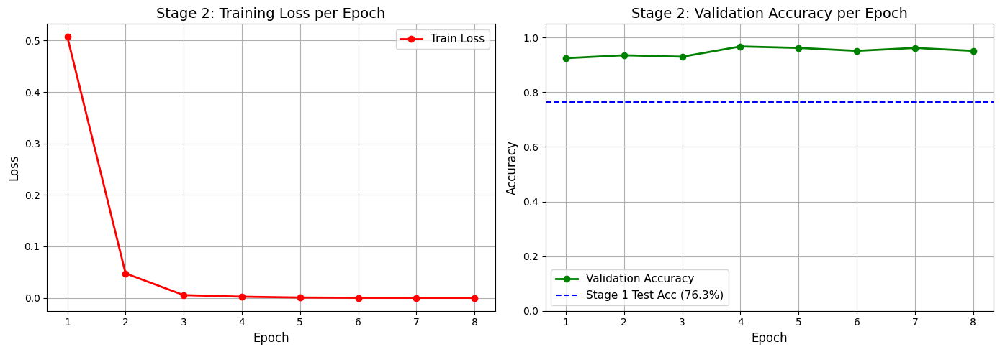

STAGE 1 Test Accuracy: 76.34%
FINAL Test Accuracy (After FT): 89.78%
FINAL F1-macro: 89.65%
Improvement: +13.44%
              precision    recall  f1-score   support

      USER 1       0.96      0.89      0.92        72
      USER 2       0.81      0.97      0.88        58
      USER 3       0.94      0.84      0.89        56

    accuracy                           0.90       186
   macro avg       0.90      0.90      0.90       186
weighted avg       0.91      0.90      0.90       186

Guesses:
Message #1
  Guess: USER 1
  Confidence by users:
    USER 1: 100.0%
    USER 2: 0.0%
    USER 3: 0.0%
Message #2
  Guess: USER 1
  Confidence by users:
    USER 1: 100.0%
    USER 2: 0.0%
    USER 3: 0.0%
Message #3
  Guess: USER 1
  Confidence by users:
    USER 1: 100.0%
    USER 2: 0.0%
    USER 3: 0.0%
Message #4
  Guess: USER 1
  Confidence by users:
    USER 1: 100.0%
    USER 2: 0.0%
    USER 3: 0.0%
Message #5
  Guess: USER 1
  Confidence by users:
    USER 1: 100.0%
    USER 2: 0.0%

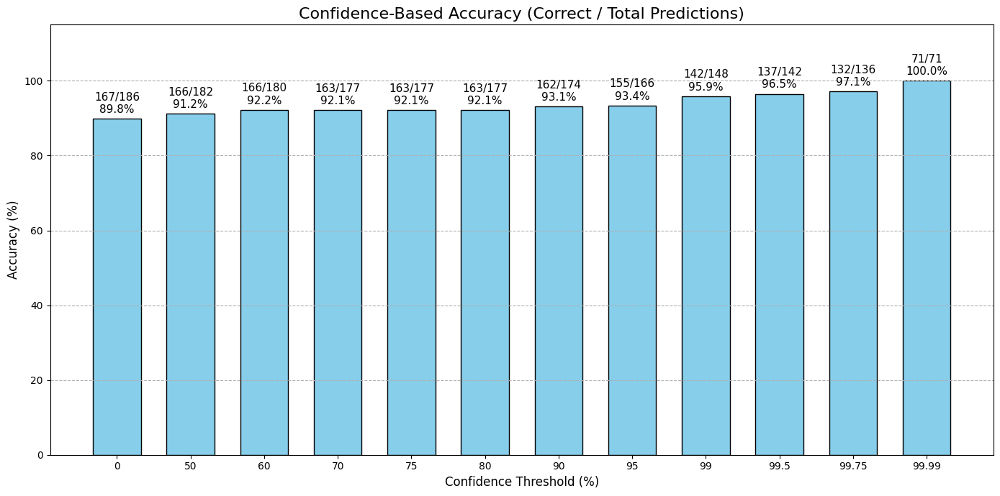

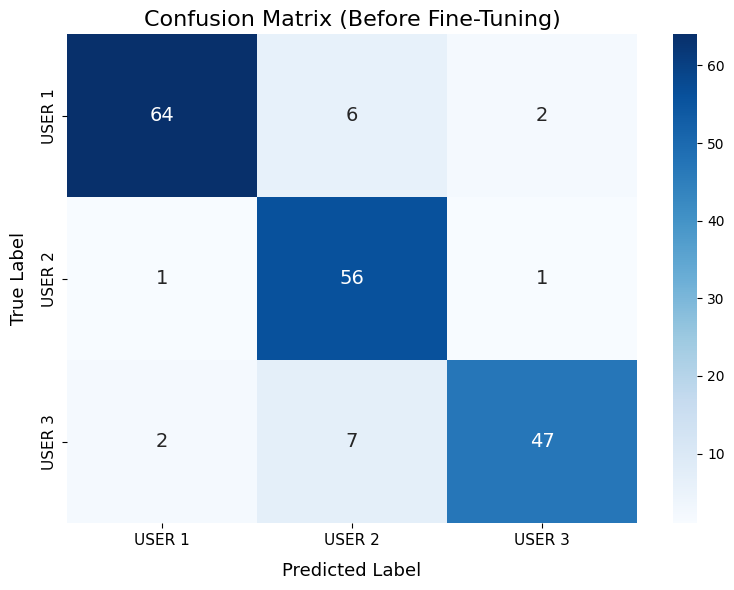

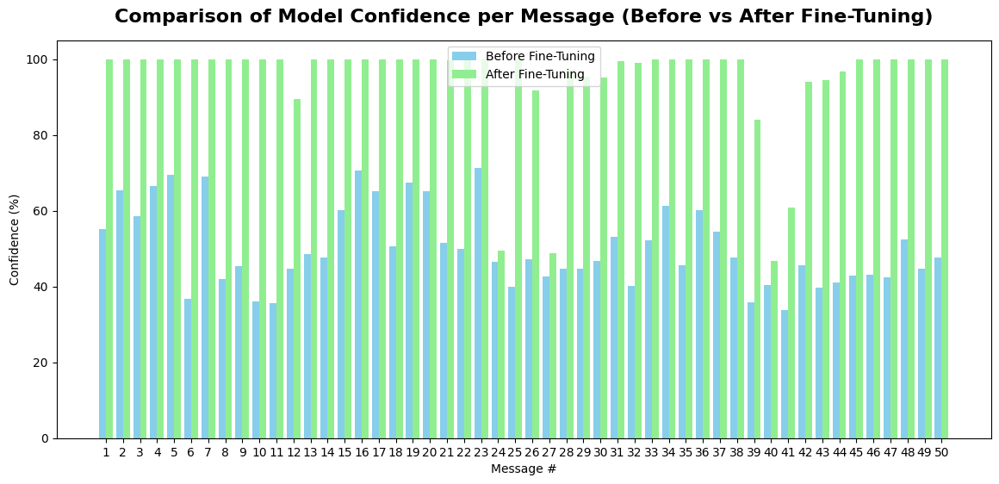

------------------------------------
Seed: 42
------------------------------------
USER 1: 664 train, 72 val, 72 test blocks (out of 951 original messages)
USER 2: 541 train, 58 val, 58 test blocks (out of 773 original messages)
USER 3: 512 train, 56 val, 56 test blocks (out of 736 original messages)
-------------------------------------------------
Train samples: 1717 Avg len: 342.2 chars
Val samples: 186 Avg len: 332.0 chars
Test samples: 186 Avg len: 336.3 chars
-------------------------------------------------


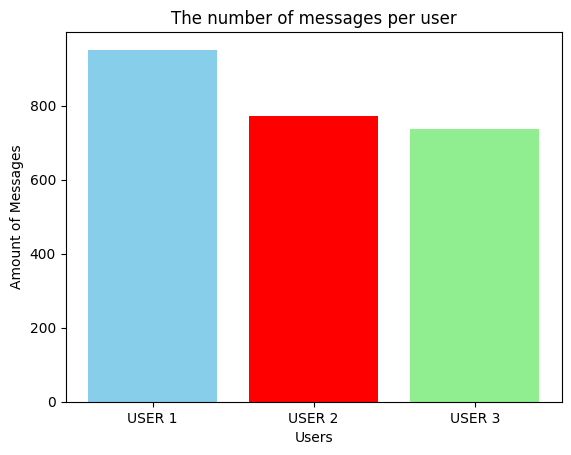

Added 514 Telegram-like samples


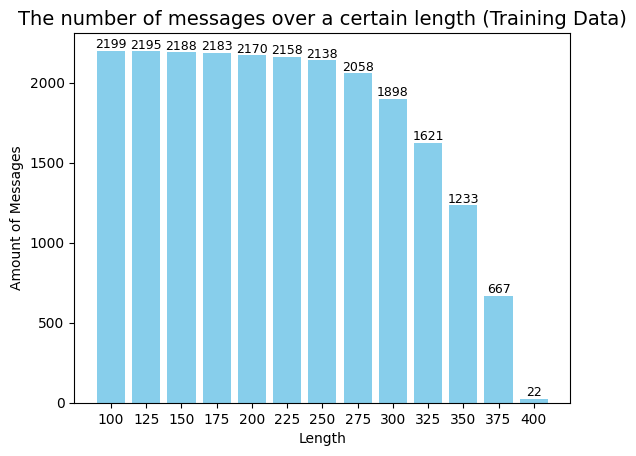

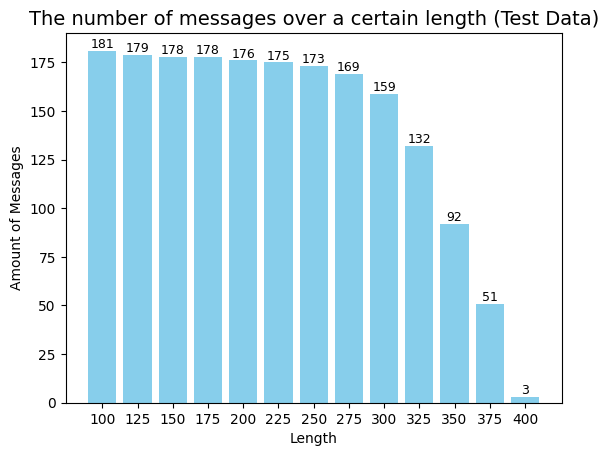

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: DeepPavlov/rubert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those par

Training Frozen Bert:


  0%|          | 0/139 [00:00<?, ?it/s]

1 Train loss = 1.0829 Val accuracy = 44.09%


  0%|          | 0/139 [00:00<?, ?it/s]

... (17 outputs left out)

  0%|          | 0/139 [00:00<?, ?it/s]

11 Train loss = 0.7797 Val accuracy = 81.18%


  0%|          | 0/139 [00:00<?, ?it/s]

12 Train loss = 0.7787 Val accuracy = 81.18%
-------------------------------------------------
Stage 1 test Accuracy (FC Only): 65.59%
              precision    recall  f1-score   support

      USER 1       0.71      0.68      0.70        72
      USER 2       0.58      0.66      0.62        58
      USER 3       0.67      0.62      0.65        56

    accuracy                           0.66       186
   macro avg       0.66      0.65      0.65       186
weighted avg       0.66      0.66      0.66       186

-------------------------------------------------
Guesses:
Message #1
  Guess: USER 1
  Confidence by users:
    USER 1: 59.29%
    USER 2: 29.53%
    USER 3: 11.18%
Message #2
  Guess: USER 1
  Confidence by users:
    USER 1: 46.14%
    USER 2: 38.8%
    USER 3: 15.06%
Message #3
  Guess: USER 1
  Confidence by users:
    USER 1: 40.43%
    USER 2: 36.54%
    USER 3: 23.03%
Message #4
  Guess: USER 2
  Confidence by users:
    USER 1: 33.39%
    USER 2: 35.06%
    USER 3: 31.55

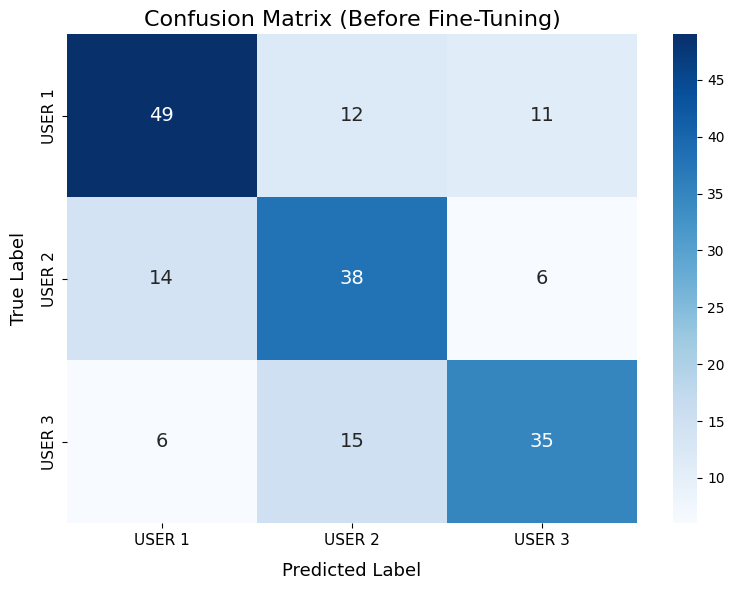

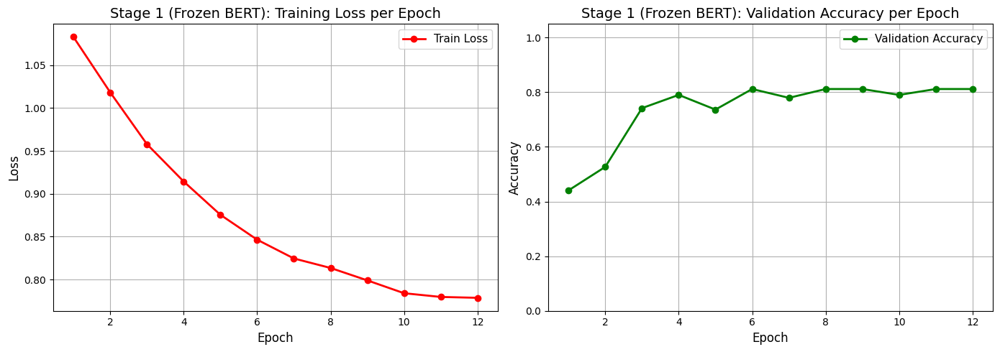

Full Fine-Tuning:


  0%|          | 0/139 [00:00<?, ?it/s]

1 Train loss = 0.5515 Val accuracy = 94.62%


  0%|          | 0/139 [00:00<?, ?it/s]

2 Train loss = 0.0478 Val accuracy = 96.77%


  0%|          | 0/139 [00:00<?, ?it/s]

... (11 outputs left out)

  0%|          | 0/139 [00:00<?, ?it/s]

9 Train loss = 0.0001 Val accuracy = 98.39%


  0%|          | 0/139 [00:00<?, ?it/s]

10 Train loss = 0.0005 Val accuracy = 98.39%
Early Stopping 9


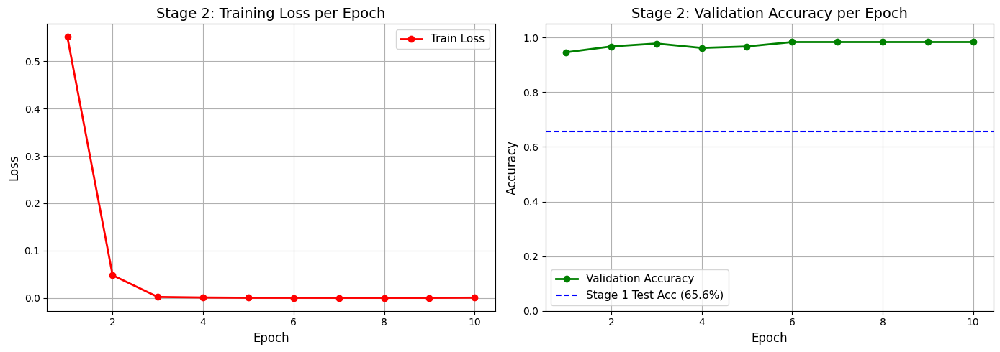

STAGE 1 Test Accuracy: 65.59%
FINAL Test Accuracy (After FT): 93.55%
FINAL F1-macro: 93.41%
Improvement: +27.96%
              precision    recall  f1-score   support

      USER 1       0.96      0.94      0.95        72
      USER 2       0.96      0.88      0.92        58
      USER 3       0.89      0.98      0.93        56

    accuracy                           0.94       186
   macro avg       0.94      0.94      0.93       186
weighted avg       0.94      0.94      0.94       186

Guesses:
Message #1
  Guess: USER 1
  Confidence by users:
    USER 1: 99.96%
    USER 2: 0.04%
    USER 3: 0.0%
Message #2
  Guess: USER 1
  Confidence by users:
    USER 1: 99.99%
    USER 2: 0.01%
    USER 3: 0.0%
Message #3
  Guess: USER 1
  Confidence by users:
    USER 1: 100.0%
    USER 2: 0.0%
    USER 3: 0.0%
Message #4
  Guess: USER 1
  Confidence by users:
    USER 1: 99.99%
    USER 2: 0.01%
    USER 3: 0.0%
Message #5
  Guess: USER 1
  Confidence by users:
    USER 1: 100.0%
    USER 2: 0

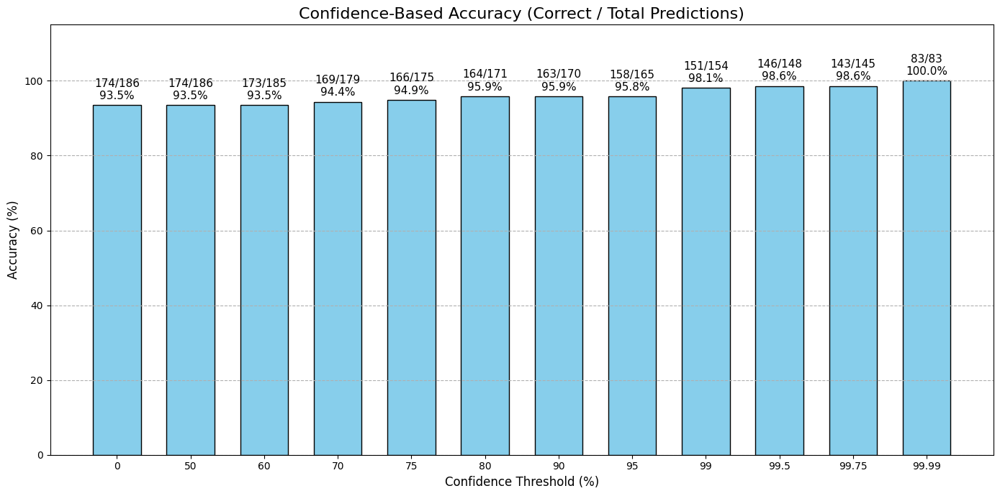

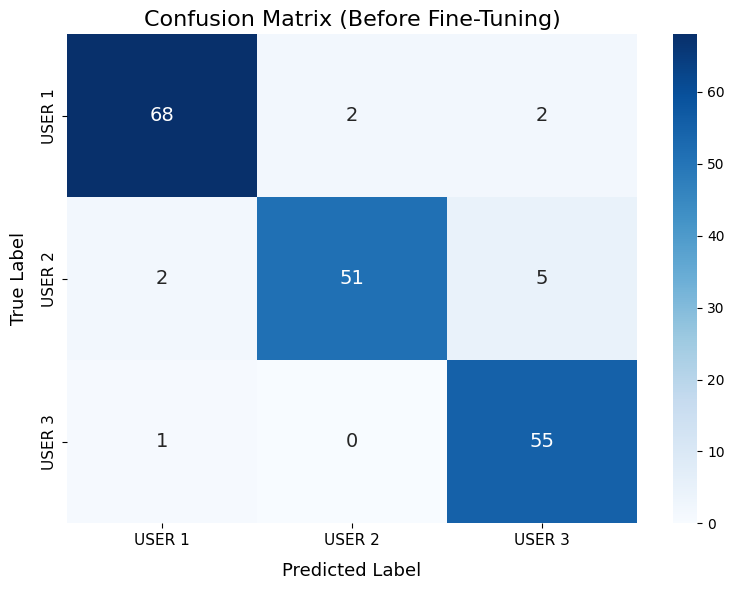

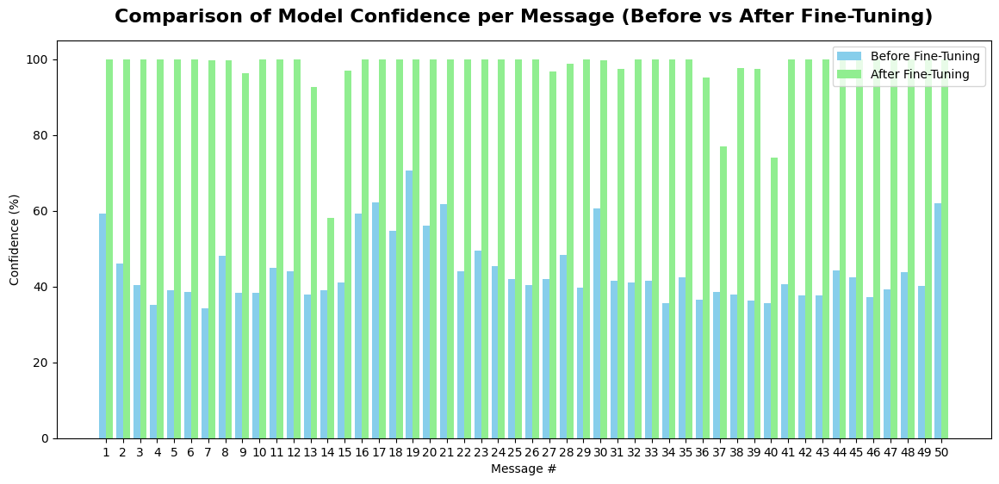

------------------------------------
Seed: 777
------------------------------------
USER 1: 664 train, 72 val, 72 test blocks (out of 951 original messages)
USER 2: 541 train, 58 val, 58 test blocks (out of 773 original messages)
USER 3: 513 train, 56 val, 55 test blocks (out of 736 original messages)
-------------------------------------------------
Train samples: 1718 Avg len: 341.5 chars
Val samples: 186 Avg len: 346.0 chars
Test samples: 185 Avg len: 324.3 chars
-------------------------------------------------


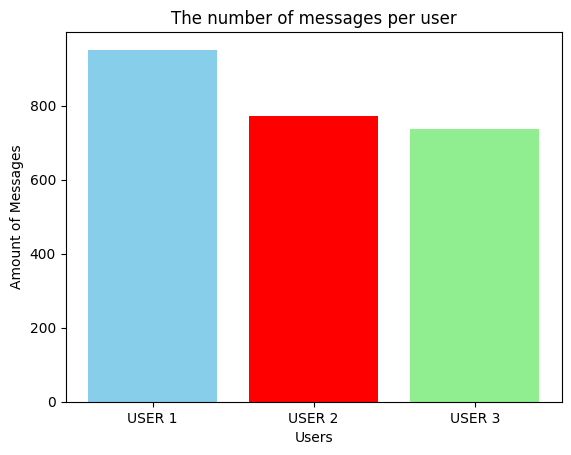

Added 514 Telegram-like samples


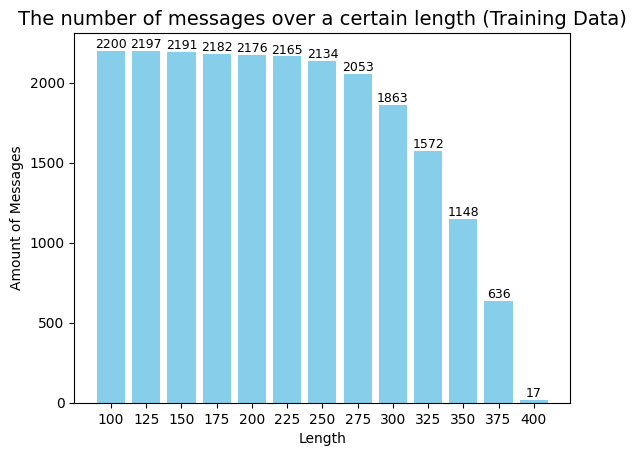

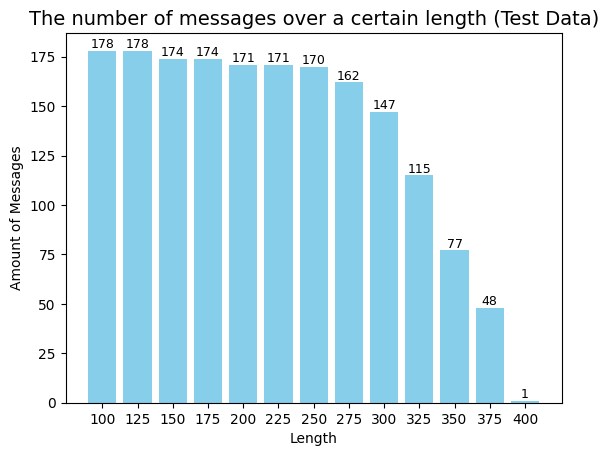

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: DeepPavlov/rubert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those par

Training Frozen Bert:


  0%|          | 0/139 [00:00<?, ?it/s]

1 Train loss = 1.0879 Val accuracy = 43.01%


  0%|          | 0/139 [00:00<?, ?it/s]

... (17 outputs left out)

  0%|          | 0/139 [00:00<?, ?it/s]

11 Train loss = 0.7858 Val accuracy = 73.66%


  0%|          | 0/139 [00:00<?, ?it/s]

12 Train loss = 0.7827 Val accuracy = 73.12%
-------------------------------------------------
Stage 1 test Accuracy (FC Only): 67.57%
              precision    recall  f1-score   support

      USER 1       0.78      0.72      0.75        72
      USER 2       0.66      0.69      0.67        58
      USER 3       0.58      0.60      0.59        55

    accuracy                           0.68       185
   macro avg       0.67      0.67      0.67       185
weighted avg       0.68      0.68      0.68       185

-------------------------------------------------
Guesses:
Message #1
  Guess: USER 3
  Confidence by users:
    USER 1: 25.53%
    USER 2: 33.36%
    USER 3: 41.11%
Message #2
  Guess: USER 3
  Confidence by users:
    USER 1: 34.62%
    USER 2: 29.87%
    USER 3: 35.51%
Message #3
  Guess: USER 3
  Confidence by users:
    USER 1: 33.48%
    USER 2: 30.74%
    USER 3: 35.78%
Message #4
  Guess: USER 3
  Confidence by users:
    USER 1: 31.64%
    USER 2: 30.78%
    USER 3: 37.5

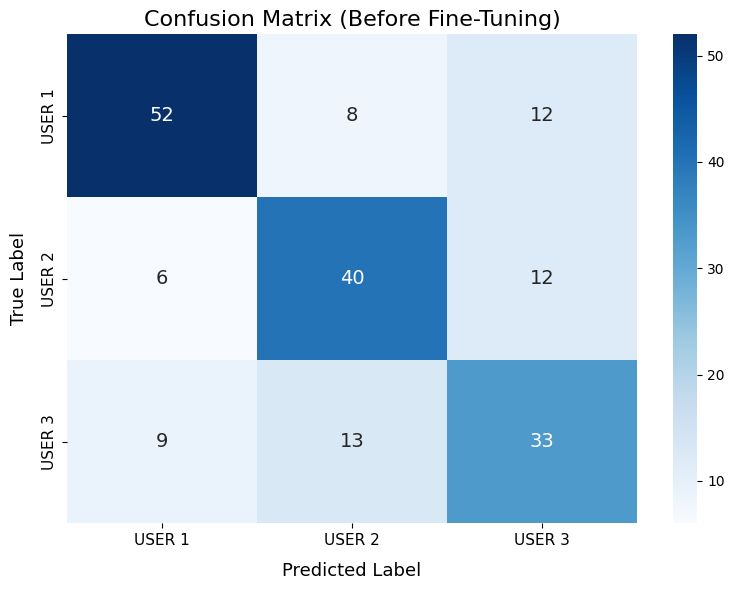

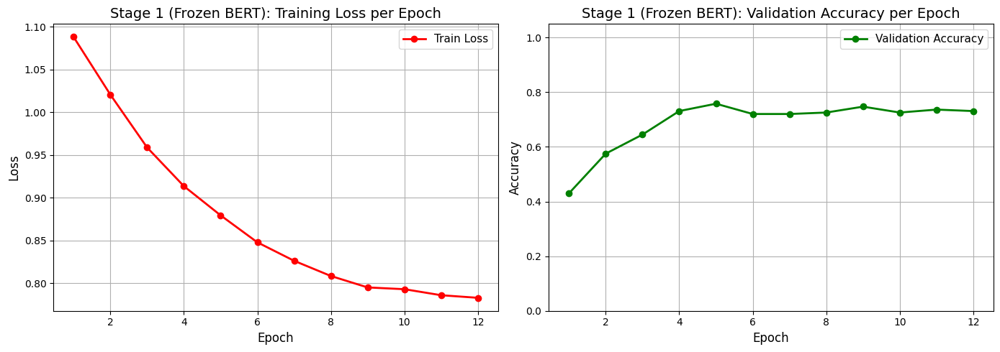

Full Fine-Tuning:


  0%|          | 0/139 [00:00<?, ?it/s]

1 Train loss = 0.5866 Val accuracy = 93.01%


  0%|          | 0/139 [00:00<?, ?it/s]

2 Train loss = 0.0602 Val accuracy = 96.24%


  0%|          | 0/139 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/139 [00:00<?, ?it/s]

5 Train loss = 0.0002 Val accuracy = 96.24%


  0%|          | 0/139 [00:00<?, ?it/s]

6 Train loss = 0.0002 Val accuracy = 96.24%
Early Stopping 5


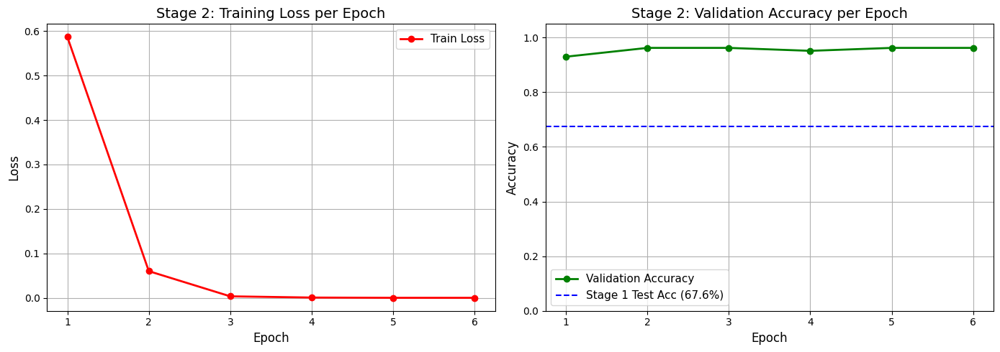

STAGE 1 Test Accuracy: 67.57%
FINAL Test Accuracy (After FT): 88.11%
FINAL F1-macro: 87.89%
Improvement: +20.54%
              precision    recall  f1-score   support

      USER 1       0.91      0.89      0.90        72
      USER 2       0.83      0.93      0.88        58
      USER 3       0.90      0.82      0.86        55

    accuracy                           0.88       185
   macro avg       0.88      0.88      0.88       185
weighted avg       0.88      0.88      0.88       185

Guesses:
Message #1
  Guess: USER 1
  Confidence by users:
    USER 1: 96.84%
    USER 2: 0.31%
    USER 3: 2.86%
Message #2
  Guess: USER 1
  Confidence by users:
    USER 1: 99.17%
    USER 2: 0.09%
    USER 3: 0.74%
Message #3
  Guess: USER 1
  Confidence by users:
    USER 1: 98.8%
    USER 2: 0.19%
    USER 3: 1.01%
Message #4
  Guess: USER 3
  Confidence by users:
    USER 1: 6.37%
    USER 2: 1.32%
    USER 3: 92.31%
Message #5
  Guess: USER 1
  Confidence by users:
    USER 1: 76.18%
    USER 

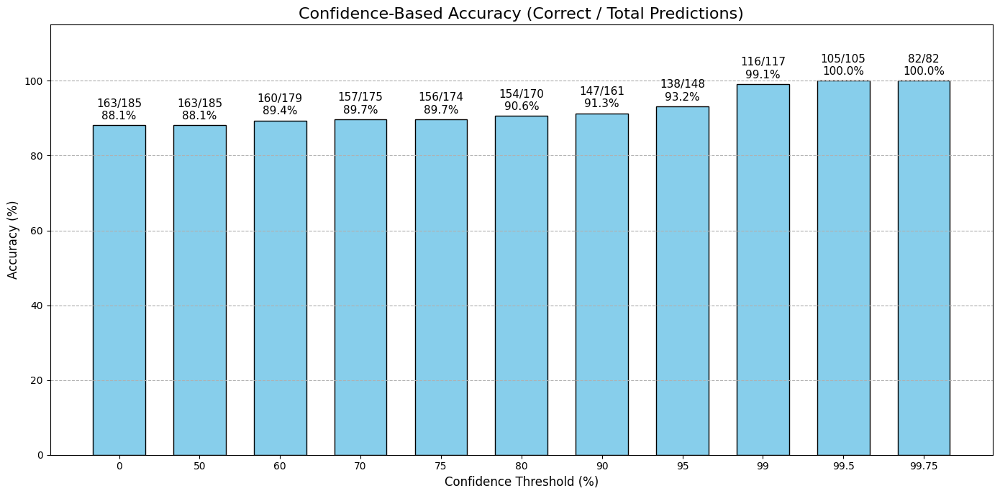

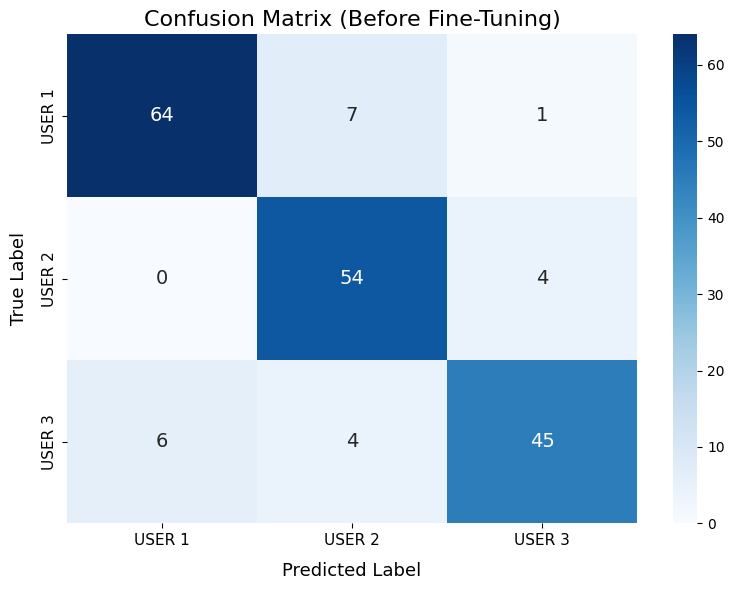

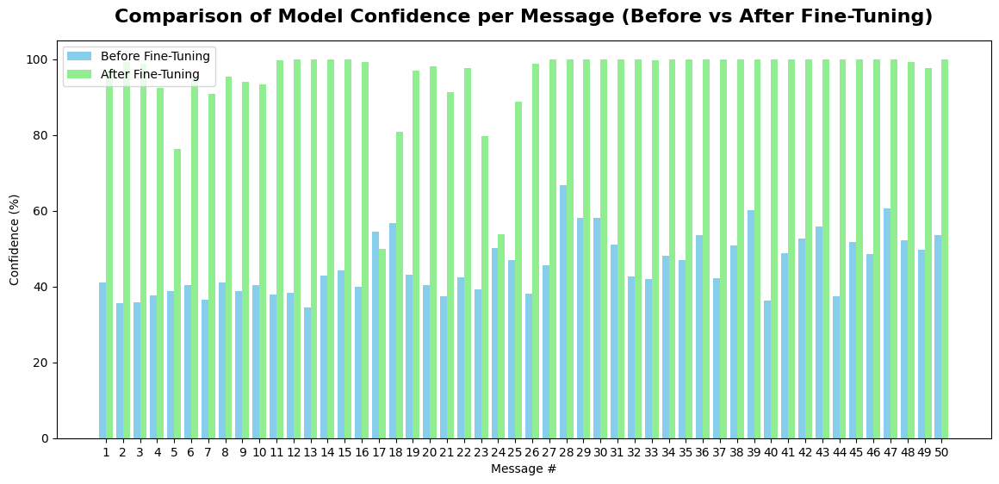

------------------------------------
Seed: 2026
------------------------------------
USER 1: 664 train, 72 val, 72 test blocks (out of 951 original messages)
USER 2: 541 train, 58 val, 58 test blocks (out of 773 original messages)
USER 3: 513 train, 56 val, 56 test blocks (out of 736 original messages)
-------------------------------------------------
Train samples: 1718 Avg len: 344.6 chars
Val samples: 186 Avg len: 325.2 chars
Test samples: 186 Avg len: 337.0 chars
-------------------------------------------------


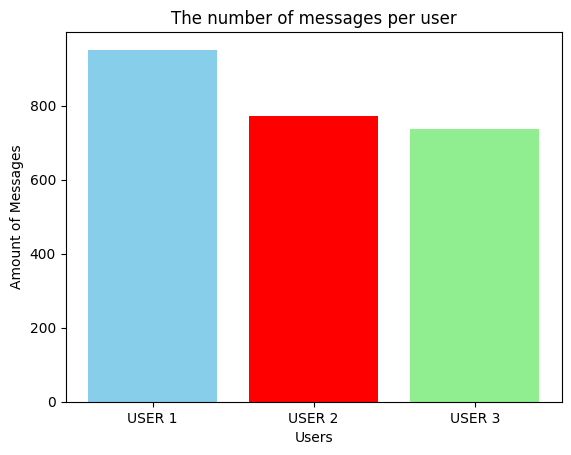

Added 514 Telegram-like samples


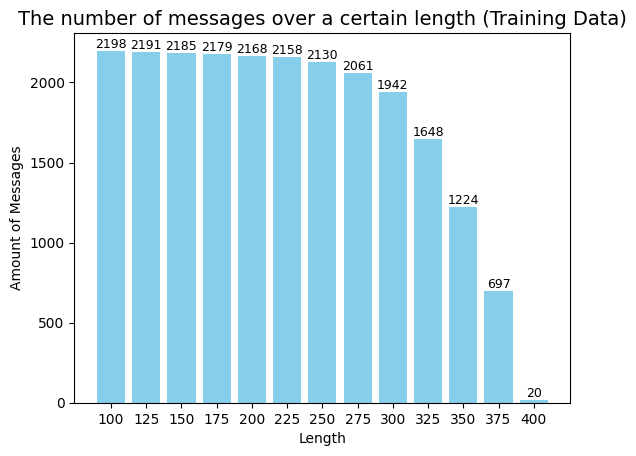

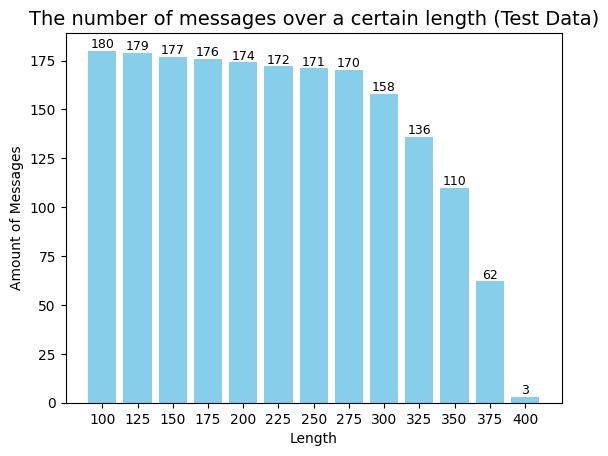

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: DeepPavlov/rubert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those par

Training Frozen Bert:


  0%|          | 0/139 [00:00<?, ?it/s]

1 Train loss = 1.0865 Val accuracy = 42.47%


  0%|          | 0/139 [00:00<?, ?it/s]

... (17 outputs left out)

  0%|          | 0/139 [00:00<?, ?it/s]

11 Train loss = 0.7595 Val accuracy = 75.81%


  0%|          | 0/139 [00:00<?, ?it/s]

12 Train loss = 0.7557 Val accuracy = 75.81%
-------------------------------------------------
Stage 1 test Accuracy (FC Only): 61.29%
              precision    recall  f1-score   support

      USER 1       0.72      0.67      0.69        72
      USER 2       0.53      0.45      0.49        58
      USER 3       0.57      0.71      0.63        56

    accuracy                           0.61       186
   macro avg       0.61      0.61      0.60       186
weighted avg       0.61      0.61      0.61       186

-------------------------------------------------
Guesses:
Message #1
  Guess: USER 1
  Confidence by users:
    USER 1: 54.77%
    USER 2: 26.99%
    USER 3: 18.24%
Message #2
  Guess: USER 1
  Confidence by users:
    USER 1: 44.07%
    USER 2: 33.27%
    USER 3: 22.66%
Message #3
  Guess: USER 2
  Confidence by users:
    USER 1: 26.77%
    USER 2: 44.96%
    USER 3: 28.28%
Message #4
  Guess: USER 1
  Confidence by users:
    USER 1: 57.5%
    USER 2: 30.01%
    USER 3: 12.48

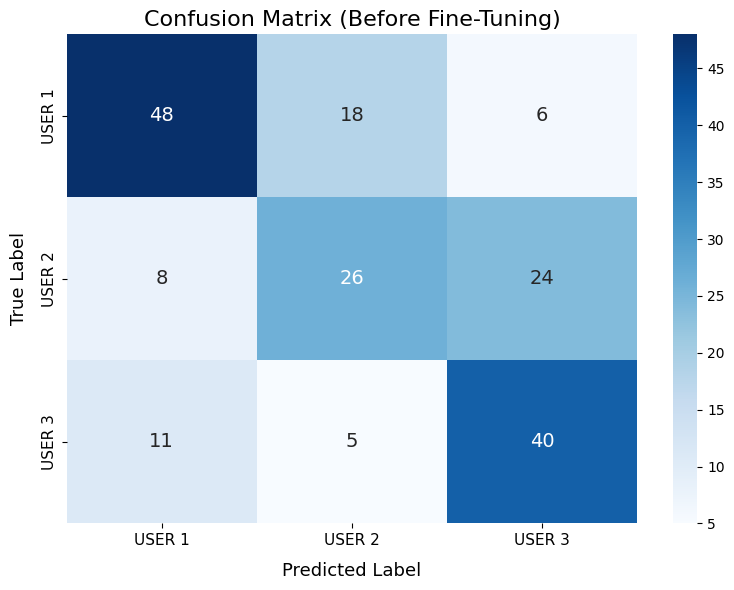

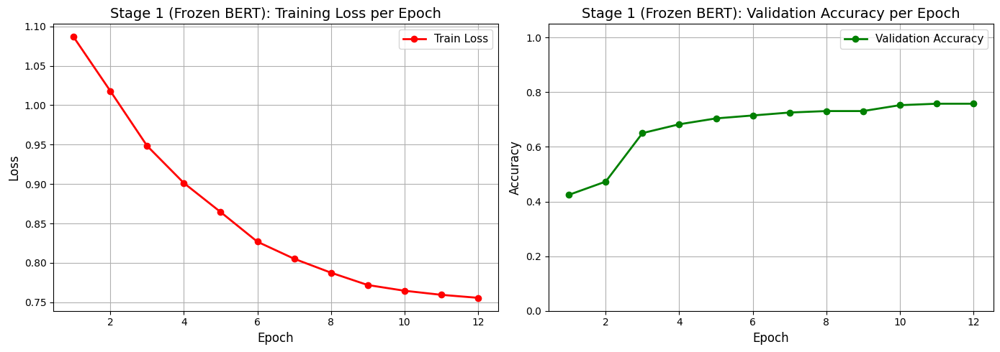

Full Fine-Tuning:


  0%|          | 0/139 [00:00<?, ?it/s]

1 Train loss = 0.4465 Val accuracy = 88.17%


  0%|          | 0/139 [00:00<?, ?it/s]

2 Train loss = 0.0259 Val accuracy = 91.4%


  0%|          | 0/139 [00:00<?, ?it/s]

... (5 outputs left out)

  0%|          | 0/139 [00:00<?, ?it/s]

6 Train loss = 0.0001 Val accuracy = 91.94%


  0%|          | 0/139 [00:00<?, ?it/s]

7 Train loss = 0.0001 Val accuracy = 91.94%
Early Stopping 6


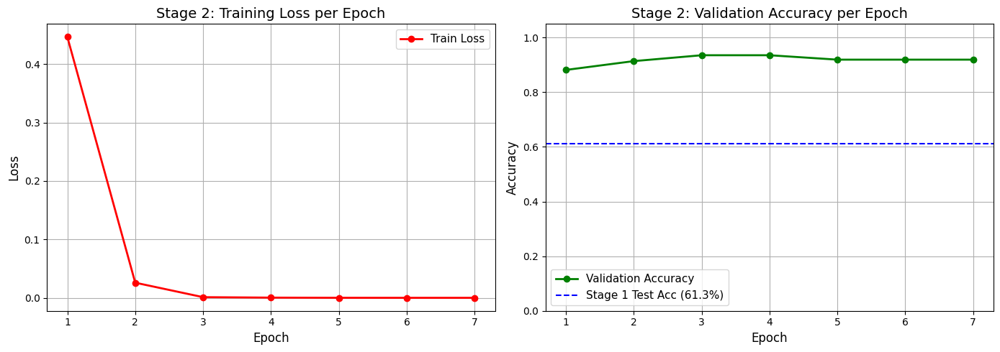

STAGE 1 Test Accuracy: 61.29%
FINAL Test Accuracy (After FT): 89.25%
FINAL F1-macro: 89.18%
Improvement: +27.96%
              precision    recall  f1-score   support

      USER 1       0.98      0.86      0.92        72
      USER 2       0.81      0.90      0.85        58
      USER 3       0.88      0.93      0.90        56

    accuracy                           0.89       186
   macro avg       0.89      0.90      0.89       186
weighted avg       0.90      0.89      0.89       186

Guesses:
Message #1
  Guess: USER 1
  Confidence by users:
    USER 1: 100.0%
    USER 2: 0.0%
    USER 3: 0.0%
Message #2
  Guess: USER 1
  Confidence by users:
    USER 1: 100.0%
    USER 2: 0.0%
    USER 3: 0.0%
Message #3
  Guess: USER 1
  Confidence by users:
    USER 1: 99.99%
    USER 2: 0.0%
    USER 3: 0.0%
Message #4
  Guess: USER 1
  Confidence by users:
    USER 1: 100.0%
    USER 2: 0.0%
    USER 3: 0.0%
Message #5
  Guess: USER 1
  Confidence by users:
    USER 1: 99.78%
    USER 2: 0.22

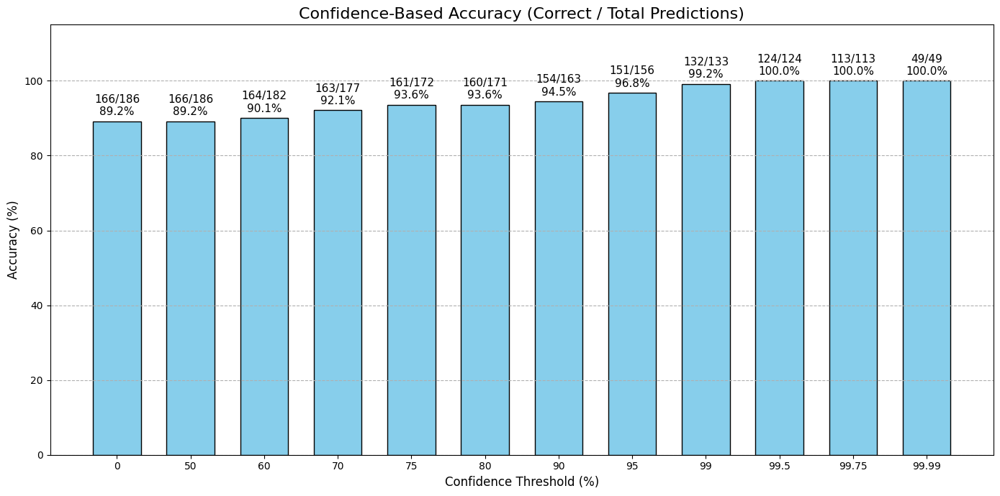

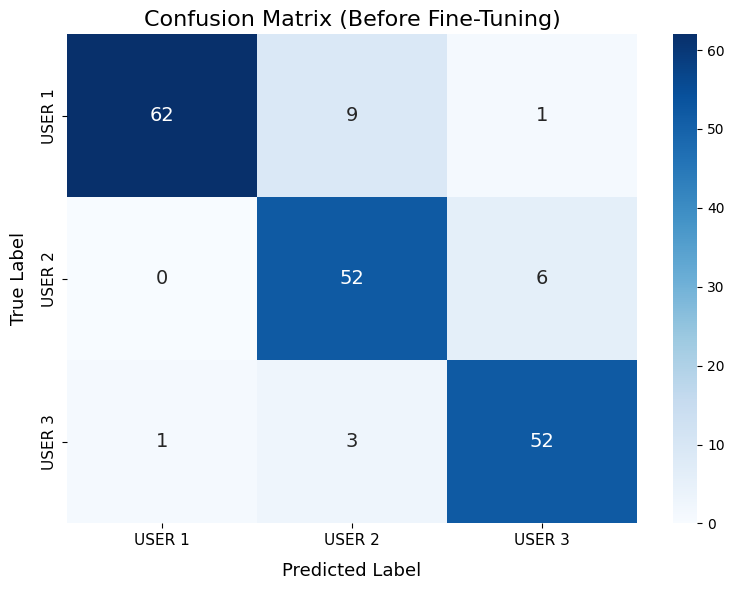

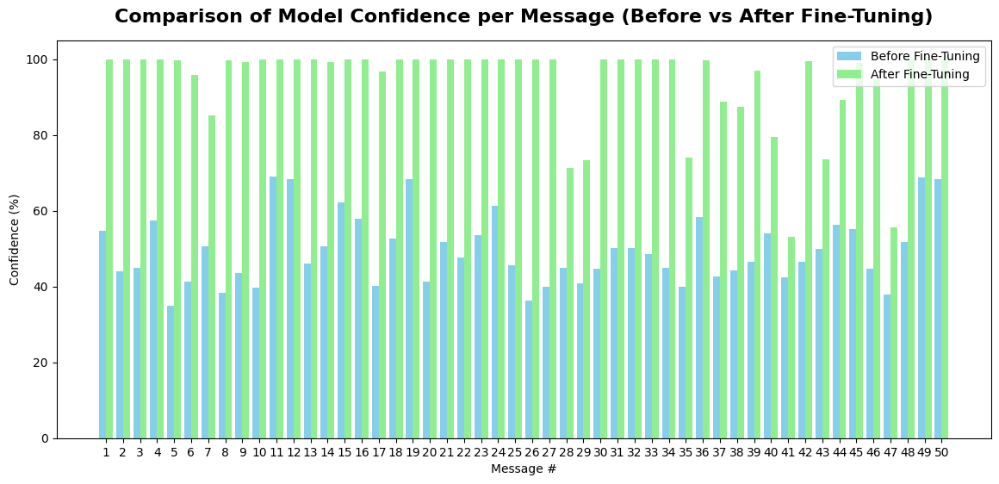

------------------------------------
Seed: 2027
------------------------------------
USER 1: 664 train, 72 val, 72 test blocks (out of 951 original messages)
USER 2: 541 train, 58 val, 58 test blocks (out of 773 original messages)
USER 3: 512 train, 56 val, 56 test blocks (out of 736 original messages)
-------------------------------------------------
Train samples: 1717 Avg len: 342.3 chars
Val samples: 186 Avg len: 333.5 chars
Test samples: 186 Avg len: 341.4 chars
-------------------------------------------------


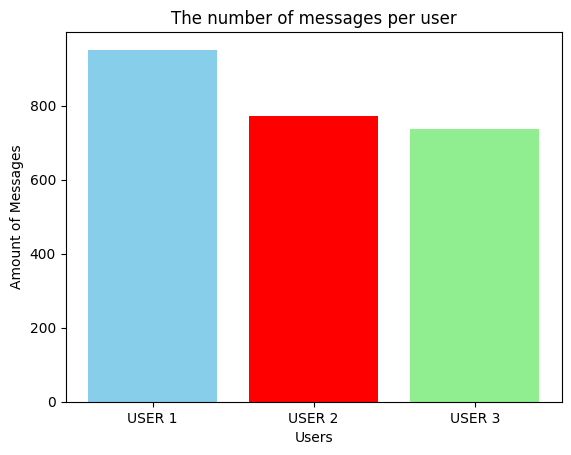

Added 514 Telegram-like samples


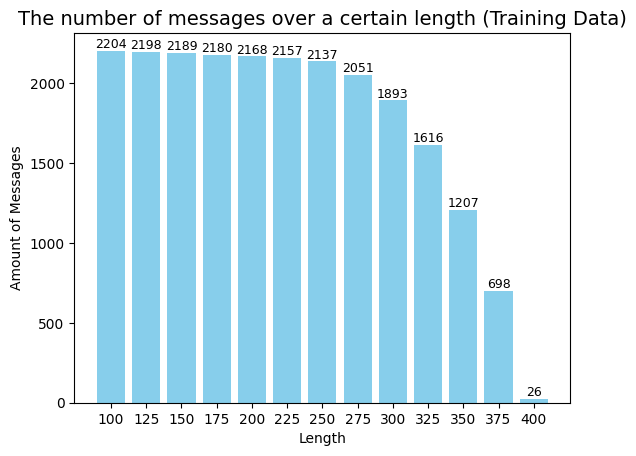

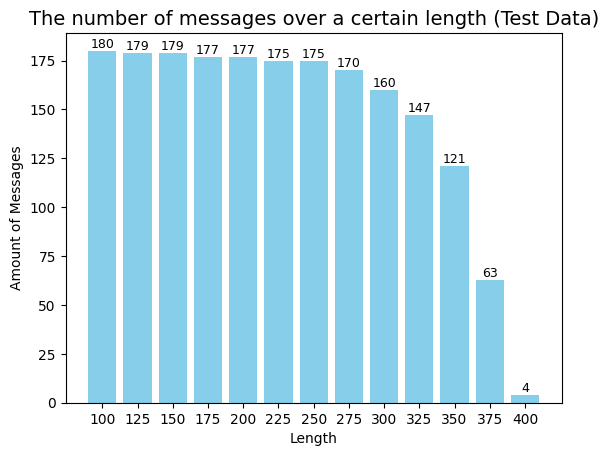

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: DeepPavlov/rubert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those par

Training Frozen Bert:


  0%|          | 0/140 [00:00<?, ?it/s]

1 Train loss = 1.0776 Val accuracy = 39.78%


  0%|          | 0/140 [00:00<?, ?it/s]

... (17 outputs left out)

  0%|          | 0/140 [00:00<?, ?it/s]

11 Train loss = 0.7641 Val accuracy = 74.19%


  0%|          | 0/140 [00:00<?, ?it/s]

12 Train loss = 0.7613 Val accuracy = 74.73%
-------------------------------------------------
Stage 1 test Accuracy (FC Only): 73.12%
              precision    recall  f1-score   support

      USER 1       0.79      0.86      0.83        72
      USER 2       0.66      0.57      0.61        58
      USER 3       0.71      0.73      0.72        56

    accuracy                           0.73       186
   macro avg       0.72      0.72      0.72       186
weighted avg       0.73      0.73      0.73       186

-------------------------------------------------
Guesses:
Message #1
  Guess: USER 3
  Confidence by users:
    USER 1: 31.24%
    USER 2: 18.44%
    USER 3: 50.32%
Message #2
  Guess: USER 1
  Confidence by users:
    USER 1: 62.33%
    USER 2: 15.89%
    USER 3: 21.78%
Message #3
  Guess: USER 1
  Confidence by users:
    USER 1: 49.31%
    USER 2: 23.76%
    USER 3: 26.93%
Message #4
  Guess: USER 1
  Confidence by users:
    USER 1: 50.62%
    USER 2: 24.82%
    USER 3: 24.5

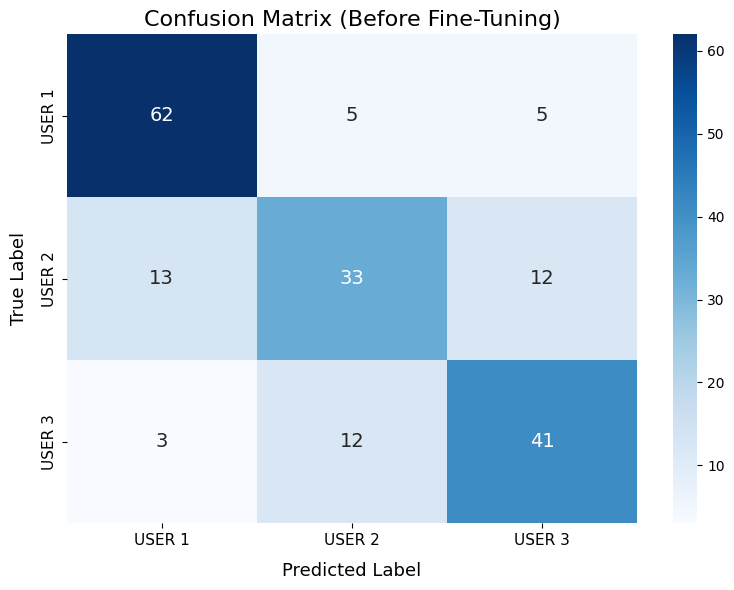

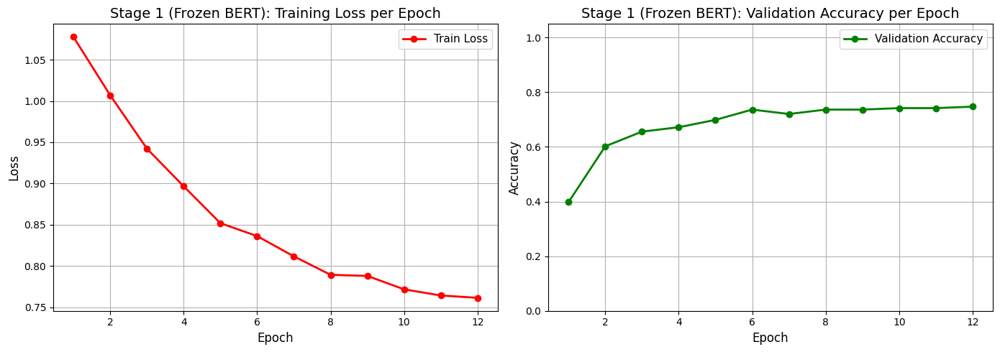

Full Fine-Tuning:


  0%|          | 0/140 [00:00<?, ?it/s]

1 Train loss = 0.4613 Val accuracy = 90.86%


  0%|          | 0/140 [00:00<?, ?it/s]

2 Train loss = 0.0236 Val accuracy = 94.09%


  0%|          | 0/140 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/140 [00:00<?, ?it/s]

5 Train loss = 0.0017 Val accuracy = 94.09%


  0%|          | 0/140 [00:00<?, ?it/s]

6 Train loss = 0.0001 Val accuracy = 94.09%
Early Stopping 5


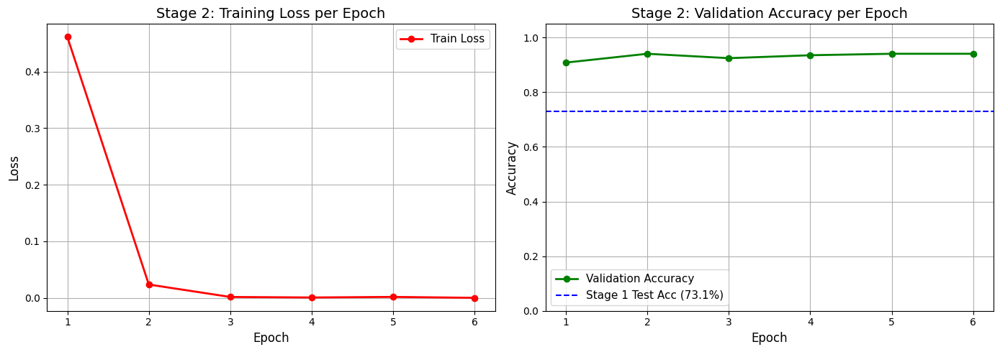

STAGE 1 Test Accuracy: 73.12%
FINAL Test Accuracy (After FT): 90.86%
FINAL F1-macro: 90.42%
Improvement: +17.74%
              precision    recall  f1-score   support

      USER 1       0.93      0.96      0.95        72
      USER 2       0.94      0.79      0.86        58
      USER 3       0.86      0.96      0.91        56

    accuracy                           0.91       186
   macro avg       0.91      0.91      0.90       186
weighted avg       0.91      0.91      0.91       186

Guesses:
Message #1
  Guess: USER 1
  Confidence by users:
    USER 1: 99.91%
    USER 2: 0.0%
    USER 3: 0.09%
Message #2
  Guess: USER 1
  Confidence by users:
    USER 1: 100.0%
    USER 2: 0.0%
    USER 3: 0.0%
Message #3
  Guess: USER 1
  Confidence by users:
    USER 1: 99.99%
    USER 2: 0.0%
    USER 3: 0.0%
Message #4
  Guess: USER 1
  Confidence by users:
    USER 1: 99.99%
    USER 2: 0.0%
    USER 3: 0.01%
Message #5
  Guess: USER 1
  Confidence by users:
    USER 1: 99.99%
    USER 2: 0.

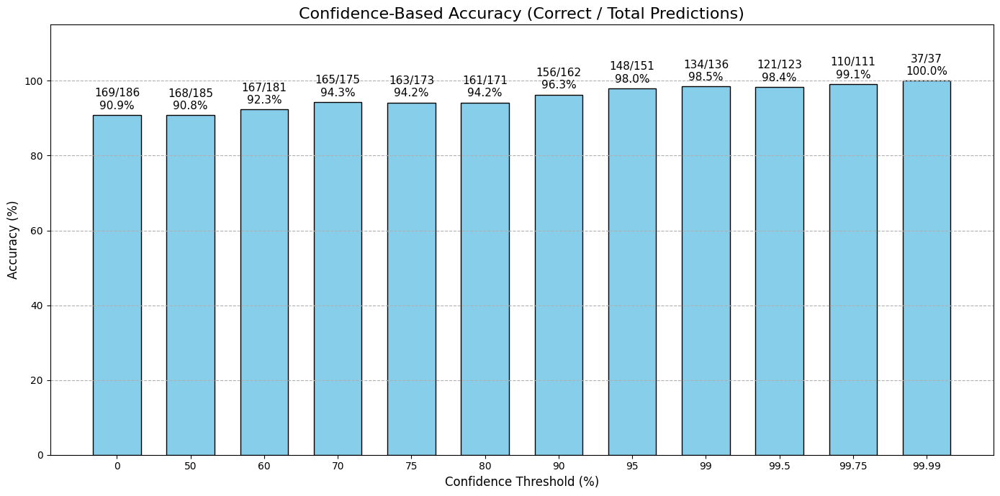

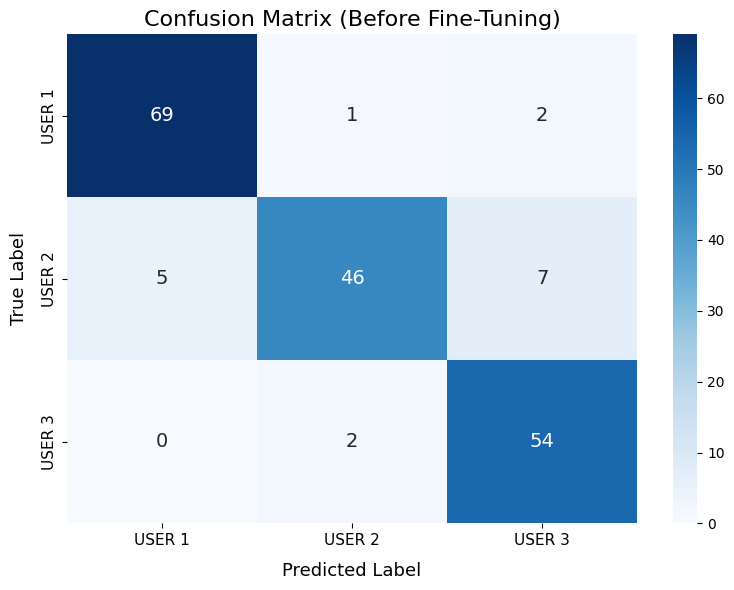

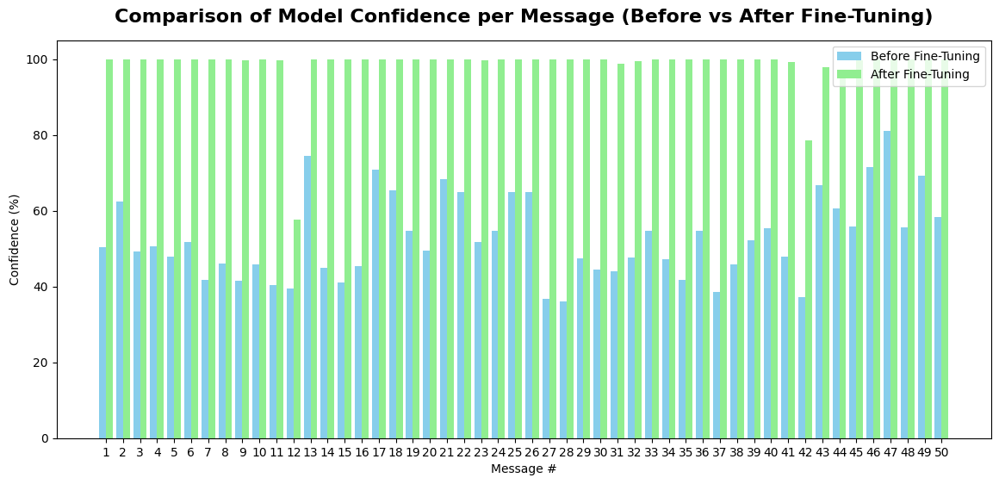

------------------------------------
Overall Accuracy: 90.31% ± 1.85%


In [ ]:
# 5 tests with dropout = 0.05
seed_test = [1, 42, 777, 2026, 2027]
accuracy_seeds = []
for seed in seed_test:
    print('------------------------------------')
    print('Seed:', seed)
    print('------------------------------------')
    model, tokenizer, le, accuracy = run_model_simulation(True, seed, [True, True, True], True, 0.05)
    accuracy_seeds.append(accuracy)

acc_avg = np.sum(accuracy_seeds) / len(seed_test)
acc_std = np.std(accuracy_seeds)
print('------------------------------------')
print('Overall Accuracy:', str(round(acc_avg * 100, 2)) + '% ±', str(round(acc_std * 100, 2)) + '%')

# **Results:**

**The highest validation accuracy and the test accuracy for each seed are shown below:**

**val acc | test acc | delta (diff)**

**Seed 1: 96.77% | 89.78% | -6.99%**

**Seed 42: 98.39% | 93.55% | -4.84%**

**Seed 777: 96.24% | 88.11% | -8.13%**

**Seed 2026: 93.55% | 89.25% | -4.30%**

**Seed 2027: 94.09% | 90.86% | -3.23%**

**-----------------------------------**

**Overall Test Accuracy: 90.31% ± 1.85%**

**Average delta (diff): -5.50%**

**Compared to the results obtained with a *dropout rate of 0.15*, the model improved noticeably. The test accuracy has increased, the standard deviation has decreased, and the overfitting is not as severe as before.**

**This seems to indicate that *dropout rate of 0.15* was too high and we were losing some valuable information. However, let's conduct one final experiment with a *dropout rate of 0.08* to see whether the results would improve (because in reality, since there is an overfitting problem, we would probably still like to increase the dropout rate).**

# **Trying the same 5 seeds with dropout = 0.08(verbose=False):**

In [ ]:
# 5 tests with dropout = 0.08
seed_test = [1, 42, 777, 2026, 2027]
accuracy_seeds = []
for seed in seed_test:
    print('------------------------------------')
    print('Seed:', seed)
    print('------------------------------------')
    model, tokenizer, le, accuracy = run_model_simulation(True, seed, [True, True, True], False, 0.08)
    accuracy_seeds.append(accuracy)

acc_avg = np.sum(accuracy_seeds) / len(seed_test)
acc_std = np.std(accuracy_seeds)
print('------------------------------------')
print('Overall Accuracy:', str(round(acc_avg * 100, 2)) + '% ±', str(round(acc_std * 100, 2)) + '%')

------------------------------------
Seed: 1
------------------------------------
USER 1: 665 train, 72 val, 72 test blocks (out of 951 original messages)
USER 2: 541 train, 58 val, 58 test blocks (out of 773 original messages)
USER 3: 512 train, 56 val, 56 test blocks (out of 736 original messages)
-------------------------------------------------
Train samples: 1718 Avg len: 346.2 chars
Val samples: 186 Avg len: 325.5 chars
Test samples: 186 Avg len: 328.1 chars
-------------------------------------------------
Added 514 Telegram-like samples


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: DeepPavlov/rubert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those par

Training Frozen Bert:


  0%|          | 0/139 [00:00<?, ?it/s]

1 Train loss = 1.0907 Val accuracy = 38.71%


... (212 outputs left out)

  0%|          | 0/140 [00:00<?, ?it/s]

9 Train loss = 0.0001 Val accuracy = 95.16%


  0%|          | 0/140 [00:00<?, ?it/s]

10 Train loss = 0.0001 Val accuracy = 95.16%
Early Stopping 9
STAGE 1 Test Accuracy: 73.12%
FINAL Test Accuracy (After FT): 90.32%
FINAL F1-macro: 89.81%
Improvement: +17.2%
              precision    recall  f1-score   support

      USER 1       0.97      0.96      0.97        72
      USER 2       0.88      0.84      0.86        58
      USER 3       0.85      0.89      0.87        56

    accuracy                           0.90       186
   macro avg       0.90      0.90      0.90       186
weighted avg       0.90      0.90      0.90       186

------------------------------------
Overall Accuracy: 90.31% ± 2.09%


# **Results:**

**The highest validation accuracy and the test accuracy for each seed are shown below:**

**val acc | test acc | delta (diff)**

**Seed 1: 97.31% | 90.86% | -6.45%**

**Seed 42: 98.39% | 93.55% | -4.84%**

**Seed 777: 96.77% | 87.03% | -9.74%**

**Seed 2026: 91.94% | 89.78% | -2.16%**

**Seed 2027: 95.16% | 90.32% | -4.84%**

**-----------------------------------**

**Overall Test Accuracy: 90.31% ± 2.09%**

**Average delta (diff): -5.60%**

**Compared to *dropout=0.15*, *dropout=0.08* is still better. However, compared to *dropout=0.05*, the results might seem to have slightly worsened.**

**(The accuracy has not changed, the standard deviation increased from 1.85% to 2.09%, and the average delta changed slightly from -5.50% to -5.60%.)**

**However, I would not consider this sufficient evidence to conclude that *dropout=0.08* is "worse" than *dropout=0.05* (because we used only 5 seeds and the difference is not significant).**

**For the final test with 10 seeds, I will stick with the theory and use *dropout=0.08* (the theory suggests that it is probably better to use a higher dropout rate, but not too high).**

# **Final test with different 10 seeds with dropout = 0.08(verbose=False):**

In [ ]:
# 10 tests with the best dropout
seed_test = [2, 4, 8, 16, 32, 64, 128, 256, 512, 1024] # different seeds
accuracy_seeds = []
for seed in seed_test:
    print('------------------------------------')
    print('Seed:', seed)
    print('------------------------------------')
    model, tokenizer, le, accuracy = run_model_simulation(True, seed, [True, True, True], False, 0.08)
    accuracy_seeds.append(accuracy)

acc_avg = np.sum(accuracy_seeds) / len(seed_test)
acc_std = np.std(accuracy_seeds)
print('------------------------------------')
print('Overall Accuracy:', str(round(acc_avg * 100, 2)) + '% ±', str(round(acc_std * 100, 2)) + '%')

------------------------------------
Seed: 2
------------------------------------
USER 1: 664 train, 72 val, 72 test blocks (out of 951 original messages)
USER 2: 541 train, 58 val, 58 test blocks (out of 773 original messages)
USER 3: 513 train, 56 val, 56 test blocks (out of 736 original messages)
-------------------------------------------------
Train samples: 1718 Avg len: 342.4 chars
Val samples: 186 Avg len: 338.3 chars
Test samples: 186 Avg len: 329.2 chars
-------------------------------------------------
Added 514 Telegram-like samples


config.json:   0%|          | 0.00/642 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/24.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.65M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  714MB            

... (411 outputs left out)

  0%|          | 0/140 [00:00<?, ?it/s]

9 Train loss = 0.0001 Val accuracy = 95.7%


  0%|          | 0/140 [00:00<?, ?it/s]

10 Train loss = 0.0001 Val accuracy = 95.7%
Early Stopping 9
STAGE 1 Test Accuracy: 65.59%
FINAL Test Accuracy (After FT): 91.94%
FINAL F1-macro: 91.92%
Improvement: +26.34%
              precision    recall  f1-score   support

      USER 1       1.00      0.86      0.93        72
      USER 2       0.87      0.93      0.90        58
      USER 3       0.89      0.98      0.93        56

    accuracy                           0.92       186
   macro avg       0.92      0.92      0.92       186
weighted avg       0.93      0.92      0.92       186

------------------------------------
Overall Accuracy: 92.57% ± 3.41%


# **Results:**

**The highest validation accuracy and the test accuracy for each seed are shown below:**

**val acc | test acc | delta (diff)**

**Seed 2: 88.17% | 94.09% | +5.92%**

**Seed 4: 92.97% | 90.86% | -2.11%**

**Seed 8: 90.81% | 93.01% | +2.20%**

**Seed 16: 95.70% | 94.62% | -1.08%**

**Seed 32: 95.70% | 96.24% | +0.54%**

**Seed 64: 86.49% | 87.63% | +1.14%**

**Seed 128: 96.24% | 94.09% | -2.15%**

**Seed 256: 94.09% | 97.31% | +3.22%**

**Seed 512: 89.78% | 85.95% | -3.83%**

**Seed 1024: 96.77% | 91.94% | -4.83%**

**-----------------------------------**

**Overall Test Accuracy: 92.57% ± 3.41%**

**Average delta (diff): -0.098%**

**Testing on 10 brand-new seeds showed that the overall test accuracy rose from 90.31% to 92.57%, which is slightly better, and the average delta is only around -0.1%, which is negligible. This shows that the model does not overfit, on average, across many seeds.**

# **Experimentation:**
# **Testing different scenarios:**

**1) Lets actually verify whether or not augmentation actually benefites or weakens the model:**

In [12]:
# 5 tests with the best dropout but no augmentation
seed_test = [2, 4, 8, 16, 32]
accuracy_seeds = []
for seed in seed_test:
    print('------------------------------------')
    print('Seed:', seed)
    print('------------------------------------')
    model, tokenizer, le, accuracy = run_model_simulation(False, seed, [True, True, True], False, 0.08)
    accuracy_seeds.append(accuracy)

acc_avg = np.sum(accuracy_seeds) / len(seed_test)
acc_std = np.std(accuracy_seeds)
print('------------------------------------')
print('Overall Accuracy:', str(round(acc_avg * 100, 2)) + '% ±', str(round(acc_std * 100, 2)) + '%')

------------------------------------
Seed: 2
------------------------------------
USER 1: 664 train, 72 val, 72 test blocks (out of 951 original messages)
USER 2: 541 train, 58 val, 58 test blocks (out of 773 original messages)
USER 3: 513 train, 56 val, 56 test blocks (out of 736 original messages)
-------------------------------------------------
Train samples: 1718 Avg len: 342.4 chars
Val samples: 186 Avg len: 338.3 chars
Test samples: 186 Avg len: 329.2 chars
-------------------------------------------------
Added 0 Telegram-like samples


config.json:   0%|          | 0.00/642 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/24.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.65M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  714MB            

... (208 outputs left out)

  0%|          | 0/108 [00:00<?, ?it/s]

8 Train loss = 0.0002 Val accuracy = 94.62%


  0%|          | 0/108 [00:00<?, ?it/s]

9 Train loss = 0.0002 Val accuracy = 94.62%
Early Stopping 8
STAGE 1 Test Accuracy: 73.12%
FINAL Test Accuracy (After FT): 95.7%
FINAL F1-macro: 95.76%
Improvement: +22.58%
              precision    recall  f1-score   support

      USER 1       0.96      0.94      0.95        72
      USER 2       0.93      0.98      0.96        58
      USER 3       0.98      0.95      0.96        56

    accuracy                           0.96       186
   macro avg       0.96      0.96      0.96       186
weighted avg       0.96      0.96      0.96       186

------------------------------------
Overall Accuracy: 92.9% ± 1.71%


# **Results:**

**The highest validation accuracy and the test accuracy for each seed are shown below:**

**val acc | test acc | delta (diff)**

# **No Augmentation:**

**Seed 2: 87.10% | 91.94% | +4.84%**

**Seed 4: 91.35% | 91.40% | +0.05%**

**Seed 8: 89.73% | 91.40% | +1.67%**

**Seed 16: 94.62% | 94.09% | -0.53%**

**Seed 32: 95.70% | 95.70% | +0.00%**

**Overall Test Accuracy: 92.9% ± 1.71%**

**Average delta (diff): +1.206%**

# **With Augmentation (same data as in the previous experiment):**

**Seed 2: 88.17% | 94.09% | +5.92%**

**Seed 4: 92.97% | 90.86% | -2.11%**

**Seed 8: 90.81% | 93.01% | +2.20%**

**Seed 16: 95.70% | 94.62% | -1.08%**

**Seed 32: 95.70% | 96.24% | +0.54%**

**Overall Test Accuracy: 93.76% ± 1.79%**

**Average delta (diff): +1.094%**

# **Observation:**

**We can clearly see that using augmentation benefits the model slightly.**

**The average accuracy is higher (93.76% is higher than 92.9%), and the *standard deviation* and *average delta* are *essentially the same*. We can conclude that my augmentation methods were safe and beneficial.**

**2) Let's check the model's performance with 5 seeds if the dataset is reduced from all three users to just two, and observe its accuracy in differentiating USER 1 vs USER 2, USER 1 vs USER 3, and USER 2 vs USER 3.**

In [ ]:
# 5 tests with the best dropout(2 people: USER 1 vs USER 2)
seed_test = [2, 4, 8, 16, 32]
accuracy_seeds = []
for seed in seed_test:
    print('------------------------------------')
    print('Seed:', seed)
    print('------------------------------------')
    model, tokenizer, le, accuracy = run_model_simulation(True, seed, [True, True, False], False, 0.08)
    accuracy_seeds.append(accuracy)

acc_avg = np.sum(accuracy_seeds) / len(seed_test)
acc_std = np.std(accuracy_seeds)
print('------------------------------------')
print('Overall Accuracy:', str(round(acc_avg * 100, 2)) + '% ±', str(round(acc_std * 100, 2)) + '%')

------------------------------------
Seed: 2
------------------------------------
USER 1: 664 train, 72 val, 72 test blocks (out of 951 original messages)
USER 2: 541 train, 58 val, 58 test blocks (out of 773 original messages)
-------------------------------------------------
Train samples: 1205 Avg len: 342.5 chars
Val samples: 130 Avg len: 343.6 chars
Test samples: 130 Avg len: 334.0 chars
-------------------------------------------------
Added 361 Telegram-like samples


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: DeepPavlov/rubert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those par

Training Frozen Bert:


  0%|          | 0/98 [00:00<?, ?it/s]

1 Train loss = 0.6768 Val accuracy = 63.85%


... (202 outputs left out)

  0%|          | 0/98 [00:00<?, ?it/s]

6 Train loss = 0.0002 Val accuracy = 93.08%


  0%|          | 0/98 [00:00<?, ?it/s]

7 Train loss = 0.0027 Val accuracy = 93.85%
Early Stopping 6
STAGE 1 Test Accuracy: 81.54%
FINAL Test Accuracy (After FT): 98.46%
FINAL F1-macro: 98.45%
Improvement: +16.92%
              precision    recall  f1-score   support

      USER 1       1.00      0.97      0.99        72
      USER 2       0.97      1.00      0.98        58

    accuracy                           0.98       130
   macro avg       0.98      0.99      0.98       130
weighted avg       0.99      0.98      0.98       130

------------------------------------
Overall Accuracy: 93.54% ± 2.9%


# **Results(USER 1 vs USER 2):**

**The test accuracy for every seed is shown below:**

**Test accuracy:**

**Seed 2: 94.62%**

**Seed 4: 91.54%**

**Seed 8: 90.00%**

**Seed 16: 93.08%**

**Seed 32: 98.46%**

**Overall Accuracy: 93.54% ± 2.9%**


In [ ]:
# 5 tests with the best dropout(2 people: USER 1 vs USER 3)
seed_test = [2, 4, 8, 16, 32]
accuracy_seeds = []
for seed in seed_test:
    print('------------------------------------')
    print('Seed:', seed)
    print('------------------------------------')
    model, tokenizer, le, accuracy = run_model_simulation(True, seed, [True, False, True], False, 0.08)
    accuracy_seeds.append(accuracy)

acc_avg = np.sum(accuracy_seeds) / len(seed_test)
acc_std = np.std(accuracy_seeds)
print('------------------------------------')
print('Overall Accuracy:', str(round(acc_avg * 100, 2)) + '% ±', str(round(acc_std * 100, 2)) + '%')

------------------------------------
Seed: 2
------------------------------------
USER 1: 664 train, 72 val, 72 test blocks (out of 951 original messages)
USER 3: 513 train, 56 val, 56 test blocks (out of 736 original messages)
-------------------------------------------------
Train samples: 1177 Avg len: 337.7 chars
Val samples: 128 Avg len: 331.8 chars
Test samples: 128 Avg len: 329.4 chars
-------------------------------------------------
Added 352 Telegram-like samples


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: DeepPavlov/rubert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those par

Training Frozen Bert:


  0%|          | 0/96 [00:00<?, ?it/s]

1 Train loss = 0.6753 Val accuracy = 60.16%


... (208 outputs left out)

  0%|          | 0/95 [00:00<?, ?it/s]

6 Train loss = 0.0001 Val accuracy = 98.44%


  0%|          | 0/95 [00:00<?, ?it/s]

7 Train loss = 0.0001 Val accuracy = 97.66%
Early Stopping 6
STAGE 1 Test Accuracy: 77.34%
FINAL Test Accuracy (After FT): 97.66%
FINAL F1-macro: 97.6%
Improvement: +20.31%
              precision    recall  f1-score   support

      USER 1       0.96      1.00      0.98        72
      USER 3       1.00      0.95      0.97        56

    accuracy                           0.98       128
   macro avg       0.98      0.97      0.98       128
weighted avg       0.98      0.98      0.98       128

------------------------------------
Overall Accuracy: 95.16% ± 1.81%


# **Results(USER 1 vs USER 3):**

**The test accuracy for every seed is shown below:**

**Test accuracy:**

**Seed 2: 94.53%**

**Seed 4: 93.75%**

**Seed 8: 92.97%**

**Seed 16: 96.88%**

**Seed 32: 97.66%**

**Overall Accuracy: 95.16% ± 1.81%**


In [ ]:
# 5 tests with the best dropout(2 people: USER 2 vs USER 3)
seed_test = [2, 4, 8, 16, 32]
accuracy_seeds = []
for seed in seed_test:
    print('------------------------------------')
    print('Seed:', seed)
    print('------------------------------------')
    model, tokenizer, le, accuracy = run_model_simulation(True, seed, [False, True, True], False, 0.08)
    accuracy_seeds.append(accuracy)

acc_avg = np.sum(accuracy_seeds) / len(seed_test)
acc_std = np.std(accuracy_seeds)
print('------------------------------------')
print('Overall Accuracy:', str(round(acc_avg * 100, 2)) + '% ±', str(round(acc_std * 100, 2)) + '%')

------------------------------------
Seed: 2
------------------------------------
USER 2: 541 train, 58 val, 58 test blocks (out of 773 original messages)
USER 3: 513 train, 56 val, 56 test blocks (out of 736 original messages)
-------------------------------------------------
Train samples: 1054 Avg len: 347.6 chars
Val samples: 114 Avg len: 339.7 chars
Test samples: 114 Avg len: 323.6 chars
-------------------------------------------------
Added 315 Telegram-like samples


config.json:   0%|          | 0.00/642 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/24.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.65M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  714MB            

... (206 outputs left out)

  0%|          | 0/85 [00:00<?, ?it/s]

6 Train loss = 0.0001 Val accuracy = 97.37%


  0%|          | 0/85 [00:00<?, ?it/s]

7 Train loss = 0.0009 Val accuracy = 97.37%
Early Stopping 6
STAGE 1 Test Accuracy: 85.96%
FINAL Test Accuracy (After FT): 99.12%
FINAL F1-macro: 99.12%
Improvement: +13.16%
              precision    recall  f1-score   support

      USER 2       1.00      0.98      0.99        58
      USER 3       0.98      1.00      0.99        56

    accuracy                           0.99       114
   macro avg       0.99      0.99      0.99       114
weighted avg       0.99      0.99      0.99       114

------------------------------------
Overall Accuracy: 97.54% ± 1.16%


# **Results(USER 2 vs USER 3):**

**The test accuracy for every seed is shown below:**

**Test accuracy:**

**Seed 2: 97.37%**

**Seed 4: 98.25%**

**Seed 8: 95.61%**

**Seed 16: 97.37%**

**Seed 32: 99.12%**

**Overall Accuracy: 97.54% ± 1.16%**


# **Conclusion:**

**In conclusion, the model managed to achieve a score of *92.57% ± 3.41%* with all three users (which is much higher than the baseline of 33.33%) and also achieved:**

***93.54% ± 2.9%* (USER 1 vs USER 2)**

***95.16% ± 1.81%* (USER 1 vs USER 3)**

***97.54% ± 1.16%* (USER 2 vs USER 3)**

**All of these are much higher than 50% (random chance). We can also see that the accuracies achieved when comparing two of the users are noticeably different. The model can clearly distinguish USER 3 more easily than USER 1.**

**This shows that the model managed to understand the key differences between each person and pinpoint which words, phrases, or punctuation each person uses, and uses that to achieve high accuracy.**

**We have also concluded through experimentation that using augmentation benefited the model slightly (around 1–2%) and that the best dropout rate is approximately 0.08.**

**Also, one of the reasons the model cannot reach an accuracy close to 99–100% (which would probably indicate data leakage) is that some messages are too universal (which means anyone could have said them) or sound like what another person would say.**

**However, I believe that if I had more data (2,000+ messages per person), the model could achieve a score above 95%.**